> **（自加）关于这份 notebook**：老师 2026-09-18 版 Lab 5（commit b245161）的完整做法。老师的文字原样保留；每个代码格的每一行都配了中文注释；标「（自加）」的格是我加的分析，用来给 proforma 提供数字和证据。在 Kaggle 2×T4 上整本跑过一遍，所有小产物都写进 `lab5_out/`，报告用图由 `lab5_v2/make_figs.py` 从这些产物重画成出版级。

# Lab 5: Introducing GeoAI
In the words of the developers themselves:
"GeoAI is a comprehensive Python package designed to bridge artificial intelligence (AI) and geospatial data analysis, providing researchers and practitioners with intuitive tools for applying machine learning techniques to geographic data. The package offers a unified framework for processing satellite imagery, aerial photographs, and vector data using state-of-the-art deep learning models. GeoAI integrates popular AI frameworks including PyTorch, Transformers, PyTorch Segmentation Models, and specialized geospatial libraries like torchange, enabling users to perform complex geospatial analyses with minimal code."
- [GeoAI 2025](https://opengeoai.org/)


The aim of the this lab is take the knowldege of fundamental mechanics in both satellite data and AI that you have this far gained- and apply them via the bridge that GeoAI provides.

This lab is a modified version of the following tutorial:
- [GeoAI Workshop 2025](https://www.youtube.com/watch?v=jdK-cleFUkc&ab_channel=OpenGeospatialSolutions)

A key thing to be aware of- we are stepping away here from using the GEE API, and taking a pure Python approach. So we have to go get our own data, and all our processing is happening on our 'local'.


# Task 1: mapping surface water with S2
We start by installing the required package and setting CoLab to run on a GPU. Until now, we have been running all our code on a CPU, a GPU allows us to use neural networks much more effectively.



To use GPU, please click the "Runtime" menu and select "Change runtime type". Then select "T4 GPU" from the dropdown menu. GPU acceleration is highly recommended for training deep learning models, as it can reduce training time from hours to minutes. It may already be set to this, but check!

If you are running this lab on your own laptop, follow the installation instructions linked below in order to ensure that GPU and subsequent CUDA usage is connected up correctly [people using Colab, no need to do so]:
- https://opengeoai.org/installation/
- https://aibook.gishub.org/book/foundations/setup/


First we will test to make sure our GPU is working in Colab. The cell below should produce something like:

```
PyTorch: 2.x.x
CUDA available: True
GPU: Tesla T4
```

If it does not, check that your runtime is set to a T4 GPU. If it is set to that and is still not using the CUDA and T4, restart the runtime.

In [1]:
# Check Colab GPU ｜ 检查 GPU 是否可用（Colab 选 T4；Kaggle 选 GPU T4 x2）
import torch                                         # PyTorch 深度学习框架

print(f"PyTorch: {torch.__version__}")               # 打印 PyTorch 版本
print(f"CUDA available: {torch.cuda.is_available()}")  # 打印是否检测到 CUDA GPU

if torch.cuda.is_available():                        # 有 GPU
    print(f"GPU: {torch.cuda.get_device_name(0)}")   # 打印第 0 块卡的型号，应为 Tesla T4
else:                                                # 没有 GPU
    raise RuntimeError(                              # 直接报错停下，CPU 上训练会慢几十倍
        "No CUDA GPU detected. Select Runtime > Change runtime type > T4 GPU."  # 报错信息：去把运行时换成 T4
    )                                                # raise 语句结束

PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


Next we install Geo-AI:

In [2]:
# Install GeoAI ｜ 安装 GeoAI：PyPI 上的包名是 geoai-py，import 时写 geoai；-q 表示安静模式
%pip install -q geoai-py

Note: you may need to restart the kernel to use updated packages.


And now we import and test that they are going to play nice together. The following should be the reported status:



```
GeoAI: 0.4x.x
PyTorch: 2.xx.x+cu128
CUDA available: True
CUDA version: 12.x
GPU: Tesla T4
GeoAI device: cuda
```



In [3]:
# Import key libs and check function of them ｜ 导入关键库并确认它们能一起工作
import torch                                         # PyTorch 深度学习框架
import geoai                                         # GeoAI 主包：切片、训练、推理、矢量化整套流程

print("GeoAI:", geoai.__version__)                   # GeoAI 版本
print("PyTorch:", torch.__version__)                 # PyTorch 版本，+cu 表示带 CUDA
print("CUDA available:", torch.cuda.is_available())  # 能否用 GPU
print("CUDA version:", torch.version.cuda)           # PyTorch 编译时对应的 CUDA 版本

if torch.cuda.is_available():                        # 有 GPU
    print(f"GPU:     {torch.cuda.get_device_name(0)}")  # 打印显卡型号
else:                                                # 没有 GPU
    print("WARNING: No CUDA GPU detected.")          # 只警告不停止

GeoAI: 0.40.1
PyTorch: 2.10.0+cu128
CUDA available: True
CUDA version: 12.8
GPU:     Tesla T4


In [4]:
# （自加）准备：产物目录、环境版本。报告里引用的每个数字都能在 lab5_out 里找到出处
import os, glob, json, re, math, shutil              # 标准库：路径、找文件、JSON、正则、数学、拷文件
import numpy as np                                   # 数组运算
import segmentation_models_pytorch as smp            # geoai 底层用的分割模型库
OUT = "lab5_out"                                     # 要带回本机的小产物统一放这里
os.makedirs(OUT, exist_ok=True)                      # 没有就新建
env = {                                              # 记录运行环境
    "geoai": geoai.__version__,                      # GeoAI 版本
    "torch": torch.__version__,                      # PyTorch 版本
    "smp": smp.__version__,                          # segmentation-models-pytorch 版本
    "n_gpu": torch.cuda.device_count(),              # GPU 数量，Kaggle 是 2 块 T4
}                                                    # 字典结束
json.dump(env, open(f"{OUT}/env.json", "w"), indent=1)  # 写盘
print(env)                                           # 打印核对

{'geoai': '0.40.1', 'torch': '2.10.0+cu128', 'smp': '0.5.0', 'n_gpu': 2}


### Basemap configuration (run this before any map)

The interactive maps in this lab are built by `leafmap` on top of `ipyleaflet`.
Its default basemap is OpenStreetMap, and OSM's tile usage policy returns
**HTTP 403** to the Colab client, so the maps come back blank, grey or with a 403 tile error.

Passing a local GeoTIFF as `basemap=` does *not* fix this: your raster is added
as an extra layer, but the default OSM layer is still there underneath.

The cell below is a custom interactive display batch of code. Just run the code whenever you start a new session to have it available.

In [5]:
# @title
# =====================================================================
# Local-data-only interactive map — no basemap, no tile server, no
# network calls except a one-time load of the Leaflet.js library itself
# from a CDN (that is a small JS/CSS file your browser fetches once,
# not a per-pan-and-zoom map-tile request, so it isn't subject to the
# same rate limits/blocks as OSM or Esri tiles).
#
# The map runs in Leaflet's CRS.Simple mode: there is no basemap layer
# of any kind, only the imagery/masks/vectors you hand it, drawn on a
# flat plane using the raster's own coordinate system (metres, for a
# projected CRS). Panning and zooming are native Leaflet — fully
# interactive, nothing pre-rendered.
#
# Usage:
#   show_interactive(raster=train_raster_path, vector=train_vector_path,
#                     title="Training scene")
#
#   show_interactive(raster=test_raster_path, mask=masks_path,
#                     probability=probability_path, title="Test predictions")
#
#   show_interactive(raster=test_raster_path, vector=gdf_filtered,
#                     vector_column="area_m2", title="Filtered detections")
# =====================================================================
# 中文说明：老师自写的纯本地交互地图。Colab 去拿 OSM 底图瓦片会被 403 拒绝，
# 所以这里不用任何底图，只把我们自己的影像、掩膜、矢量画在 Leaflet 的平面坐标系上。

import base64, io, json, uuid                        # base64 编码图片、内存文件、JSON、生成唯一 id
import numpy as np                                   # 数组运算
import matplotlib.pyplot as plt                      # 把数组存成 PNG、取色带
from matplotlib.colors import to_rgb                 # 颜色名转 RGB
import rasterio                                      # 读 GeoTIFF
from rasterio.enums import Resampling                # 重采样方法，缩小显示时用
from IPython.display import HTML, display            # 在 notebook 里显示 HTML

try:                                                 # 尝试导入 geopandas
    import geopandas as gpd                          # 矢量数据
except ImportError:                                  # 没装也不报错
    gpd = None                                       # 置空，真要画矢量时再报错

_MAX_PX = 1600  # longest side of any image actually embedded in the page ｜ 嵌入网页的图片最长边上限


def _read_scene(path, indexes, max_px=_MAX_PX):      # 读指定波段，并缩到最长边不超过 max_px
    with rasterio.open(path) as src:                 # 打开 GeoTIFF
        h, w = src.height, src.width                 # 原始高、宽
        scale = min(1.0, max_px / max(h, w))         # 缩放比例，只缩不放
        out_h, out_w = max(1, round(h * scale)), max(1, round(w * scale))  # 输出尺寸
        data = src.read(                             # 读取时直接重采样
            indexes=indexes, out_shape=(len(indexes), out_h, out_w),  # 要哪些波段、输出形状
            resampling=Resampling.bilinear, masked=True,  # 双线性重采样，并带 nodata 掩膜
        )                                            # 读取结束
        return data, src.bounds, src.crs             # 返回数据、范围、坐标系


def _stretch(band, divider=None, pct=(2, 98)):       # 把一个波段拉伸到 0~1 方便显示
    band = band.astype("float32")                    # 转浮点
    if divider:                                      # 给了固定除数，比如 S2 的 10000
        s = band / float(divider)                    # 直接相除
    else:                                            # 否则按百分位拉伸
        valid = np.ma.compressed(band)               # 去掉被掩膜的像元
        valid = valid[np.isfinite(valid)]            # 去掉 NaN 和 Inf
        if valid.size:                               # 有有效值
            lo, hi = np.percentile(valid, pct[0]), np.percentile(valid, pct[1])  # 2% 与 98% 分位作上下限
        else:                                        # 没有有效值
            lo, hi = 0.0, 1.0                        # 用默认范围
        if hi <= lo:                                 # 防止上下限相等
            hi = lo + 1e-6                           # 加一点点
        s = (band - lo) / (hi - lo)                  # 线性拉伸
    return np.clip(np.ma.filled(s, 0.0), 0.0, 1.0)   # 掩膜处填 0，并截到 0~1


def _png_uri(rgba):                                  # 把 RGBA 数组编码成 PNG 的 data URI
    buf = io.BytesIO()                               # 内存缓冲区
    plt.imsave(buf, np.clip(rgba, 0.0, 1.0), format="png")  # 存成 PNG
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode("ascii")  # 拼成浏览器能直接显示的地址


def _raster_overlay(path, indexes=None, divider=None, pct=(2, 98), cmap="gray"):  # 影像图层
    with rasterio.open(path) as src:                 # 打开
        n = src.count                                # 波段数
    if indexes is None:                              # 没指定波段
        indexes = [1, 2, 3] if n >= 3 else [1]       # 三波段以上默认 1/2/3，否则单波段
    data, bounds, crs = _read_scene(path, indexes)   # 读数据
    if len(indexes) >= 3:                            # 彩色合成
        rgb = np.dstack([_stretch(data[i], divider, pct) for i in range(3)])  # 三个波段分别拉伸后叠起来
        mask = np.ma.getmaskarray(data)              # nodata 掩膜
        alpha = np.ones(rgb.shape[:2], "float32")    # 默认全不透明
        if mask is not np.ma.nomask and mask.any():  # 有 nodata
            alpha = (~np.any(mask, axis=0)).astype("float32")  # nodata 处透明
        rgba = np.dstack([rgb, alpha])               # 拼成 RGBA
    else:                                            # 单波段
        band = _stretch(data[0], divider, pct)       # 拉伸
        rgba = plt.get_cmap(cmap)(band)              # 套色带
        m = np.ma.getmaskarray(data[0])              # nodata 掩膜
        if m is not np.ma.nomask:                    # 有掩膜
            rgba[..., 3] = np.where(m, 0.0, 1.0)     # nodata 处透明
    return {"uri": _png_uri(rgba), "bounds": bounds, "crs": crs}  # 返回图片与地理范围


def _mask_overlay(path, nodata=0, color="red", alpha=0.55):  # 二值预测掩膜图层
    data, bounds, crs = _read_scene(path, [1])       # 读第 1 波段
    band = data[0]                                   # 取出二维数组
    hit = np.ma.filled(band, nodata) != nodata       # 非 0 即目标
    m = np.ma.getmaskarray(band)                     # nodata 掩膜
    if m is not np.ma.nomask:                        # 有掩膜
        hit &= ~m                                    # 掩膜处不算目标
    r, g, b = to_rgb(color)                          # 颜色名转 RGB
    rgba = np.zeros(hit.shape + (4,), "float32")     # 全透明画布
    rgba[..., 0], rgba[..., 1], rgba[..., 2] = r, g, b  # 填颜色
    rgba[..., 3] = hit.astype("float32") * alpha     # 只有目标处不透明
    return {"uri": _png_uri(rgba), "bounds": bounds, "crs": crs}  # 返回


def _probability_overlay(path, band=2, cmap="magma", alpha=0.75, min_display=0.0):  # 概率图层，默认第 2 波段 = 目标类概率
    data, bounds, crs = _read_scene(path, [band])    # 读概率波段
    p = data[0].astype("float32")                    # 转浮点
    finite = np.ma.compressed(p)                     # 有效值
    if finite.size and np.nanmax(finite) > 1.5:  # stored as 0-255 or 0-100 ｜ 存的是 0~255 或 0~100 的情况
        p = p / (255.0 if np.nanmax(finite) > 100.0 else 100.0)  # 换算回 0~1
    filled = np.ma.filled(p, 0.0)                    # 掩膜处填 0
    rgba = plt.get_cmap(cmap)(np.clip(filled, 0.0, 1.0))  # 套 magma 色带
    rgba[..., 3] = np.where(filled < min_display, 0.0, alpha)  # 低于显示下限的透明
    return {"uri": _png_uri(rgba), "bounds": bounds, "crs": crs}  # 返回


def _jsonable(v):                                    # 把属性值转成能写进 JSON 的类型
    if isinstance(v, (np.floating,)):                # numpy 浮点
        return round(float(v), 4)                    # 转 float，保留 4 位
    if isinstance(v, (np.integer,)):                 # numpy 整数
        return int(v)                                # 转 int
    if isinstance(v, float):                         # Python 浮点
        return round(v, 4)                           # 保留 4 位
    if isinstance(v, (int, str)):                    # 整数或字符串
        return v                                     # 原样
    return None                                      # 其他类型丢掉


def _vector_features(source, target_crs, column=None):  # 把矢量转成 Leaflet 能画的多边形列表
    if gpd is None:                                  # 没有 geopandas
        raise ImportError("geopandas is required to display a vector layer")  # 报错
    gdf = source if hasattr(source, "geometry") else gpd.read_file(source)  # 传入表就直接用，传入路径就读文件
    if target_crs is not None and gdf.crs is not None and gdf.crs != target_crs:  # 坐标系不一致
        gdf = gdf.to_crs(target_crs)                 # 重投影到影像坐标系

    values = None                                    # 着色用的数值列
    if column and column in gdf.columns:             # 指定了列且存在
        values = gdf[column].astype(float)           # 取出来
    vmin, vmax = (float(values.min()), float(values.max())) if values is not None and len(values) else (0.0, 1.0)  # 着色范围
    cmap = plt.get_cmap("viridis")                   # 色带

    feats = []                                       # 输出列表
    for i, (_, row) in enumerate(gdf.iterrows()):    # 逐个要素
        geom = row.geometry                          # 几何
        if geom is None or geom.is_empty:            # 空几何
            continue                                 # 跳过
        if geom.geom_type == "Polygon":              # 单多边形
            polys = [geom]                           # 包成列表
        elif geom.geom_type == "MultiPolygon":       # 多部件多边形
            polys = list(geom.geoms)                 # 拆开
        else:                                        # 点、线等
            continue                                 # 不画
        rings = [[[y, x] for x, y in poly.exterior.coords] for poly in polys]  # 只取外环，坐标换成 Leaflet 的 [y, x]
        if not rings:                                # 没有环
            continue                                 # 跳过
        color = "#3388ff"                            # 默认蓝色
        if values is not None:                       # 按数值着色
            v = values.iloc[i]                       # 这个要素的值
            t = 0.5 if vmax <= vmin else (v - vmin) / (vmax - vmin)  # 归一到 0~1
            rc = cmap(t)                             # 取颜色
            color = "#%02x%02x%02x" % tuple(int(255 * c) for c in rc[:3])  # 转十六进制
        props = {}                                   # 弹窗里显示的属性
        for k, v in row.drop(labels="geometry").items():  # 除几何外的每一列
            jv = _jsonable(v)                        # 转成 JSON 友好的值
            if jv is not None:                       # 能转的才保留
                props[k] = jv                        # 记下
        feats.append({"rings": rings, "color": color, "props": props})  # 加入输出
    return feats                                     # 返回


def show_interactive(                                # 主函数：交互地图
    raster=None, indexes=None, divider=None, pct=(2, 98), cmap="gray",  # 影像及其显示参数
    mask=None, mask_nodata=0, mask_color="red", mask_alpha=0.55,  # 二值掩膜及其样式
    probability=None, probability_band=2, probability_cmap="magma",  # 概率图及其样式
    probability_alpha=0.75, probability_min_display=0.0,  # 概率图透明度、显示下限
    vector=None, vector_column=None, vector_label=None,  # 矢量、着色列、图层名
    title=None, height=560,                          # 标题、地图高度（像素）
):                                                   # 参数列表结束
    """Interactive pan/zoom map of local rasters and vectors. No basemap."""  # 函数说明：本地数据交互地图，无底图
    if raster is None and mask is None and probability is None:  # 三样都没给
        raise ValueError("Pass at least one of raster=, mask=, probability=")  # 报错

    parts = []                                       # 图片图层列表
    if raster is not None:                           # 有影像
        parts.append(("Imagery", _raster_overlay(raster, indexes, divider, pct, cmap), True))  # 影像图层，默认显示
    if mask is not None:                             # 有掩膜
        parts.append(("Prediction", _mask_overlay(mask, mask_nodata, mask_color, mask_alpha), True))  # 预测图层，默认显示
    if probability is not None:                      # 有概率图
        parts.append((                               # 概率图层
            "Probability",                           # 图层名
            _probability_overlay(probability, probability_band, probability_cmap,  # 生成概率图片
                                  probability_alpha, probability_min_display),  # 透明度与显示下限
            False,                                   # 默认不显示，在图层控件里勾选
        ))                                           # 结束

    ref_crs = next((r["crs"] for _, r, _ in parts if r["crs"] is not None), None)  # 参考坐标系：第一个有 CRS 的图层
    b0 = parts[0][1]["bounds"]                       # 第一个图层的范围
    west, south, east, north = b0.left, b0.bottom, b0.right, b0.top  # 四至
    for _, r, _ in parts[1:]:                        # 其余图层
        b = r["bounds"]                              # 范围
        west, south = min(west, b.left), min(south, b.bottom)  # 扩展西南角
        east, north = max(east, b.right), max(north, b.top)  # 扩展东北角
    ox, oy = west, south                             # 以西南角为原点，CRS.Simple 用相对坐标

    def leaflet_bounds(b):                           # 地理范围转 Leaflet 的相对范围
        return [[b.bottom - oy, b.left - ox], [b.top - oy, b.right - ox]]  # [[南, 西], [北, 东]]

    image_layers = [                                 # 组装图片图层
        {"name": name, "url": r["uri"], "bounds": leaflet_bounds(r["bounds"]), "default_on": on}  # 名称、图片、范围、是否默认显示
        for name, r, on in parts                     # 逐个图层
    ]                                                # 列表结束

    vector_layer = None                              # 矢量图层
    if vector is not None:                           # 有矢量
        feats = _vector_features(vector, ref_crs, vector_column)  # 转成多边形列表，坐标系与影像一致
        for f in feats:                              # 每个要素
            f["rings"] = [[[y - oy, x - ox] for y, x in ring] for ring in f["rings"]]  # 平移到相对坐标
        vector_layer = {"name": vector_label or "Vector", "features": feats}  # 组装

    div_id = "map_" + uuid.uuid4().hex[:10]          # 地图容器的唯一 id
    payload = {                                      # 交给前端的数据包
        "images": image_layers,                      # 图片图层
        "vector": vector_layer,                      # 矢量图层
        "fit_bounds": [[0, 0], [north - oy, east - ox]],  # 初始视野等于全部范围
        "title": title,                              # 标题
    }                                                # 结束
    payload_json = json.dumps(payload).replace("</script", "<\\/script")  # 转 JSON，并防止提前闭合 script 标签

    # 下面这段 f-string 是一页小网页：一个 div 容器加一段 JavaScript。
    # JS 先按需从 unpkg 加载 Leaflet，再把上面的图片和矢量画上去，并加图层开关、比例尺和标题。
    # HTML 标签行不能写注释，JS 行的中文说明用 // 写在行尾。
    html = f"""
<div id="{div_id}" style="height:{height}px;width:100%;border:1px solid #ccc;border-radius:4px;"></div>
<script>
(function() {{                                       // 立即执行函数，避免污染全局变量
  function ensureLeaflet(cb) {{                      // 确保 Leaflet 已加载，再执行回调
    if (window.L) {{ cb(); return; }}                // 已加载就直接画
    var css = document.createElement('link');        // 新建样式表标签
    css.rel = 'stylesheet';                          // 类型：样式表
    css.href = 'https://unpkg.com/leaflet@1.9.4/dist/leaflet.css';  // Leaflet 样式地址
    document.head.appendChild(css);                  // 插入页面
    var script = document.createElement('script');   // 新建脚本标签
    script.src = 'https://unpkg.com/leaflet@1.9.4/dist/leaflet.js';  // Leaflet 脚本地址
    script.onload = cb;                              // 加载完成后执行回调
    document.head.appendChild(script);               // 插入页面
  }}                                                 // ensureLeaflet 结束

  function init() {{                                 // 真正画图的函数
    var data = {payload_json};                       // Python 端塞进来的数据包
    var map = L.map('{div_id}', {{                   // 在容器里建地图
      crs: L.CRS.Simple,                             // 平面坐标系，不需要任何底图
      minZoom: -10,                                  // 最小缩放
      maxZoom: 30,                                   // 最大缩放
      zoomSnap: 0.1,                                 // 缩放级别可取小数
      zoomDelta: 0.5,                                // 每次滚轮缩放幅度
      attributionControl: false,                     // 不显示版权栏
    }});                                             // 地图创建结束

    var overlays = {{}};                             // 图层开关控件用的字典
    data.images.forEach(function(img) {{             // 遍历图片图层
      var layer = L.imageOverlay(img.url, img.bounds, {{opacity: 1}});  // 图片叠加层
      overlays[img.name] = layer;                    // 登记到控件
      if (img.default_on) layer.addTo(map);          // 默认显示的直接加到地图
    }});                                             // 遍历结束

    if (data.vector) {{                              // 有矢量图层
      var group = L.layerGroup();                    // 图层组
      data.vector.features.forEach(function(f) {{    // 遍历要素
        var poly = L.polygon(f.rings, {{color: f.color, weight: 1.5, fillOpacity: 0.25}});  // 画多边形：线宽 1.5，填充透明度 0.25
        var keys = Object.keys(f.props);             // 属性名
        if (keys.length) {{                          // 有属性
          var rows = keys.map(function(k) {{         // 每个属性一行表格
            return '<tr><td style="padding-right:8px;color:#666;">' + k + '</td><td>' + f.props[k] + '</td></tr>';  // 拼表格行
          }}).join('');                              // 合并成一串
          poly.bindPopup('<table>' + rows + '</table>');  // 点击多边形弹出属性表
        }}                                           // if 结束
        poly.addTo(group);                           // 加入图层组
      }});                                           // 遍历结束
      overlays[data.vector.name] = group;            // 登记到控件
      group.addTo(map);                              // 加到地图
    }}                                               // if 结束

    if (Object.keys(overlays).length > 1) {{         // 图层多于一个
      L.control.layers(null, overlays, {{collapsed: false}}).addTo(map);  // 加图层开关
    }}                                               // if 结束
    L.control.scale({{metric: true, imperial: false}}).addTo(map);  // 比例尺，单位是影像坐标系的米，Web Mercator 下会偏大
    map.fitBounds(data.fit_bounds);                  // 缩放到全部范围

    if (data.title) {{                               // 有标题
      var titleCtl = L.control({{position: 'topleft'}});  // 左上角的自定义控件
      titleCtl.onAdd = function() {{                 // 控件被加入时生成内容
        var div = L.DomUtil.create('div');           // 新建 div
        div.style.cssText = 'background:white;padding:4px 8px;font:14px sans-serif;'  // 白底、内边距、字体
          + 'border-radius:4px;box-shadow:0 1px 4px rgba(0,0,0,.3);margin-top:8px;';  // 圆角、阴影、上边距
        div.innerHTML = data.title;                  // 填标题文字
        return div;                                  // 返回 div
      }};                                            // onAdd 结束
      titleCtl.addTo(map);                           // 加到地图
    }}                                               // if 结束
  }}                                                 // init 结束

  ensureLeaflet(init);                               // 先确保 Leaflet 已加载，再画
}})();                                               // 立即执行
</script>
"""
    display(HTML(html))                              # 在 notebook 里渲染这段 HTML

print('Custom display tool loaded')                  # 打印提示：工具已加载

Custom display tool loaded


Next, we will get the training data. In this case, GeoAI have linked to the work of Xin Luo who has prepped the [Earth Surface Water](https://zenodo.org/records/5205674#.Y4iEFezP1hE) Dataset from Zenodo, which contains Sentinel-2 imagery with 6 spectral bands and corresponding water masks. This is a high quality dataset that is a good example of 'ready to go' data.



In [6]:
# Access the data ｜ 下载 Earth Surface Water 数据集：Sentinel-2 六波段影像加水体真值
url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/dset-s2.zip"  # 数据地址，HuggingFace 镜像
data_dir = geoai.download_file(url, output_path="dset-s2.zip")  # 下载并自动解压，返回解压后的目录

As ever, we will use the training images and masks to train our model, then evaluate performance on the completely independent validation set.

In [7]:
# Here we create the file directories into which our data will be seperated and generated ｜ 设定数据与切片目录
images_dir = f"{data_dir}/dset-s2/tra_scene"         # 训练场景影像，64 景
masks_dir = f"{data_dir}/dset-s2/tra_truth"          # 训练真值，1 = 水
tiles_dir = f"{data_dir}/dset-s2/tiles"              # 切片输出目录

We'll create smaller training tiles from the large GeoTIFF images. Note that we have multiple Sentinel-2 scenes in the training and validation sets, we will use the [GeoAI] export_geotiff_tiles_batch function to export tiles from each scene.

In [8]:
# This may take a bit of time to run, as it cycles through all the data ｜ 把所有场景挨个切片，要跑一会儿
result = geoai.export_geotiff_tiles_batch(           # 批量把大场景切成小片，影像片与掩膜片一一对应
    images_folder=images_dir,                        # 输入：训练场景影像目录
    masks_folder=masks_dir,                          # 输入：训练真值目录，按文件名排序配对
    output_folder=tiles_dir,                         # 输出：tiles/images 与 tiles/masks
    tile_size=512,                                   # 每片 512 x 512 像素
    stride=256,                                      # 步长 256：相邻两片错开 256 像素，重叠一半
    quiet=True,                                      # 不逐片打印
)                                                    # 调用结束

In [9]:
# （自加）Q1 用：从真实文件读像元大小，并复现 geoai 的切片窗口公式，算相邻切片的实际重叠
import rasterio                                      # 读 GeoTIFF
scene_files = sorted(glob.glob(f"{images_dir}/*.tif"))  # 全部训练场景
pix = set()                                          # 收集出现过的像元大小
overlaps = []                                        # 收集相邻切片的重叠宽度
for f in scene_files:                                # 逐景检查
    with rasterio.open(f) as s:                      # 打开影像
        pix.add(s.res)                               # 记录像元大小
        for n in (s.width, s.height):                # 宽、高两个方向分别算
            k = math.ceil((n - 512) / 256) + 1       # 这个方向的切片个数，与 geoai 公式相同
            starts = [min(i * 256, n - 512) for i in range(k)]  # 每片起点；越界的最后一片被推回图内
            overlaps += [512 - (b - a) for a, b in zip(starts, starts[1:])]  # 相邻两片重叠的像素数
print("pixel size(s):", pix)                         # 全是 10 m 才能按 10 m 算
side_m = 512 * 10                                    # 一片的边长：5120 m
print(f"tile: {side_m} m x {side_m} m = {side_m**2:,} m2 = {side_m**2 / 1e6:.2f} km2")  # Q1 第一问
print(f"nominal overlap: {512 - 256} px = {(512 - 256) * 10} m = {(512 - 256) / 512:.0%} of a tile side")  # Q1 第二问：名义重叠
ov = np.array(overlaps)                              # 转数组方便统计
print(f"neighbour pairs {ov.size}: exactly 256 px {np.mean(ov == 256):.0%}, more than 256 px {np.mean(ov > 256):.0%}, max {ov.max()} px")  # 最后一片被推回图内时重叠会超过 256
print("tiles written:", len(glob.glob(f"{tiles_dir}/images/*.tif")))  # 实际切出的片数
print(result)                                        # geoai 返回的统计

pixel size(s): {(10.0, 10.0)}
tile: 5120 m x 5120 m = 26,214,400 m2 = 26.21 km2
nominal overlap: 256 px = 2560 m = 50% of a tile side
neighbour pairs 305: exactly 256 px 58%, more than 256 px 42%, max 509 px
tiles written: 768
{'total_image_pairs': 64, 'processed_pairs': 64, 'total_tiles': 768, 'tiles_with_features': 745, 'errors': 0, 'processed_files': [{'image': 'dset-s2/dset-s2/tra_scene/S2A_L2A_20190125_N0211_R034_6Bands_S1.tif', 'mask': 'dset-s2/dset-s2/tra_truth/S2A_L2A_20190125_N0211_R034_S1_Truth.tif', 'base_name': 'S2A_L2A_20190125_N0211_R034_6Bands_S1', 'tiles_generated': 6, 'tiles_with_features': 6}, {'image': 'dset-s2/dset-s2/tra_scene/S2A_L2A_20190125_N0211_R034_6Bands_S2.tif', 'mask': 'dset-s2/dset-s2/tra_truth/S2A_L2A_20190125_N0211_R034_S2_Truth.tif', 'base_name': 'S2A_L2A_20190125_N0211_R034_6Bands_S2', 'tiles_generated': 9, 'tiles_with_features': 9}, {'image': 'dset-s2/dset-s2/tra_scene/S2A_L2A_20190125_N0211_R034_6Bands_S3.tif', 'mask': 'dset-s2/dset-s2/tra_truth/S2A

**Q1**: With a tile_size of 512, what is the area in m2 covered by a single tile? With stride length of 256, what is the overlap of those tiles?

**答案 Q1**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

Every scene in this dataset has 10 m pixels, which I confirmed from the GeoTIFF headers, so a 512 by 512 pixel tile spans 5120 m on each side and covers 26 214 400 square metres, about 26.2 square kilometres. With a stride of 256 pixels, adjacent tiles overlap by 256 pixels, half a tile width: a shared strip of 2560 by 5120 m, or 13.1 square kilometres. Where a scene edge is reached GeoAI pushes the last tile back inside the image, so 42 percent of neighbouring tiles in these scenes overlap by more than 256 pixels.


Now we'll train a semantic segmentation model specifically for **6-channel** Sentinel-2 imagery. The key difference from our previous model is the input channel configuration.

Important parameters to note:
- num_channels=6: Accommodate the 6 Sentinel-2 spectral bands (Blue, Green, Red, NIR, SWIR1, SWIR2)
- Architecture is a U-Net + ResNet34: these are proven effective for multispectral imagery


Let's train the model using the Sentinel-2 tiles. As the model runs, click on the resourcs tab (underlined in red in the screenshot below) and monitor what elements of your resources you are using. About 1-2 minutes in you should see the GPU RAM jmup up, as per below, as the model and data is loaded in:


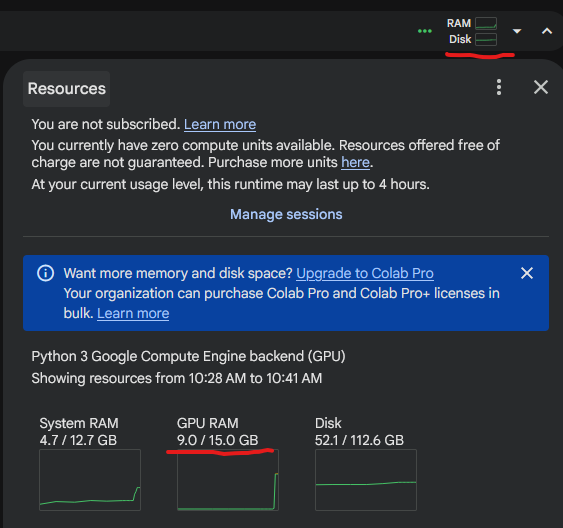

In [10]:
# This will take at least 5 minutes to run ｜ 至少要跑 5 分钟
# Take the time to search/google/use AI to understand what each of the variables going into this function do ｜ 每个参数的含义见右侧注释
geoai.train_segmentation_model(                      # 训练语义分割模型：每个像元判成背景或水
    images_dir=f"{tiles_dir}/images",                # 训练影像片
    labels_dir=f"{tiles_dir}/masks",                 # 对应标签片
    output_dir=f"{tiles_dir}/unet_models",           # 模型与训练历史的输出目录
    architecture="unet",                             # 解码结构：U-Net
    encoder_name="resnet34",                         # 编码器：ResNet34
    encoder_weights="imagenet",                      # 编码器用 ImageNet 预训练权重起步
    num_channels=6,                                  # 输入 6 个波段：蓝、绿、红、近红外、SWIR1、SWIR2
    num_classes=2,                                   # 两类：背景与水
    batch_size=8,                                    # 每批 8 片；两块 GPU 时每块 4 片
    num_epochs=3,                                    # 只训练 3 轮，演示用
    learning_rate=0.001,                             # 学习率：Adam 每步更新的步长，Q3 考点
    val_split=0.2,                                   # 两成切片留作验证，随机种子固定为 42
    verbose=True,                                    # 打印训练过程
)                                                    # 训练结束

print('Training complete!')                          # 提示训练完成

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Training complete!


In [11]:
# （自加）把训练历史 .pth 转成 JSON，带回本机重画出版级的图
def save_history(pth, name):                         # pth：geoai 存的历史文件；name：输出文件名
    h = torch.load(pth, map_location="cpu", weights_only=False)  # 读历史：每轮的 loss、IoU、F1、精度、召回
    out = {k: [float(x) for x in v] if isinstance(v, (list, tuple)) else str(v) for k, v in h.items()}  # 列表统一转成浮点
    json.dump(out, open(f"{OUT}/{name}.json", "w"), indent=1)  # 写盘
    return out                                       # 返回给后面用
hist_e3 = save_history(f"{tiles_dir}/unet_models/training_history.pth", "water_history_e3")  # 3 轮版
print({k: v[-1] for k, v in hist_e3.items() if isinstance(v, list) and v})  # 打印最后一轮

{'train_losses': 0.32713892668872685, 'val_losses': 0.1813322026282549, 'val_ious': 0.6780259916020391, 'val_f1s': 0.7503674276082163, 'val_precisions': 0.9158060443419473, 'val_recalls': 0.7473535044996716}


**Q2**: Explain why using U-Net and ResNet34 together is a good choice when working with multi-spectral imagery. Use at least two references in your response.

**答案 Q2**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

The two parts do different jobs that fit together. U-Net, introduced by Ronneberger, Fischer and Brox 2015 for segmentation from few labelled images, is an encoder decoder whose skip connections pass the high resolution feature maps of each encoder stage straight to the matching decoder stage. The decoder can therefore place a shoreline or a river bank at the exact pixel instead of producing the blurred blobs of an encoder alone. ResNet34, from He, Zhang, Ren and Sun 2016, is the encoder: its residual shortcuts let a 34 layer network train stably, and its ImageNet weights already detect edges, textures and shapes, so the 614 training tiles are enough to fine tune it rather than learn vision from scratch.

For multispectral imagery the pairing is efficient. The segmentation models library that GeoAI uses, Iakubovskii 2019, rebuilds the first convolution for six bands by repeating the pretrained red, green and blue filters across all six inputs and halving their weights, so the pretrained spatial filters survive while fine tuning learns how much to trust the near and shortwave infrared bands, in which open water absorbs almost all light. The whole model has 24.4 million parameters, 21.3 million of them in the encoder: deep enough to combine spectral evidence with spatial context, yet small enough to train in minutes on a T4 and less prone to overfitting 64 scenes than a ResNet101 encoder. Luo, Tong and Hu 2021, who built this Earth Surface Water dataset, likewise relied on an encoder decoder with skip connections, DeepLabv3+, for Sentinel 2 water mapping.

**References**

He, K., Zhang, X., Ren, S. and Sun, J. 2016. Deep residual learning for image recognition. Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition, 770 to 778. https://doi.org/10.1109/CVPR.2016.90

Iakubovskii, P. 2019. Segmentation Models Pytorch. GitHub repository. https://github.com/qubvel/segmentation_models.pytorch

Luo, X., Tong, X. and Hu, Z. 2021. An applicable and automatic method for earth surface water mapping based on multispectral images. International Journal of Applied Earth Observation and Geoinformation 103, 102472. https://doi.org/10.1016/j.jag.2021.102472

Ronneberger, O., Fischer, P. and Brox, T. 2015. U-Net: Convolutional networks for biomedical image segmentation. Medical Image Computing and Computer Assisted Intervention, Lecture Notes in Computer Science 9351, 234 to 241. https://doi.org/10.1007/978-3-319-24574-4_28


**Q3**: What is the learning_rate and what is the likely effect that reducing it will have on your model?

**答案 Q3**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

The learning rate is 0.001. It sets the size of every weight update: GeoAI trains with the Adam optimiser, which scales each gradient based step by this rate, and halves the rate automatically whenever the validation loss has not improved for more than five epochs. Reducing it would make each update smaller, so training would be steadier, with smoother loss curves and less risk of overshooting a good minimum, but slower: within the same three or ten epochs the model would probably end less well trained and would need more epochs to reach the same accuracy.


This model took me 4 to 6 minutes to run on the GPU. If it is taking you more than that, check that you are not still stuck using a CPU (it will take a LOT longer if on a CPU).

With one line of code, we can now take a look at the model performance:

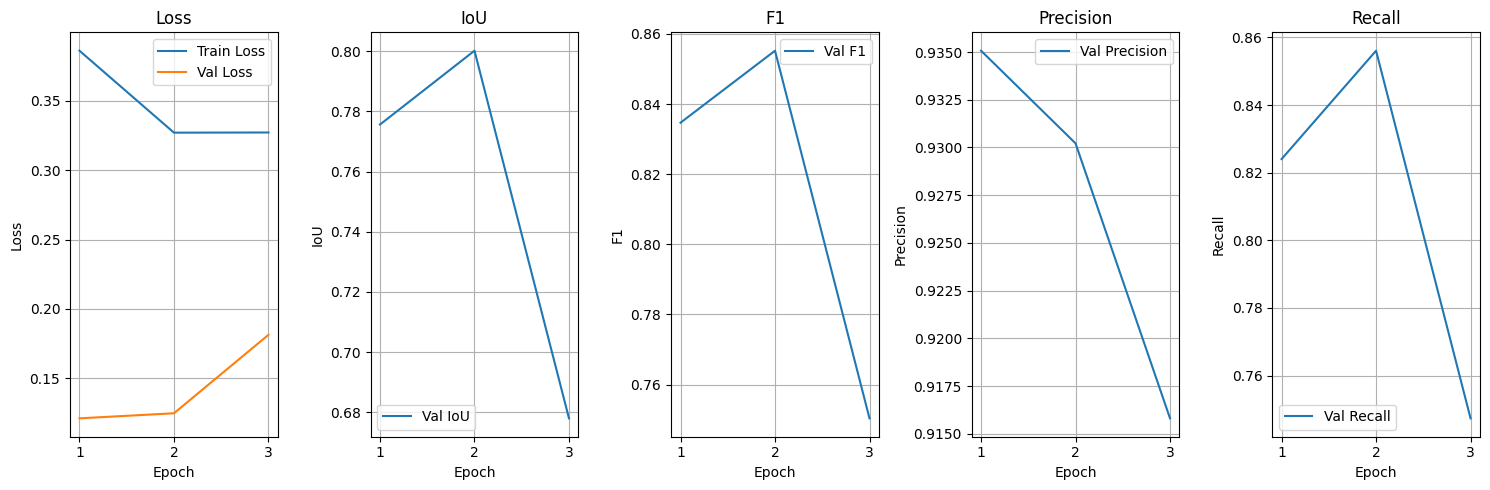

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.386065,0.121147,0.775614,0.834688,0.935072,0.824032
1,2,0.327011,0.124797,0.800138,0.855216,0.930217,0.856083
2,3,0.327139,0.181332,0.678026,0.750367,0.915806,0.747354


In [12]:
# Performance statistics ｜ 一行代码画出训练指标曲线
geoai.plot_performance_metrics(                      # 读训练历史并画 loss、IoU、F1、精度、召回
    history_path=f"{tiles_dir}/unet_models/training_history.pth",  # 训练历史文件
    figsize=(15, 5),                                 # 画幅
    verbose=True,                                    # 同时打印最佳值与最终值
    save_path=f"{OUT}/geoai_water_metrics_e3.png",   # 自加：存一份 PNG
)                                                    # 结束

**Q4**: Increase the number of training epochs to 10 (this will take some time, so maybe come back to this question later if need be). Present the resulting graphs of performance metrics in a figure and interpret the results for a technical audience (describe the training that has occured and make reccomendations for future training/use of the model). As always, figures should be of publication quality.

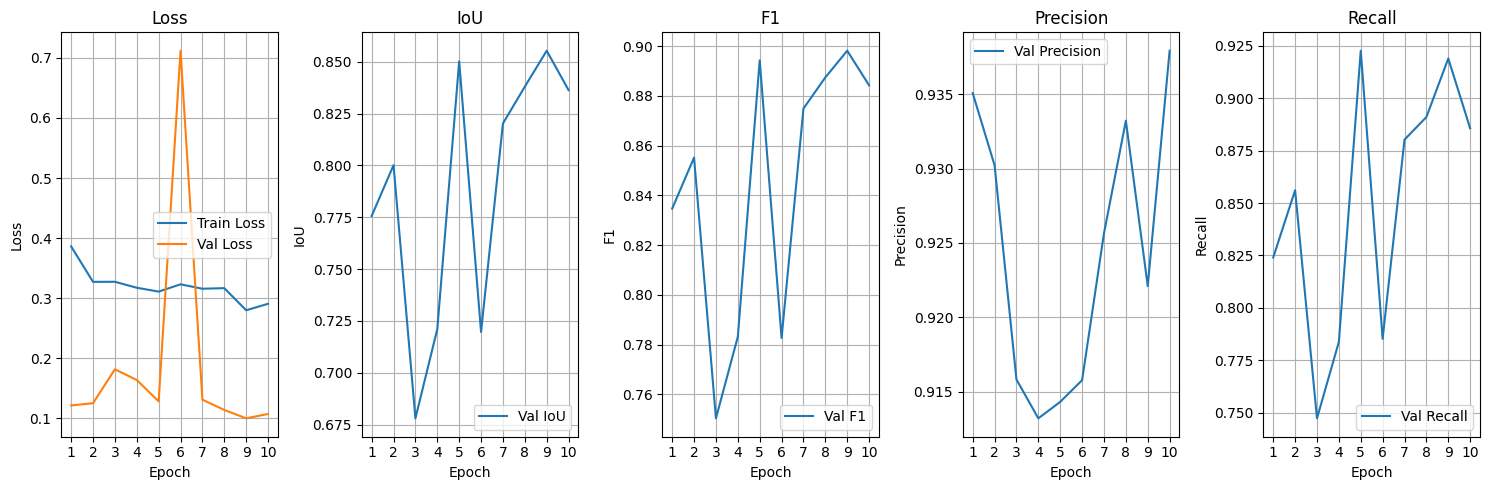

learning rate per epoch: [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.0005, 0.0005, 0.0005]


In [13]:
# （自加）Q4：只把轮数改成 10，其余参数与上面完全一致；输出到单独目录，3 轮版留作对照
geoai.train_segmentation_model(                      # 重新训练
    images_dir=f"{tiles_dir}/images",                # 同一批训练片
    labels_dir=f"{tiles_dir}/masks",                 # 同一批标签片
    output_dir=f"{tiles_dir}/unet_models_e10",       # 单独目录，不覆盖 3 轮版
    architecture="unet",                             # U-Net 结构
    encoder_name="resnet34",                         # ResNet34 编码器
    encoder_weights="imagenet",                      # ImageNet 预训练权重
    num_channels=6,                                  # 六个波段
    num_classes=2,                                   # 背景与水
    batch_size=8,                                    # 与上面一致
    num_epochs=10,                                   # 唯一改动：3 轮改成 10 轮
    learning_rate=0.001,                             # 与上面一致
    val_split=0.2,                                   # 与上面一致，种子相同所以划分相同
    verbose=True,                                    # 打印过程
)                                                    # 训练结束
hist_e10 = save_history(f"{tiles_dir}/unet_models_e10/training_history.pth", "water_history_e10")  # 存 10 轮历史
geoai.plot_performance_metrics(                      # geoai 自带的指标图，报告里用本机重画版
    history_path=f"{tiles_dir}/unet_models_e10/training_history.pth",  # 历史文件
    figsize=(15, 5),                                 # 画幅
    verbose=True,                                    # 打印最佳值与最终值
    save_path=f"{OUT}/geoai_water_metrics_e10.png",  # 存盘
)                                                    # 结束
# 学习率什么时候被减半：geoai 内部用 ReduceLROnPlateau，验证 loss 连续 5 轮以上没进步就乘 0.5。按记录的验证 loss 复演一遍
_opt = torch.optim.Adam([torch.zeros(1, requires_grad=True)], lr=0.001)  # 只为复演调度器的空优化器
_sch = torch.optim.lr_scheduler.ReduceLROnPlateau(_opt, mode="min", factor=0.5, patience=5)  # 与 geoai 相同的设置
lr_used = []                                         # 每一轮实际使用的学习率
for v in hist_e10["val_losses"]:                     # 逐轮
    lr_used.append(_opt.param_groups[0]["lr"])       # 这一轮训练时的学习率
    _sch.step(v)                                     # 轮末按验证 loss 更新
print("learning rate per epoch:", lr_used)           # 打印
json.dump(lr_used, open(f"{OUT}/water_lr_e10.json", "w"))  # 写盘

**答案 Q4**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

Figure 1 shows the ten epoch run. GeoAI fixes the random seed, so its first three epochs repeat the three epoch run exactly. Training loss falls from 0.386 to 0.327 by epoch 2 and then stays near 0.32 until GeoAI's plateau scheduler halves the learning rate to 0.0005 after epoch 7, after which it reaches 0.280 by epoch 9. The validation curves are noisy: IoU drops to 0.678 at epoch 3 and validation loss spikes to 0.712 at epoch 6, which suggests that a step of 0.001 with batches of eight tiles is too large for stable fine tuning. The saved `best_model` is epoch 9, with a validation loss of 0.100 and an IoU of 0.855, against 0.800 at the best epoch of the three epoch run.

There is no sign of overfitting: apart from the epoch 6 spike, validation loss stays below training loss, because augmentation is applied only to training tiles and the validation tiles come from the same 64 scenes and overlap the training tiles, which also makes these curves optimistic. GeoAI's scores are averages over the water and background classes and over tiles, so I also scored the 31 unseen validation scenes, pooling all of their pixels. There the ten epoch model reaches a water IoU of 0.928 against 0.919, with recall rising from 0.934 to 0.967 and precision falling from 0.983 to 0.958: the extra epochs mainly teach the model to claim thin and marginal water.

For future training I recommend more epochs with early stopping on validation loss, a lower or decaying learning rate such as 0.0001, validation on whole held out scenes, monitoring the IoU of the water class rather than the class average, and proper scaling of the 16 bit reflectance, which GeoAI simply divides by 255. In use, the model can be trusted for lakes, reservoirs and rivers three or more pixels wide, but not for ponds under about 0.1 hectare.

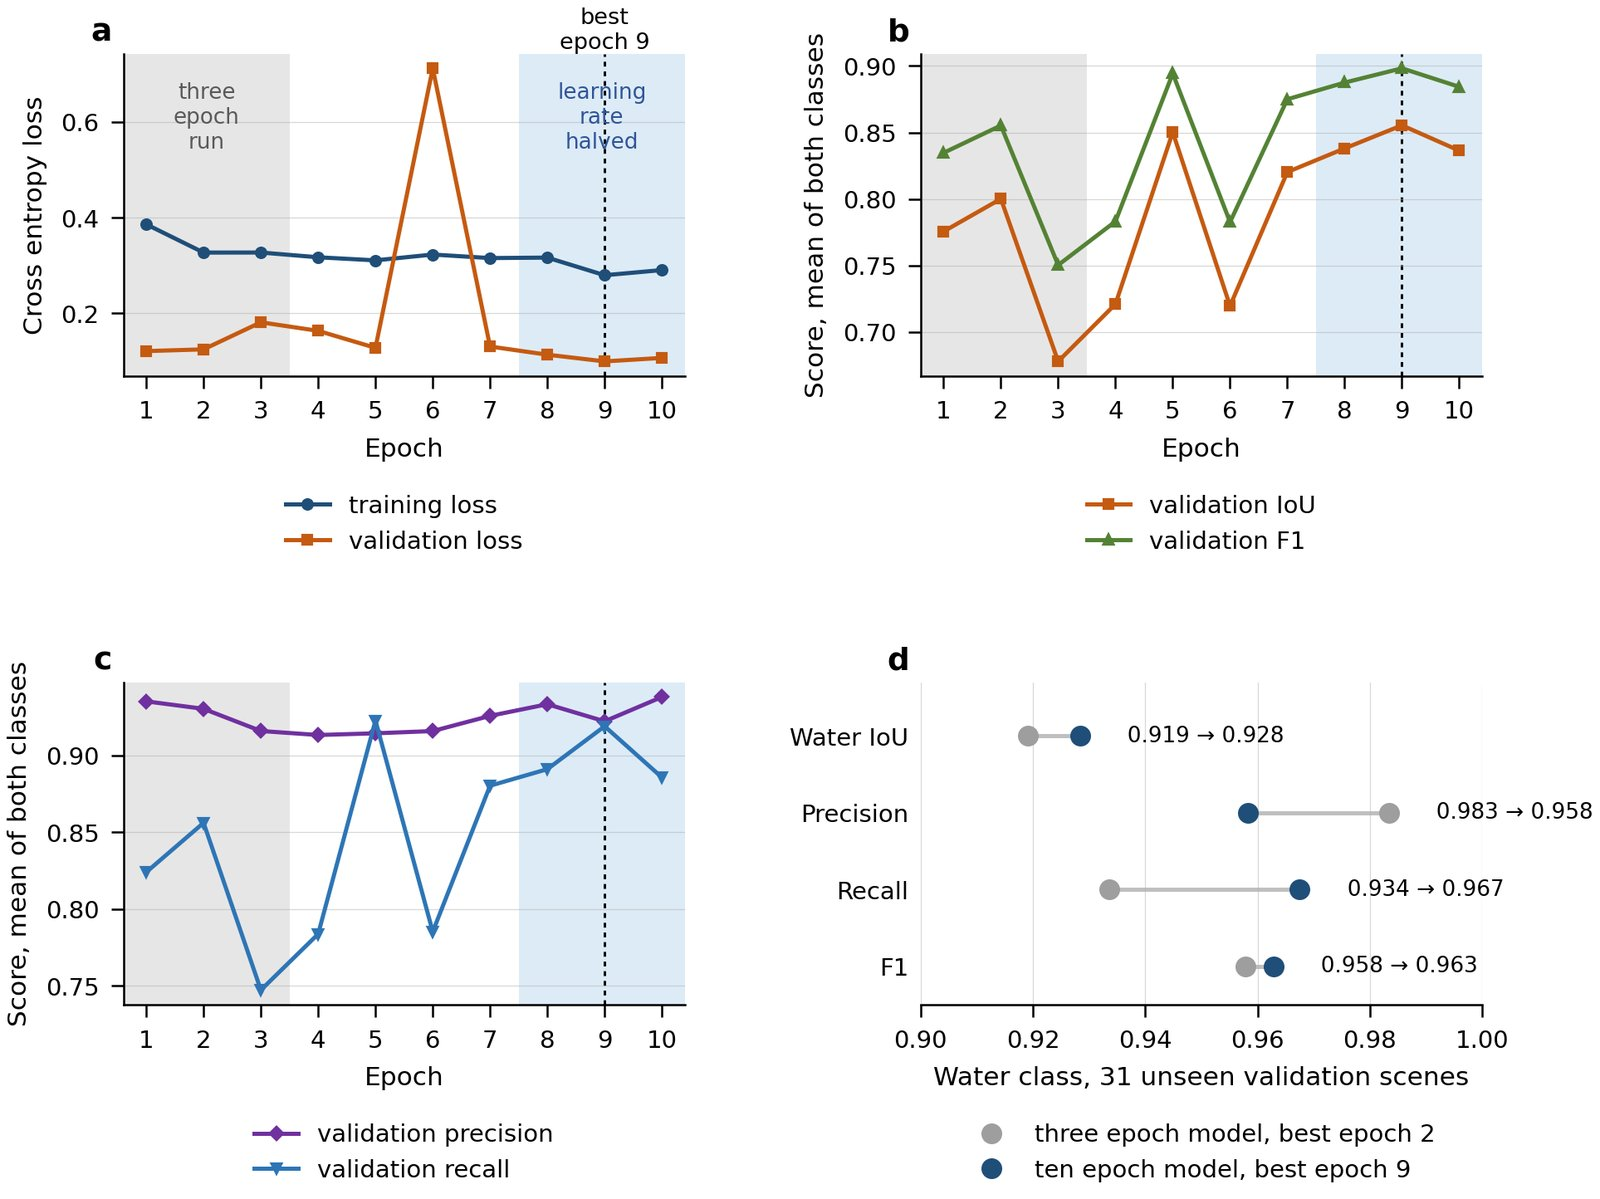

*training of the water segmentation model for ten epochs with all other settings unchanged. a to c: loss and the validation scores that GeoAI reports, which average the water and background classes over validation tiles. Grey shading marks the first three epochs, identical to the three epoch run, blue shading the epochs after the learning rate was halved, and the dotted line the best epoch saved as best_model. d: water class scores of the two saved models, pooled over every pixel of the 31 validation scenes.*


In addition to these performance statistics, we can run [inference](https://www.cloudflare.com/learning/ai/inference-vs-training/) on the validation set to evaluate the model's performance. We will use the semantic_segmentation_batch function to process all the validation images at once.

In [14]:
images_dir = f"{data_dir}/dset-s2/val_scene"         # 验证场景：训练时完全没见过的另外 31 景
masks_dir = f"{data_dir}/dset-s2/val_truth"          # 验证真值
predictions_dir = f"{data_dir}/dset-s2/predictions"  # 预测输出目录
model_path = f"{tiles_dir}/unet_models_e10/best_model.pth"  # 用 Q4 的 10 轮最优模型；原模板这里是 3 轮版 unet_models

In [15]:
geoai.semantic_segmentation_batch(                   # 对目录里的每一景做推理
    input_dir=images_dir,                            # 输入：验证场景
    output_dir=predictions_dir,                      # 输出：每景一张掩膜，文件名为原名加 _mask
    model_path=model_path,                           # 模型权重
    architecture="unet",                             # 与训练一致
    encoder_name="resnet34",                         # 与训练一致
    num_channels=6,                                  # 与训练一致
    num_classes=2,                                   # 与训练一致
    window_size=512,                                 # 滑动窗口大小，等于训练切片大小
    overlap=128,                                     # 相邻窗口重叠 128 像素，重叠区按离窗口边缘的距离加权平均，消除接缝
    batch_size=4,                                    # 每批 4 个窗口
    quiet=True,                                      # 不显示进度条
)                                                    # 推理结束

In [16]:
# （自加）3 轮版也推理一遍，后面逐景算指标做对比
geoai.semantic_segmentation_batch(                   # 推理设置与上一格完全相同
    input_dir=images_dir,                            # 验证场景
    output_dir=f"{data_dir}/dset-s2/predictions_e3",  # 单独目录
    model_path=f"{tiles_dir}/unet_models/best_model.pth",  # 3 轮版权重
    architecture="unet",                             # 一致
    encoder_name="resnet34",                         # 一致
    num_channels=6,                                  # 一致
    num_classes=2,                                   # 一致
    window_size=512,                                 # 一致
    overlap=128,                                     # 一致
    batch_size=4,                                    # 一致
    quiet=True,                                      # 不显示进度条
)                                                    # 结束

And then visualize the results of this!

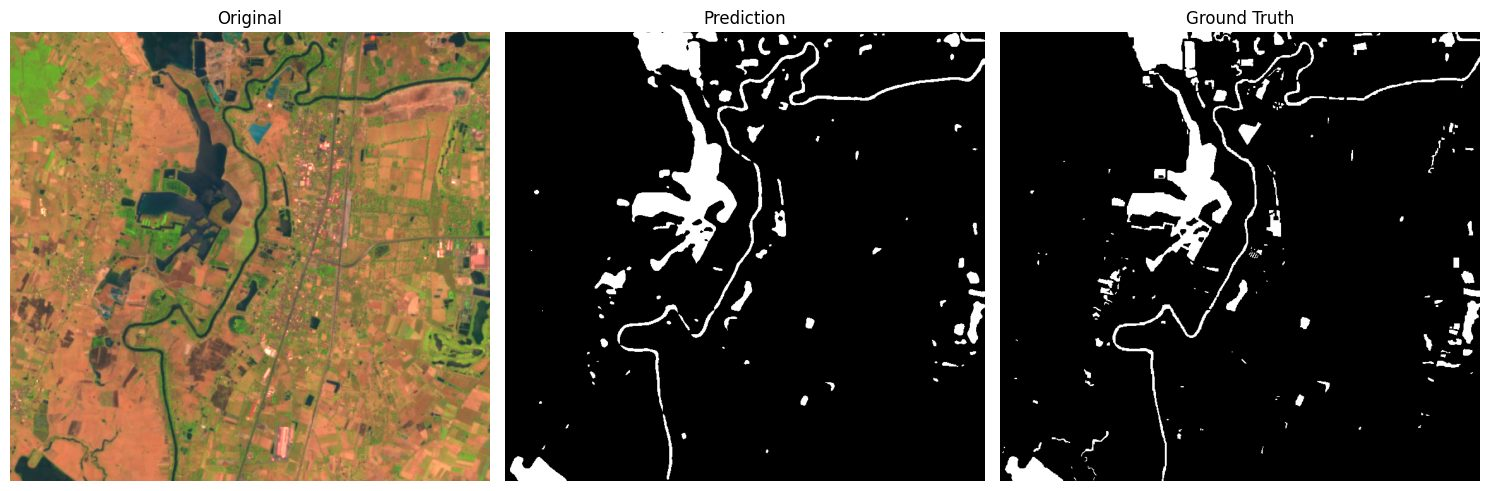

'lab5_out/geoai_water_comparison.png'

In [17]:
# Visualize inference outcomes ｜ 可视化推理结果：原图、预测、真值三联
image_id = "S2A_L2A_20190318_N0211_R061"  # Change to other image id, e.g., S2B_L2A_20190620_N0212_R047 ｜ 可以换成别的景号
test_image_path = f"{data_dir}/dset-s2/val_scene/{image_id}_6Bands_S2.tif"  # 原图路径
ground_truth_path = f"{data_dir}/dset-s2/val_truth/{image_id}_S2_Truth.tif"  # 真值路径
prediction_path = f"{data_dir}/dset-s2/predictions/{image_id}_6Bands_S2_mask.tif"  # 预测路径
save_path = f"{data_dir}/dset-s2/{image_id}_6Bands_S2_comparison.png"  # 对比图存盘位置

fig = geoai.plot_prediction_comparison(              # 三联对比图
    original_image=test_image_path,                  # 原图
    prediction_image=prediction_path,                # 预测
    ground_truth_image=ground_truth_path,            # 真值
    titles=["Original", "Prediction", "Ground Truth"],  # 三个子图标题
    figsize=(15, 5),                                 # 画幅
    save_path=save_path,                             # 存盘
    show_plot=True,                                  # 同时显示
    indexes=[5, 4, 3],                               # 第 5、4、3 波段 = SWIR1、近红外、红：水在这个假彩色里是深蓝近黑
    divider=5000,                                    # 反射率乘了 10000 存储，除以 5000 做显示拉伸
)                                                    # 结束
shutil.copy(save_path, f"{OUT}/geoai_water_comparison.png")  # 自加：拷一份到产物目录

In [18]:
# （自加）Q5 用：逐景只算「水」这一类的 IoU、精度、召回。
# geoai 训练时报的 IoU 是背景与水两类的平均，而且按切片平均，没有水的切片几乎白送 1 分，所以会偏高。
def water_scores(pred_dir):                          # 对一个预测目录逐景统计混淆矩阵
    rows = []                                        # 每景一行
    for f in sorted(glob.glob(f"{images_dir}/*_6Bands_*.tif")):  # 遍历 31 景验证影像
        base = os.path.basename(f)                   # 文件名
        stem, sub = re.match(r"(.*)_6Bands_(S\d+)\.tif$", base).groups()  # 拆出景号与子块号
        with rasterio.open(f"{masks_dir}/{stem}_{sub}_Truth.tif") as s:  # 对应真值
            t = s.read(1) == 1                       # 真值：1 = 水
        with rasterio.open(f"{pred_dir}/{base[:-4]}_mask.tif") as s:  # 对应预测，geoai 命名为原名加 _mask
            p = s.read(1) == 1                       # 预测：1 = 水
        rows.append(dict(scene=f"{stem}_{sub}", tp=int((p & t).sum()), fp=int((p & ~t).sum()), fn=int((~p & t).sum()), tn=int((~p & ~t).sum())))  # 混淆矩阵四格
    return rows                                      # 返回逐景结果

def summarise(rows):                                 # 把全部像元合在一起再算指标
    tp, fp, fn, tn = (sum(r[k] for r in rows) for k in ("tp", "fp", "fn", "tn"))  # 四格求和
    iou_w, iou_b = tp / (tp + fp + fn), tn / (tn + fp + fn)  # 水的 IoU、背景的 IoU
    return dict(water_iou=iou_w, precision=tp / (tp + fp), recall=tp / (tp + fn), f1=2 * tp / (2 * tp + fp + fn), mean_iou_2class=(iou_w + iou_b) / 2, water_share=(tp + fn) / (tp + fp + fn + tn))  # 各项指标

scores = {}                                          # 两个模型的结果
for tag, d in [("e3", f"{data_dir}/dset-s2/predictions_e3"), ("e10", predictions_dir)]:  # 3 轮与 10 轮
    rows = water_scores(d)                           # 逐景统计
    for r in rows:                                   # 每景也算一个水的 IoU
        r["water_iou"] = r["tp"] / max(1, r["tp"] + r["fp"] + r["fn"])  # 防止除以 0
    scores[tag] = dict(pooled=summarise(rows), scenes=rows)  # 存下
    print(tag, {k: round(v, 4) for k, v in scores[tag]["pooled"].items()})  # 打印汇总
for tag in ("e3", "e10"):                            # 示例场景单独打印
    ex = [r for r in scores[tag]["scenes"] if r["scene"] == f"{image_id}_S2"][0]  # 题目里的示例场景
    print(tag, "example scene:", ex)                 # 打印
json.dump(scores, open(f"{OUT}/water_val_scores.json", "w"), indent=1)  # 写盘

e3 {'water_iou': 0.919, 'precision': 0.9834, 'recall': 0.9336, 'f1': 0.9578, 'mean_iou_2class': 0.9491, 'water_share': 0.2047}


e10 {'water_iou': 0.9284, 'precision': 0.9583, 'recall': 0.9675, 'f1': 0.9629, 'mean_iou_2class': 0.9547, 'water_share': 0.2047}
e3 example scene: {'scene': 'S2A_L2A_20190318_N0211_R061_S2', 'tp': 17448, 'fp': 207, 'fn': 21876, 'tn': 500829, 'water_iou': 0.441375123320938}
e10 example scene: {'scene': 'S2A_L2A_20190318_N0211_R061_S2', 'tp': 34479, 'fp': 4624, 'fn': 4845, 'tn': 496412, 'water_iou': 0.7845408209702376}


In [19]:
# （自加）Q5 用：按离岸距离和水体大小拆开，看漏判集中在哪里：窄河道还是大池塘
from scipy import ndimage                            # 连通域标记、距离变换
with rasterio.open(ground_truth_path) as s:          # 示例场景真值
    t = s.read(1) == 1                               # 水 = True
with rasterio.open(prediction_path) as s:            # 示例场景预测，10 轮模型
    p = s.read(1) == 1                               # 水 = True
depth = ndimage.distance_transform_edt(t)            # 每个水像元到最近岸边的距离，单位像元，1 = 贴岸那一圈
for lo, hi in [(1, 1), (2, 2), (3, 4), (5, 1e9)]:    # 按离岸距离分档
    sel = (depth >= lo) & (depth <= hi)              # 这一档的真值水像元
    print(f"distance to shore {lo}-{hi if hi < 1e9 else 'inf'} px: n={int(sel.sum()):6d}, recall={p[sel].mean():.3f}")  # 这一档被找回的比例
lab, n = ndimage.label(t, structure=np.ones((3, 3)))  # 真值水体按 8 邻域分成独立水体
idx = np.arange(1, n + 1)                            # 水体编号
size = ndimage.sum(t, lab, idx)                      # 每个水体的像元数，1 像元 = 100 m2
hit = ndimage.sum(p, lab, idx)                       # 每个水体里被预测成水的像元数
halfw = ndimage.maximum(depth, lab, idx)             # 每个水体的最大离岸距离，约等于半宽
for lo, hi in [(1, 9), (10, 99), (100, 999), (1000, 1e9)]:  # 按面积分档
    sel = (size >= lo) & (size <= hi)                # 这一档的水体
    if sel.any():                                    # 有才打印
        print(f"bodies {lo}-{hi if hi < 1e9 else 'inf'} px: n={int(sel.sum()):4d}, px={int(size[sel].sum()):6d}, recall={hit[sel].sum() / size[sel].sum():.3f}, missed entirely={np.mean(hit[sel] == 0):.0%}")  # 召回率与完全漏掉的比例
for i in np.argsort(size)[::-1][:6]:                 # 最大的 6 个水体逐个看
    print(f"  body {i + 1}: {int(size[i])} px, max half width {halfw[i]:.1f} px, recall {hit[i] / size[i]:.3f}")  # 面积、半宽、召回
far = ndimage.distance_transform_edt(~t)             # 非水像元到最近真水的距离
fpm = p & ~t                                         # 误报像元
print(f"false positives {int(fpm.sum())} px; within 2 px of true water {np.mean(far[fpm] <= 2):.0%}")  # 误报是贴着水边还是凭空出现

distance to shore 1-1 px: n=  9632, recall=0.631
distance to shore 2-2 px: n=  4740, recall=0.893
distance to shore 3-4 px: n=  4149, recall=0.980
distance to shore 5-inf px: n= 14255, recall=0.994
bodies 1-9 px: n=  45, px=   256, recall=0.109, missed entirely=89%
bodies 10-99 px: n=  83, px=  2671, recall=0.482, missed entirely=36%
bodies 100-999 px: n=  43, px= 11897, recall=0.817, missed entirely=2%
bodies 1000-inf px: n=   5, px= 24500, recall=0.957, missed entirely=0%
  body 27: 13486 px, max half width 24.4 px, recall 0.962
  body 1: 4462 px, max half width 40.3 px, recall 0.979
  body 16: 2405 px, max half width 3.0 px, recall 0.926
  body 171: 2119 px, max half width 25.8 px, recall 0.978
  body 122: 2028 px, max half width 4.0 px, recall 0.886
  body 120: 997 px, max half width 8.2 px, recall 0.898
false positives 4624 px; within 2 px of true water 83%


**Q5**: Discuss the performance of the prediction in our example given above. Do so in reference to the ability of the prediction to resolve key features as compared to the ground truth (e.g. the river vs. the flood ponds). Explain why perfomance is varying in terms of both satellite data physical principles and the limitations of model and its training.

**答案 Q5**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

The example scene covers 7.6 by 7.1 km near Tha Phra in northeast Thailand on 18 March 2019, in the dry season. Water fills 7.3 percent of it in 176 bodies, from a 1.35 square kilometre reservoir to single pixel ponds, plus a meandering river about three pixels, 30 m, wide. Figure 2 shows how differently the two models resolve them. The three epoch model finds the interiors of the reservoir and lakes but misses the river entirely: it recovers none of the river, 3 percent of shoreline pixels and almost none of the ponds under 100 pixels, for a water IoU of 0.44. After ten epochs the river is traced along its whole length, with 91 percent of its pixels found, the large bodies reach 97 percent and the IoU rises to 0.78. What remains is spatially organised: pixels five or more pixels from shore are found 99 percent of the time but the shoreline ring only 63 percent, 89 percent of ponds under 10 pixels, 0.1 hectare, are missed entirely, and 83 percent of the false water lies within two pixels of real water.

The physics explains this ranking. Open water absorbs almost all near and shortwave infrared light, so a pure water pixel is dark in bands 8, 11 and 12 and easy to separate, which is why reservoir interiors are learned first. A 10 m pixel on a shoreline, in a three pixel river or in a small pond mixes water with bank soil and vegetation, pushing its infrared reflectance towards that of land, and the two shortwave bands, the most diagnostic for water, were recorded at 20 m and resampled, which blurs every edge by about another pixel. Shallow, turbid or weedy dry season ponds, turquoise in the composite, are also brighter in red and near infrared than open water.

The model compounds these limits. Cross entropy averaged over all pixels is dominated by the large water bodies and the background, so missing a small pond costs almost nothing; the ResNet34 encoder downsamples 32 times, so features a few pixels across survive only through the skip connections, which need more training to exploit, as the jump from three to ten epochs shows; and the model saw only 614 tiles from 64 scenes. Finally, the truth was digitised at 10 m, so a one pixel disagreement at a shoreline is partly label uncertainty rather than model error.

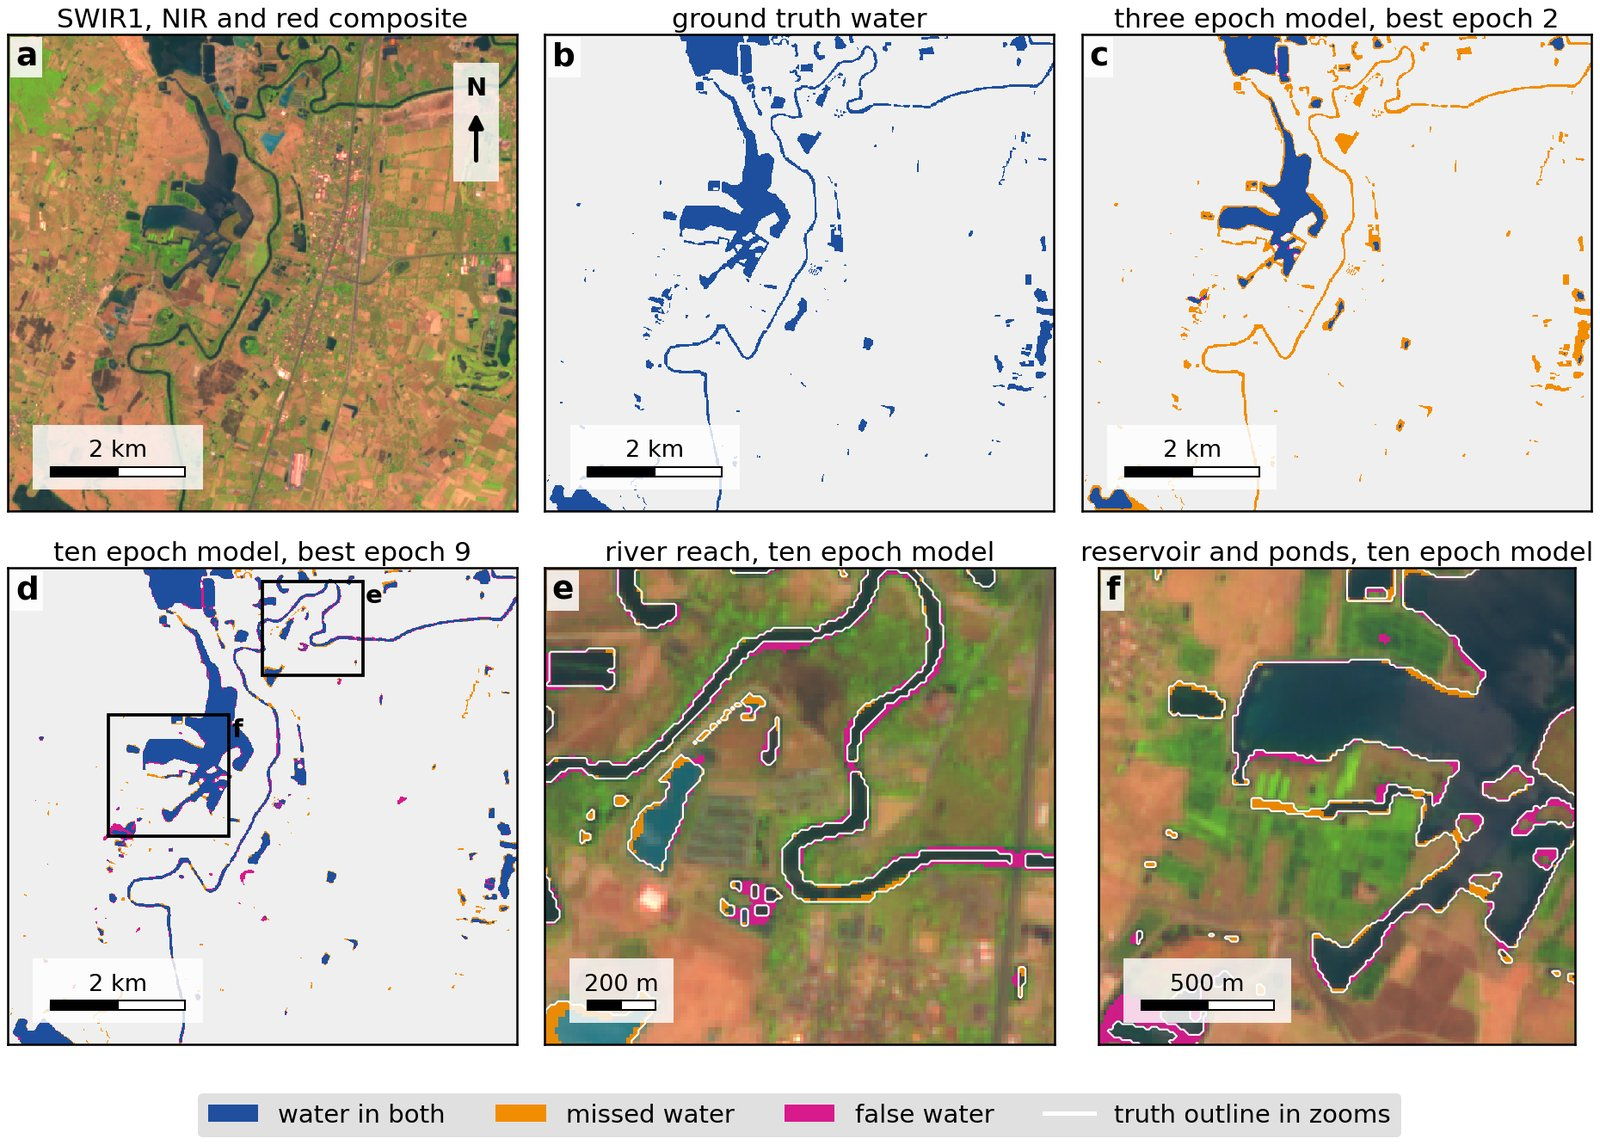

*validation scene S2A L2A 20190318 R061, subscene S2, near Tha Phra, Thailand. a: SWIR1, NIR and red composite in which water is dark. b: ground truth. c and d: agreement between prediction and truth for the three epoch and ten epoch models. e and f: the ten epoch errors over the river reach and over the reservoir margin and its ponds, with the truth outlined in white.*


Hopefully you can now see the difference that GeoAI makes to your workflow as compared to what we have gone through in the other labs.

Their library is doing a lot of the plumbing and model management for you behind the scenes, allowing you to write faster and solve different problems rather than getting stuck in the weeds. We have only imported one library to accomplish something that before we were using 5 or 6 to do. This does come with drawbacks, choices have been made for you- but particuarly for quick prototyping this is a strong advantage.

Note that the GeoAI tutorial also shows you [how to gather satellite data](https://opengeoai.org/workshops/TNView_2025/#download-sentinel-2-imagery) from a [STAC catalgoue](https://stacspec.org/en). This is the alternative (to the GEE approach used to date) way to build satellite data stacks for use in your project. Might well be useful for you in your projects...

# Task 2: Detecting solar panels from aerial imagery
In Task 1 we used semantic segmentation to classify pixels in satellite imagery. In this task we use a similar deep-learning workflow to identify solar panels in high-resolution aerial imagery, but then move from pixels to individual mapped objects.

The important distinction is that the U-Net produces a pixel-level segmentation. We will then convert that segmentation into polygons and use the geometry of those polygons to remove some of the small or implausible detections. This gives us a simple object-level workflow without introducing a separate object-detection model.

Before starting this task, clear the cache and make sure your RAM is empty from Task 1, or you may crash the Colab instance.

We will work with a labelled training image and vector dataset from Davis, California, and a separate aerial image for testing. The data are provided through [Hugging Face](https://huggingface.co/).

First, we will clear the data and model from Task 1 from our memory. You always want to make sure that a fresh model run has a clean memory to use, as otherwise these free instances will very quickly beocome jammed up and crash:

In [20]:
# Clear memory before starting Task 2 ｜ 开始任务 2 前先清内存
import gc                                            # Python 垃圾回收模块

# Python garbage collection ｜ 回收不再引用的对象
gc.collect()                                         # 立即回收

# Clear PyTorch GPU memory ｜ 清 GPU 缓存
if torch.cuda.is_available():                        # 有 GPU
    torch.cuda.empty_cache()                         # 释放 PyTorch 缓存的显存
    torch.cuda.ipc_collect()                         # 回收进程间共享的显存

# Report current GPU memory ｜ 报告当前显存占用
if torch.cuda.is_available():                        # 有 GPU
    allocated = torch.cuda.memory_allocated() / 1024**3  # 已分配显存，单位 GB
    reserved = torch.cuda.memory_reserved() / 1024**3  # 已保留显存，单位 GB

    print("Memory cleared.")                         # 提示
    print(f"GPU memory allocated: {allocated:.2f} GB")  # 打印已分配
    print(f"GPU memory reserved:  {reserved:.2f} GB")  # 打印已保留
else:                                                # 没有 GPU
    print("Memory cleared. No CUDA GPU detected.")   # 提示

Memory cleared.
GPU memory allocated: 0.00 GB
GPU memory reserved:  0.00 GB


Next, we specify our data sources and then download them:

In [21]:
# Set the URLS that you are getting the data from ｜ 数据地址
train_raster_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_davis_ca.tif"  # 训练影像：加州 Davis 的高分辨率航拍 RGB
train_vector_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_davis_ca.geojson"  # 训练标注：光伏板多边形
test_raster_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_test_davis_ca.tif"  # 测试影像：模型没见过，且没有标注

In [22]:
# Use GeoAI to download them ｜ 用 GeoAI 下载
train_raster_path = geoai.download_file(train_raster_url)  # 下载训练影像，返回本地路径
train_vector_path = geoai.download_file(train_vector_url)  # 下载训练标注
test_raster_path = geoai.download_file(test_raster_url)  # 下载测试影像

Let's take a look at it using our own interactive view tool.


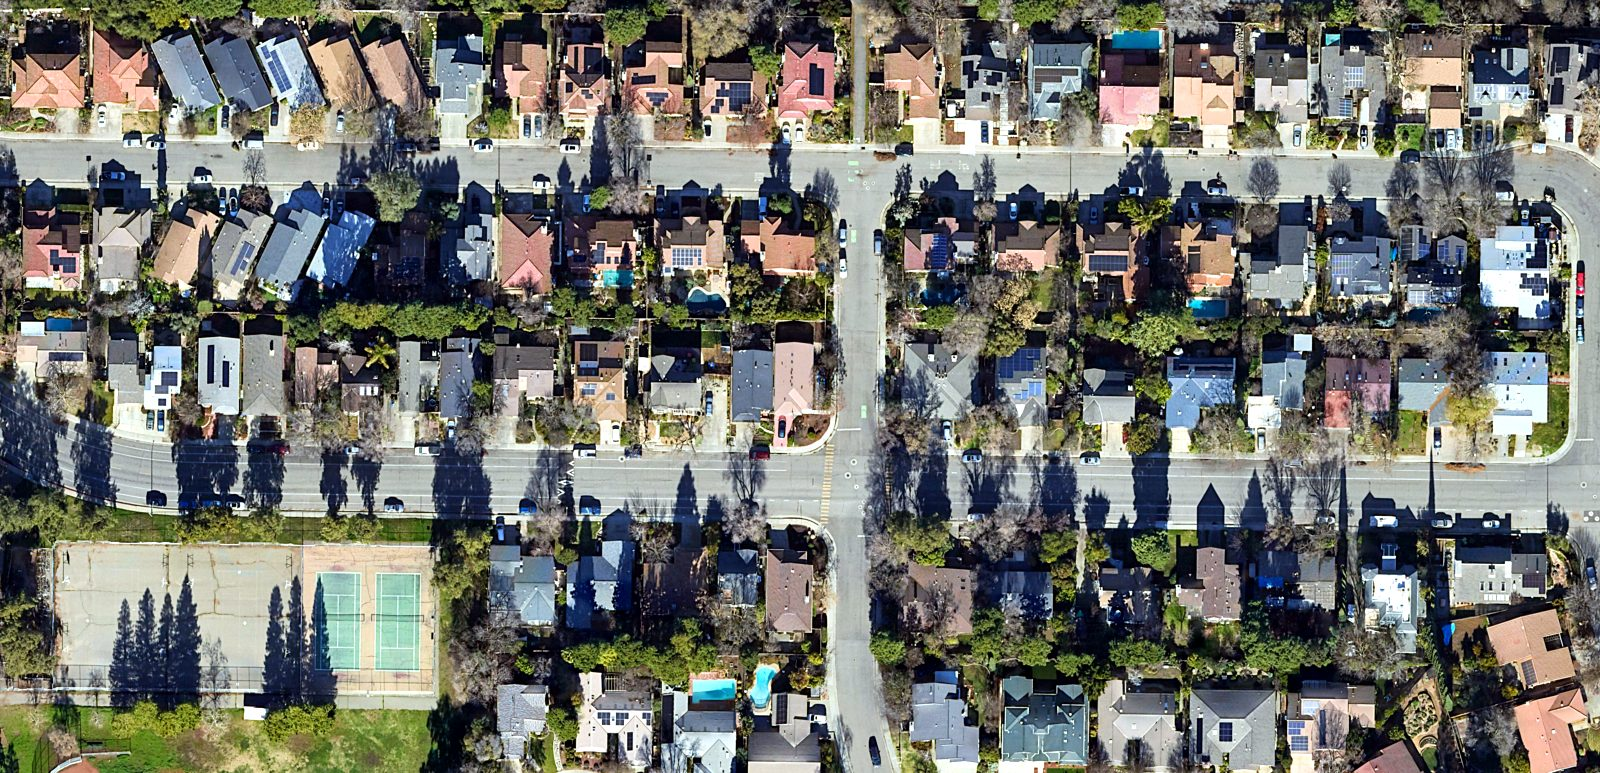

In [23]:
show_interactive(raster=train_raster_path, vector=train_vector_path, title="Training scene")  # 交互查看训练影像与标注多边形

In [24]:
# （自加）Task 2 的地理口径：影像是 Web Mercator，坐标里的「米」在戴维斯被放大 1/cos(纬度) 倍
from scipy import ndimage                            # 距离变换、连通域
from rasterio.warp import transform as warp_xy       # 坐标转换
def ground_pixel(path):                              # 返回影像中心纬度与真实地面分辨率
    with rasterio.open(path) as s:                   # 打开
        cx, cy = s.xy(s.height // 2, s.width // 2)   # 中心点坐标
        lon, lat = warp_xy(s.crs, "EPSG:4326", [cx], [cy])  # 转经纬度
        return lat[0], s.res[0] * math.cos(math.radians(lat[0]))  # 地面米 = 墨卡托米 x cos(纬度)
lat_tr, gsd_tr = ground_pixel(train_raster_path)     # 训练影像
lat_te, gsd_te = ground_pixel(test_raster_path)      # 测试影像
print(f"train: lat {lat_tr:.4f}, ground pixel {gsd_tr * 100:.2f} cm; test: lat {lat_te:.4f}, ground pixel {gsd_te * 100:.2f} cm")  # 打印
print(f"Mercator area inflation 1/cos^2(lat) = {1 / math.cos(math.radians(lat_te)) ** 2:.3f}")  # 面积放大倍数

train: lat 38.5530, ground pixel 5.84 cm; test: lat 38.5516, ground pixel 5.84 cm
Mercator area inflation 1/cos^2(lat) = 1.635


In [25]:
# （自加）Q6 用：把标注栅格化，量化光伏板与紧邻屋顶、远处地物在亮度、颜色、纹理上的差别
from rasterio.features import rasterize              # 多边形转栅格
with rasterio.open(train_raster_path) as src:        # 训练影像
    img = src.read().astype(np.float32)              # RGB 三波段，0~255
    tr_r, crs_r = src.transform, src.crs             # 地理参考
lab_gdf = gpd.read_file(train_vector_path).to_crs(crs_r)  # 标注转到影像坐标系
panel = rasterize(((g, 1) for g in lab_gdf.geometry), out_shape=img.shape[1:], transform=tr_r, dtype="uint8").astype(bool)  # 光伏像元掩膜
dist_m = ndimage.distance_transform_edt(~panel) * gsd_tr  # 每个像元到最近光伏板的地面距离，米
ring = (dist_m > 0.3) & (dist_m <= 1.5)              # 板外 0.3~1.5 m 一圈，基本就是承载它的屋顶
far = dist_m > 5                                     # 5 m 以外：道路、植被、其他屋顶
bright = img.mean(0)                                 # 亮度：RGB 平均
blue = img[2] / (img.sum(0) + 1e-6)                  # 蓝色占比：色度，与亮度无关
sat = (img.max(0) - img.min(0)) / (img.max(0) + 1e-6)  # 饱和度
m1 = ndimage.uniform_filter(bright, 7)               # 7 x 7 窗口均值，约 40 cm 见方
m2 = ndimage.uniform_filter(bright ** 2, 7)          # 7 x 7 窗口平方均值
tex = np.sqrt(np.maximum(m2 - m1 ** 2, 0))           # 局部标准差：纹理强度，组件之间的栅格线会抬高它
q6 = {}                                              # 三类区域的统计
for name, sel in [("panel", panel), ("adjacent_roof", ring), ("elsewhere", far)]:  # 逐类
    q6[name] = {k: float(np.median(v[sel])) for k, v in [("brightness", bright), ("blue_share", blue), ("saturation", sat), ("texture_std", tex)]}  # 各指标中位数
    q6[name]["px"] = int(sel.sum())                  # 像元数
lab_utm = lab_gdf.to_crs(lab_gdf.estimate_utm_crs())  # 转 UTM 得真实面积
rect = lab_utm.area / lab_utm.geometry.apply(lambda g: g.minimum_rotated_rectangle.area)  # 矩形度：面积除以最小外接矩形面积
q6["labels"] = dict(n=len(lab_utm), area_m2_min=float(lab_utm.area.min()), area_m2_median=float(lab_utm.area.median()), area_m2_max=float(lab_utm.area.max()), rectangularity_median=float(rect.median()), panel_share_of_scene=float(panel.mean()))  # 标注的面积与形状
json.dump(q6, open(f"{OUT}/solar_q6_stats.json", "w"), indent=1)  # 写盘
print(json.dumps(q6, indent=1))                      # 打印
del img, bright, blue, sat, m1, m2, tex, dist_m      # 释放大数组

{
 "panel": {
  "brightness": 70.0,
  "blue_share": 0.4639498293399811,
  "saturation": 0.4639175236225128,
  "texture_std": 10.476268768310547,
  "px": 288706
 },
 "adjacent_roof": {
  "brightness": 147.0,
  "blue_share": 0.3380884528160095,
  "saturation": 0.171171173453331,
  "texture_std": 13.190128326416016,
  "px": 453268
 },
 "elsewhere": {
  "brightness": 102.66666412353516,
  "blue_share": 0.34437087178230286,
  "saturation": 0.2211981564760208,
  "texture_std": 10.296032905578613,
  "px": 19298416
 },
 "labels": {
  "n": 67,
  "area_m2_min": 1.510722648320651,
  "area_m2_median": 12.856961015300675,
  "area_m2_max": 46.73369896911655,
  "rectangularity_median": 0.9411407202083335,
  "panel_share_of_scene": 0.013269530601144585
 }
}


Q6: Examine the training image and labelled polygons. What visual characteristics distinguish the solar panels from the surrounding roofs, roads and vegetation? Identify at least two characteristics that a convolutional neural network could potentially learn from the imagery.

**答案 Q6**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

Three properties set the panels apart in this imagery, and each is something a convolutional network can learn from the three RGB bands. The first is tone and colour. Labelled panel pixels have a median brightness of 70 on the 0 to 255 scale against 147 for the roof within 1.5 m of each array, and they are distinctly blue: their median blue share is 0.46 against 0.34 for both the adjacent roof and the rest of the scene, and their saturation is 0.46 against 0.17. Roofs, roads and lawns are grey, brown or green and far less saturated, so first layer filters tuned to dark saturated blue already discriminate, as Figure 3 shows.

The second is geometry. The 67 labelled arrays are compact objects between 1.5 and 47 square metres with a median rectangularity of 0.94: straight edges parallel to the roof edges and ridges, right angled corners, and larger arrays assembled from rectangles into L and stepped shapes. Deeper filters with wider receptive fields can learn these straight parallel edges, which tree crowns, shadows and lawns never have.

The third is texture and context. At about 6 cm per pixel the frames between modules show as a regular grid of lighter lines inside each dark rectangle, and every array sits on a roof plane, set back from its edge. A 512 pixel tile covers about 30 m, a whole house, so the U-Net can learn that a dark grid on a roof is a panel while an equally dark tree shadow on a lawn or road is not. The figure also shows where the cues weaken: arrays on dark grey roofs or under shade lose their tonal contrast, a few arrays glint and appear light grey, and dark roof planes and skylights share the rectangular shape, so the network has to combine colour, shape and texture rather than rely on any one of them.

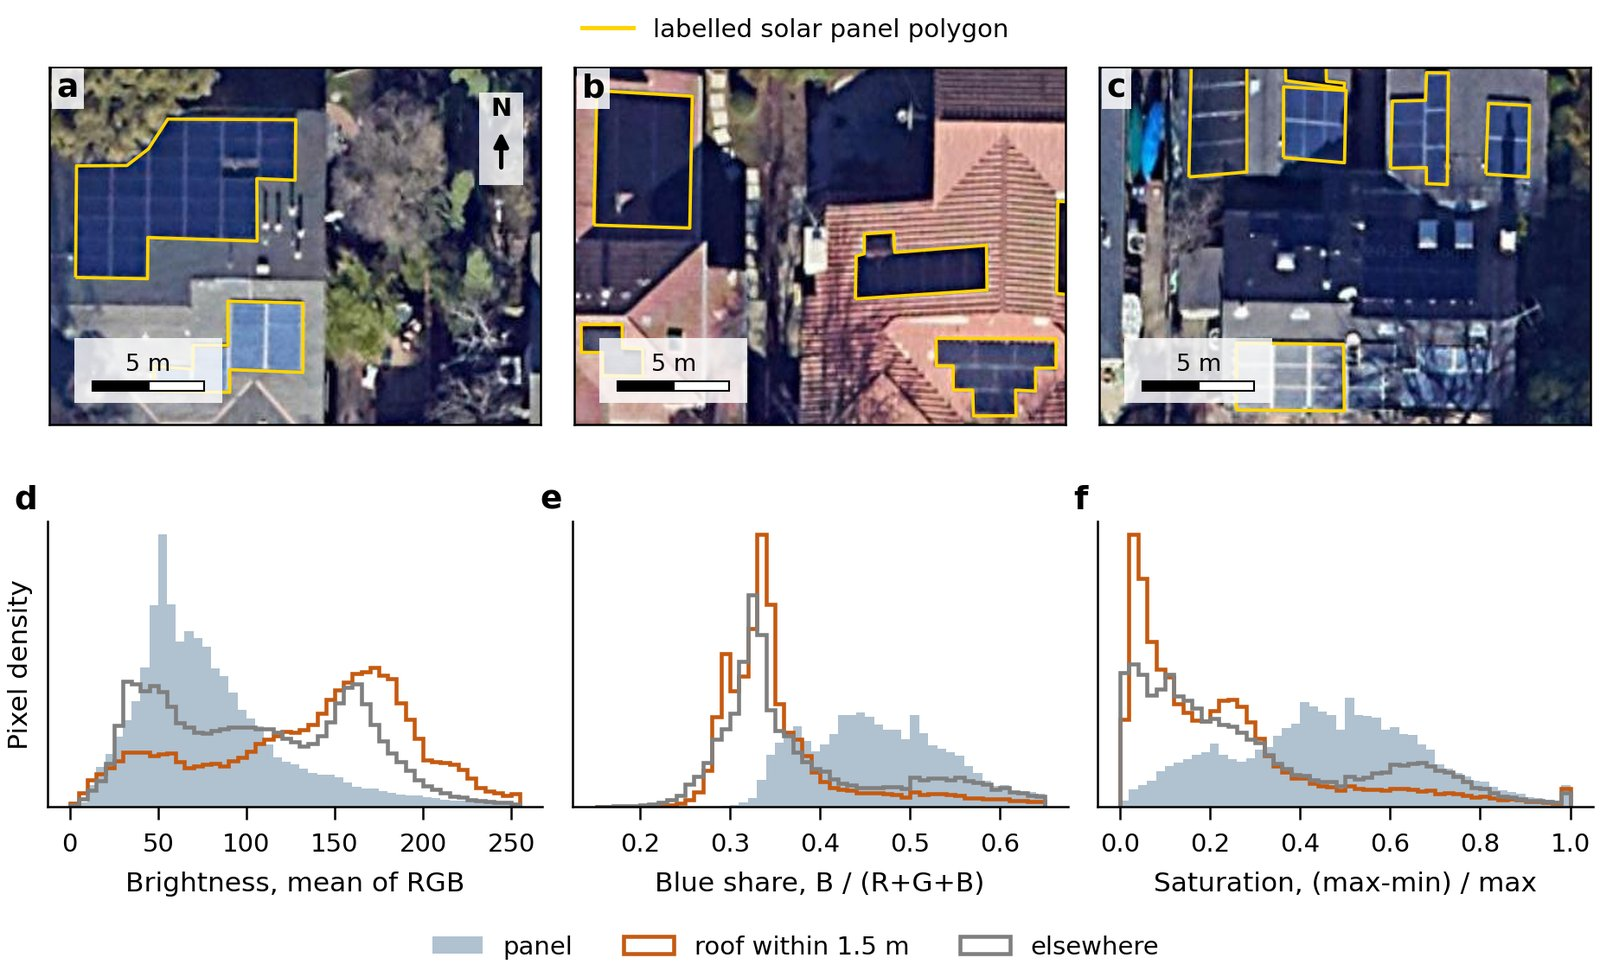

*what distinguishes solar panels in the Davis training image. a to c: three parts of the training scene with the labelled polygons, showing dark blue arrays with a visible module grid on grey and tiled roofs, a glinting light grey array at the bottom of c and an unlabelled dark roof plane in its centre. d to f: distributions of brightness, blue share and saturation for the 288 706 labelled panel pixels, for roof pixels between 0.3 and 1.5 m from an array and for all pixels more than 5 m from any array.*


We now convert the labelled image into image/label tiles for training.

A 512 × 512 tile is large enough to contain complete solar-panel objects while still being manageable on a Colab GPU. The stride controls how much neighbouring tiles overlap.

In [26]:
out_folder = "solar"                                 # 切片输出目录
tiles = geoai.export_geotiff_tiles(                  # 把一张大影像加矢量标注切成训练片
    in_raster=train_raster_path,                     # 输入影像
    out_folder=out_folder,                           # 输出：solar/images 与 solar/labels
    in_class_data=train_vector_path,                 # 矢量标注，会被栅格化成标签片，没有 class 字段时类别记为 1
    tile_size=512,                                   # 片大小 512 x 512 像素
    stride=256,                                      # 步长 256，相邻片重叠一半
    buffer_radius=0,                                 # 标注多边形不外扩
)                                                    # 结束

'class' not found in vector data. Using default class ID 1.


Generating tiles:   0%|          | 0/312 [00:00<?, ?it/s]

Generated: 1, With features: 0:   0%|          | 1/312 [00:00<00:09, 33.70it/s]

Generated: 2, With features: 0:   1%|          | 2/312 [00:00<00:08, 36.30it/s]

Generated: 3, With features: 0:   1%|          | 3/312 [00:00<00:08, 37.36it/s]

...

Generated: 309, With features: 134:  99%|█████████▉| 309/312 [00:09<00:00, 32.26it/s]

Generated: 310, With features: 135:  99%|█████████▉| 310/312 [00:09<00:00, 32.26it/s]

Generated: 311, With features: 136: 100%|█████████▉| 311/312 [00:09<00:00, 32.26it/s]

Generated: 312, With features: 137: 100%|██████████| 312/312 [00:09<00:00, 32.26it/s]

Generated: 312, With features: 137: 100%|██████████| 312/312 [00:09<00:00, 33.04it/s]

In [27]:
# （自加）切出来的训练片里光伏有多稀少：类别不平衡是后面很多现象的根源
fr = []                                              # 每片的光伏像元占比
for f in sorted(glob.glob(f"{out_folder}/labels/*.tif")):  # 逐片
    with rasterio.open(f) as s:                      # 打开标签片
        fr.append(float((s.read(1) > 0).mean()))     # 光伏像元占比
fr = np.array(fr)                                    # 转数组
tile_stats = dict(tiles=int(fr.size), with_panel=float(np.mean(fr > 0)), panel_px_share=float(fr.mean()), share_in_panel_tiles=float(fr[fr > 0].mean()))  # 汇总
json.dump(tile_stats, open(f"{OUT}/solar_tile_stats.json", "w"), indent=1)  # 写盘
print(tile_stats)                                    # 打印

{'tiles': 312, 'with_panel': 0.4391025641025641, 'panel_px_share': 0.01410832771888146, 'share_in_panel_tiles': 0.032129914221102306}


Train a U-Net segmentation model. As in Task 1, the model predicts a class for each pixel. Here the two classes are background and solar panel. This took me 3-5 minutes to train on the GPU. On the CPU it took over 30 minutes:

In [28]:
geoai.train_segmentation_model(                      # 训练光伏分割模型
    images_dir=f"{out_folder}/images",               # 影像片
    labels_dir=f"{out_folder}/labels",               # 标签片
    output_dir=f"{out_folder}/models",               # 模型输出目录
    architecture="unet",                             # U-Net 结构
    encoder_name="resnet34",                         # ResNet34 编码器
    encoder_weights="imagenet",                      # ImageNet 预训练权重
    num_channels=3,                                  # 航拍只有 RGB 三个通道
    num_classes=2,                                   # 背景与光伏板
    batch_size=8,                                    # 每批 8 片
    num_epochs=10,                                   # 10 轮
    learning_rate=1e-3,                              # 学习率 0.001
    val_split=0.2,                                   # 两成切片作验证
)                                                    # 训练结束

Evaluate the model:

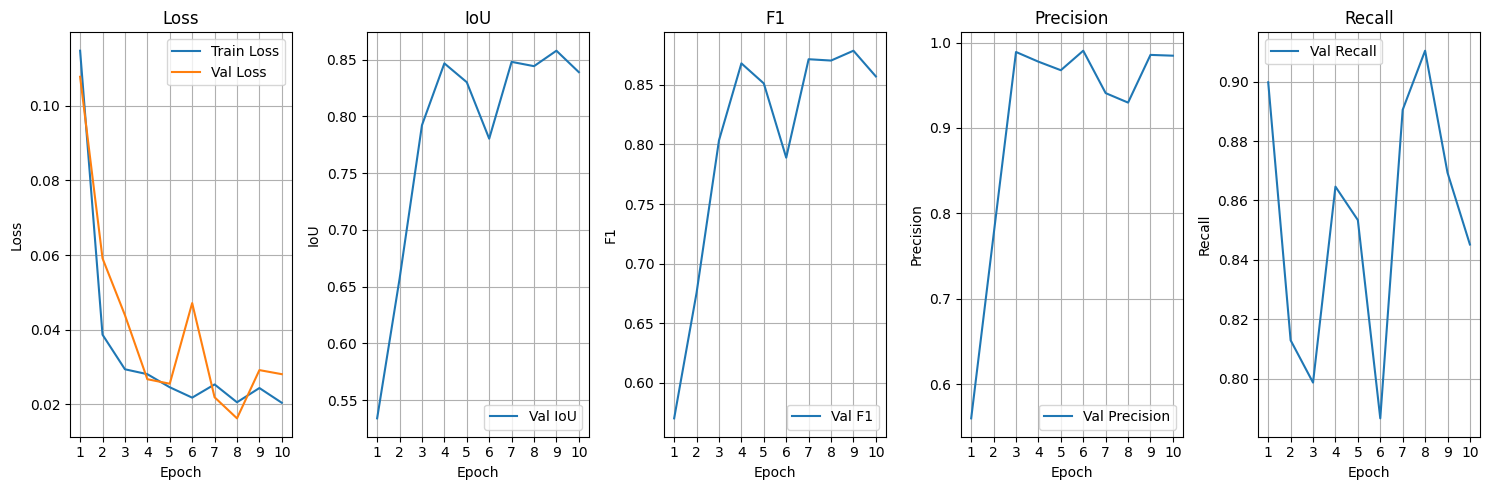

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.114796,0.107806,0.533908,0.570093,0.559786,0.899822
1,2,0.038634,0.059107,0.656798,0.675493,0.774776,0.812889
2,3,0.029357,0.043874,0.792293,0.803420,0.988880,0.798629
3,4,0.028045,0.026693,0.846816,0.868060,0.977541,0.864656
4,5,0.024531,0.025483,0.830194,0.851217,0.967539,0.853381
5,6,0.021753,0.047105,0.780431,0.788905,0.990382,0.786583
6,7,0.025292,0.021847,0.848140,0.871538,0.940721,0.890547
7,8,0.020507,0.016199,0.844347,0.870424,0.929609,0.910456
8,9,0.024328,0.029136,0.857966,0.878684,0.985478,0.869373
9,10,0.020369,0.028042,0.839056,0.857094,0.984556,0.845157


In [29]:
geoai.plot_performance_metrics(                      # 画光伏模型的训练与验证曲线
    history_path=f"{out_folder}/models/training_history.pth",  # 训练历史文件
    figsize=(15, 5),                                 # 画幅
    verbose=True,                                    # 打印最佳值与最终值
    save_path=f"{OUT}/geoai_solar_metrics.png",      # 自加：存一份 PNG
)                                                    # 结束

In [30]:
# （自加）存光伏模型的训练历史
hist_solar = save_history(f"{out_folder}/models/training_history.pth", "solar_history")  # 转 JSON
print({k: v[-1] for k, v in hist_solar.items() if isinstance(v, list) and v})  # 打印最后一轮

{'train_losses': 0.02036914612108376, 'val_losses': 0.028042284946423024, 'val_ious': 0.8390563602115101, 'val_f1s': 0.8570943990725314, 'val_precisions': 0.9845559542894555, 'val_recalls': 0.8451567078030058}


In [31]:
# （自加）Q7 用：geoai 报的验证 IoU 是背景与光伏两类平均、再按切片平均，没有光伏的切片几乎白送 1 分。
# 这里只看光伏这一类：在训练片和验证片上各自合并全部像元算召回，并数一数每块标注被找回了多少
from sklearn.model_selection import train_test_split  # 复现 geoai 的划分
imgs = sorted(glob.glob(f"{out_folder}/images/*.tif"))  # 影像片
labs = sorted(glob.glob(f"{out_folder}/labels/*.tif"))  # 标签片
tr_i, va_i, tr_l, va_l = train_test_split(imgs, labs, test_size=0.2, random_state=42)  # 与训练时相同的划分
net = smp.create_model("unet", encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=2)  # 同结构空模型
sd = torch.load(f"{out_folder}/models/best_model.pth", map_location="cpu")  # 最优权重
net.load_state_dict({k.replace("module.", "", 1): v for k, v in sd.items()})  # 去掉多卡前缀
net = net.cuda().eval()                              # 推理模式
q7 = {}                                              # 结果
with torch.no_grad():                                # 不算梯度
    for split, ii, ll in (("train", tr_i, tr_l), ("val", va_i, va_l)):  # 训练片与验证片分开算
        tp = fn = fp = 0                             # 像元计数
        parts = []                                   # 每块标注被找回的比例
        for fi, fl in zip(ii, ll):                   # 逐片
            with rasterio.open(fl) as s:             # 标签
                y = s.read(1) > 0                    # 光伏 = True
            with rasterio.open(fi) as s:             # 影像
                x = torch.from_numpy(s.read().astype(np.float32) / 255.0)[None].cuda()  # 除以 255 归一化
            pr = torch.softmax(net(x), 1)[0, 1].cpu().numpy() >= 0.5  # 默认判定
            tp += int((pr & y).sum()); fp += int((pr & ~y).sum()); fn += int((~pr & y).sum())  # 累计
            lab_y, n_y = ndimage.label(y)            # 片内每块标注
            parts += [float(pr[lab_y == k].mean()) for k in range(1, n_y + 1)]  # 每块被找回的比例
        parts = np.array(parts)                      # 转数组
        q7[split] = dict(tiles=len(ii), panel_recall=tp / max(1, tp + fn), panel_precision=tp / max(1, tp + fp), label_parts=int(parts.size), parts_mostly_found=int((parts >= 0.5).sum()), parts_missed=int((parts < 0.1).sum()))  # 汇总
json.dump(q7, open(f"{OUT}/solar_q7_recall.json", "w"), indent=1)  # 写盘
print(json.dumps(q7, indent=1))                      # 打印
del net                                              # 释放

{
 "train": {
  "tiles": 249,
  "panel_recall": 0.5655342021410967,
  "panel_precision": 0.950209370675265,
  "label_parts": 266,
  "parts_mostly_found": 126,
  "parts_missed": 115
 },
 "val": {
  "tiles": 63,
  "panel_recall": 0.4723498496016924,
  "panel_precision": 0.9310139424061354,
  "label_parts": 69,
  "parts_mostly_found": 22,
  "parts_missed": 41
 }
}


Q7: Examine the training and validation curves. Is there evidence that the model is still learning, or that it is beginning to overfit? What would you change about the training process if you wanted to improve the model further?

**答案 Q7**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

There is no evidence of overfitting, and the evidence that the model is still learning only appears when one looks past the curves. In Figure 4 training loss falls steeply to 0.028 by epoch 4 and then flattens near 0.02, while validation loss follows it to a minimum of 0.016 at epoch 8 and ends at 0.028, the level of epoch 4 and well inside the jitter of its spike to 0.047 at epoch 6. Validation IoU climbs from 0.53 to 0.85 within four epochs and then oscillates between 0.78 and 0.86, with the best checkpoint at epoch 9. No persistent gap opens between training and validation loss, which is the signature of overfitting.

The plateau in IoU is misleading. GeoAI averages the IoU of the panel and background classes and then averages over tiles, so the 35 of 63 validation tiles that contain no panel score almost 1. For the panel class alone the best model reaches an IoU of only 0.46 and a recall of 0.47 on the validation tiles, and a recall of just 0.57 on its own training tiles, where it essentially misses 115 of 266 labelled panel pieces, Figure 4d. A model that has not yet fitted its training data is underfitting: it has learned the typical blue array with a visible module grid but not the near black, glinting or shaded arrays seen in Figure 3.

To improve it I would train for longer, 30 to 50 epochs with early stopping on validation loss and a lower or decaying learning rate to calm the oscillation; replace plain cross entropy, which the 98.6 percent of background pixels dominate, with a Dice or focal loss or class weights so that a missed panel pixel costs more; add rotations at arbitrary angles and stronger brightness augmentation; label more varied arrays, including black modules and racked panels on flat roofs; and hold out a spatially separate block for validation, because the current validation tiles overlap training tiles by half.

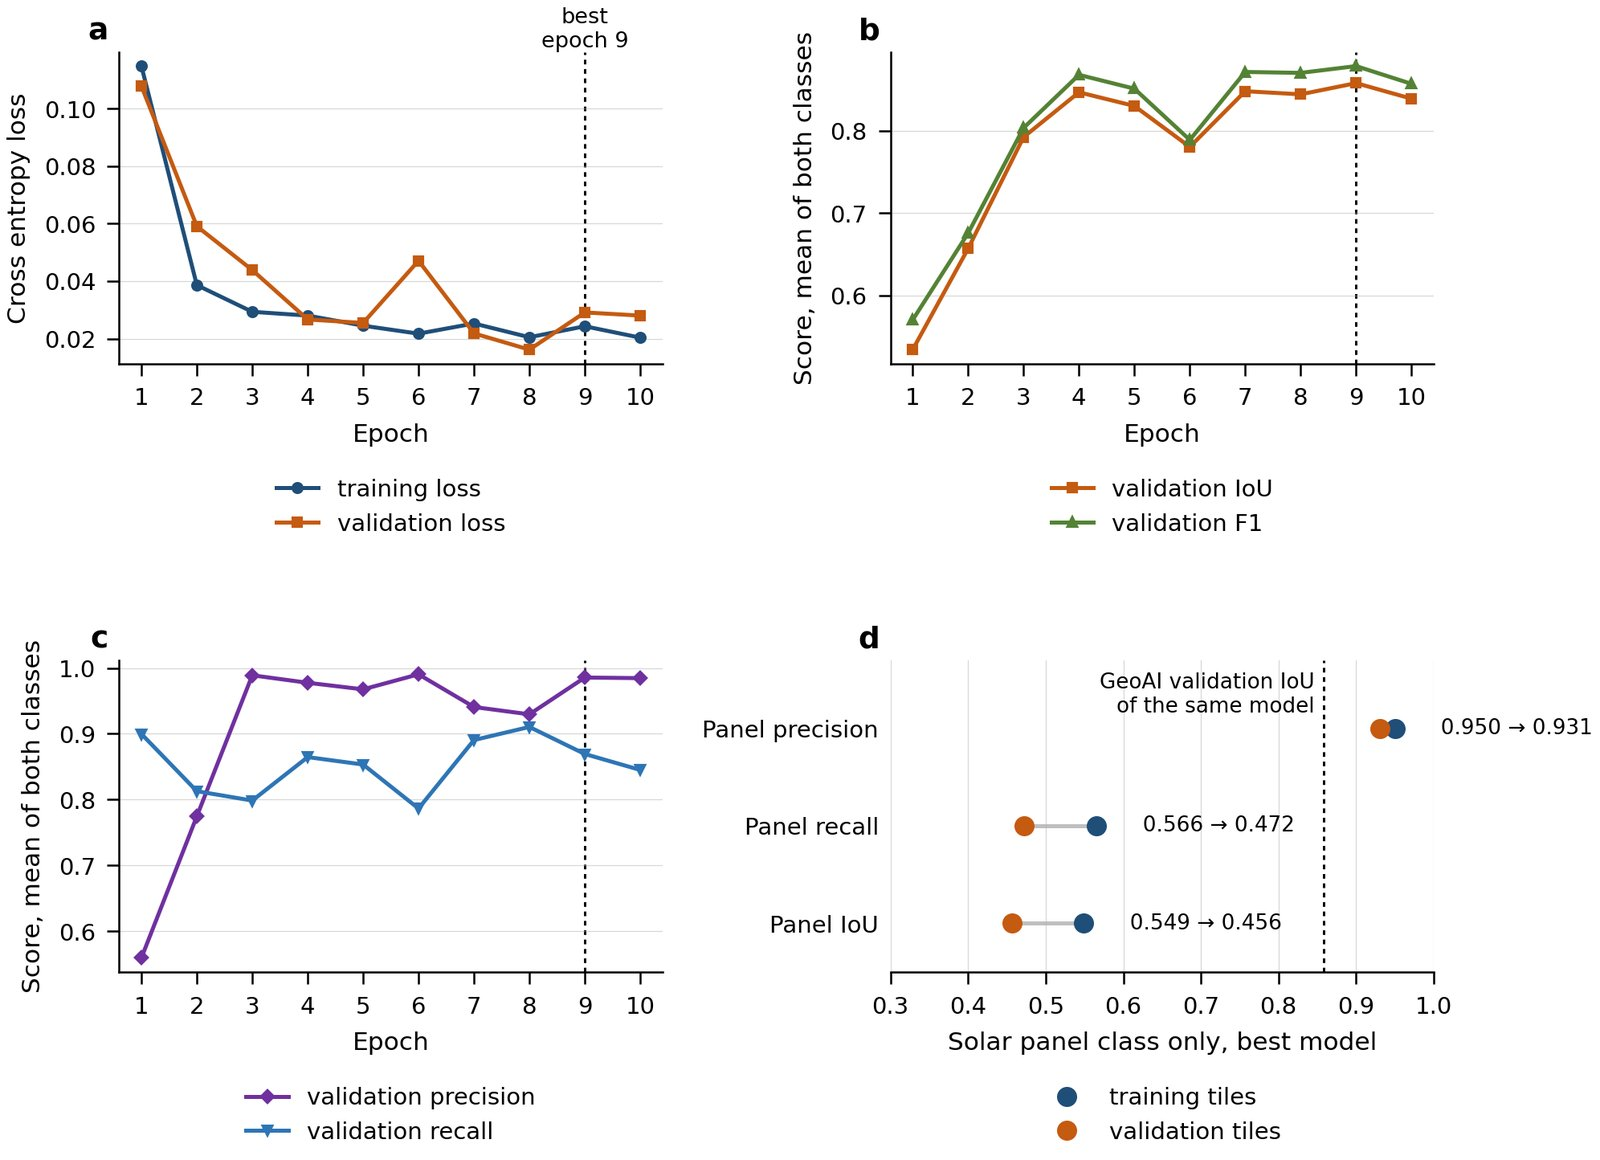

*training of the solar panel model, ten epochs. a to c: loss and the validation scores reported by GeoAI, averaged over the panel and background classes and over tiles; the dotted line marks epoch 9, saved as best_model. d: the same model scored on the panel class alone at a threshold of 0.5, pooled over all pixels of the 249 training tiles and the 63 validation tiles, against the IoU that GeoAI reports.*


Now apply the trained model to the unseen test image. In addition to the usual class mask, we will save the model's probability map. For a two-class problem, the second band contains the probability that each pixel belongs to the solar-panel class.

This is useful because the default mask hides how confident the model was. A pixel just above the classification boundary is different from a pixel for which the model is highly confident.

In [32]:
masks_path = "solar_panels_prediction.tif"           # 默认二值结果的输出路径
probability_path = "solar_panels_probability.tif"    # 概率图输出路径：两个波段，第 2 波段是光伏概率
model_path = f"{out_folder}/models/best_model.pth"   # 验证 IoU 最高那一轮的权重

geoai.semantic_segmentation(                         # 对没见过的测试影像推理
    input_path=test_raster_path,                     # 测试影像
    output_path=masks_path,                          # 输出二值掩膜，两类时取概率较大的一类
    model_path=model_path,                           # 模型权重
    architecture="unet",                             # 与训练一致
    encoder_name="resnet34",                         # 与训练一致
    num_channels=3,                                  # 与训练一致
    num_classes=2,                                   # 与训练一致
    window_size=512,                                 # 滑窗大小
    overlap=256,                                     # 滑窗重叠 256 像素
    batch_size=8,                                    # 每批 8 个窗口
    probability_path=probability_path,               # 同时保存概率图
)                                                    # 结束

  0%|          | 0/209 [00:00<?, ?it/s]

  4%|▍         | 8/209 [00:00<00:06, 28.83it/s]

  8%|▊         | 16/209 [00:00<00:06, 30.11it/s]

 11%|█▏        | 24/209 [00:00<00:06, 30.82it/s]

 15%|█▌        | 32/209 [00:01<00:05, 31.48it/s]

...

216it [00:06, 32.60it/s]                         

224it [00:06, 33.44it/s]

232it [00:07, 34.14it/s]

240it [00:07, 34.69it/s]

240it [00:07, 32.96it/s]

Let's look at both the predicted mask.


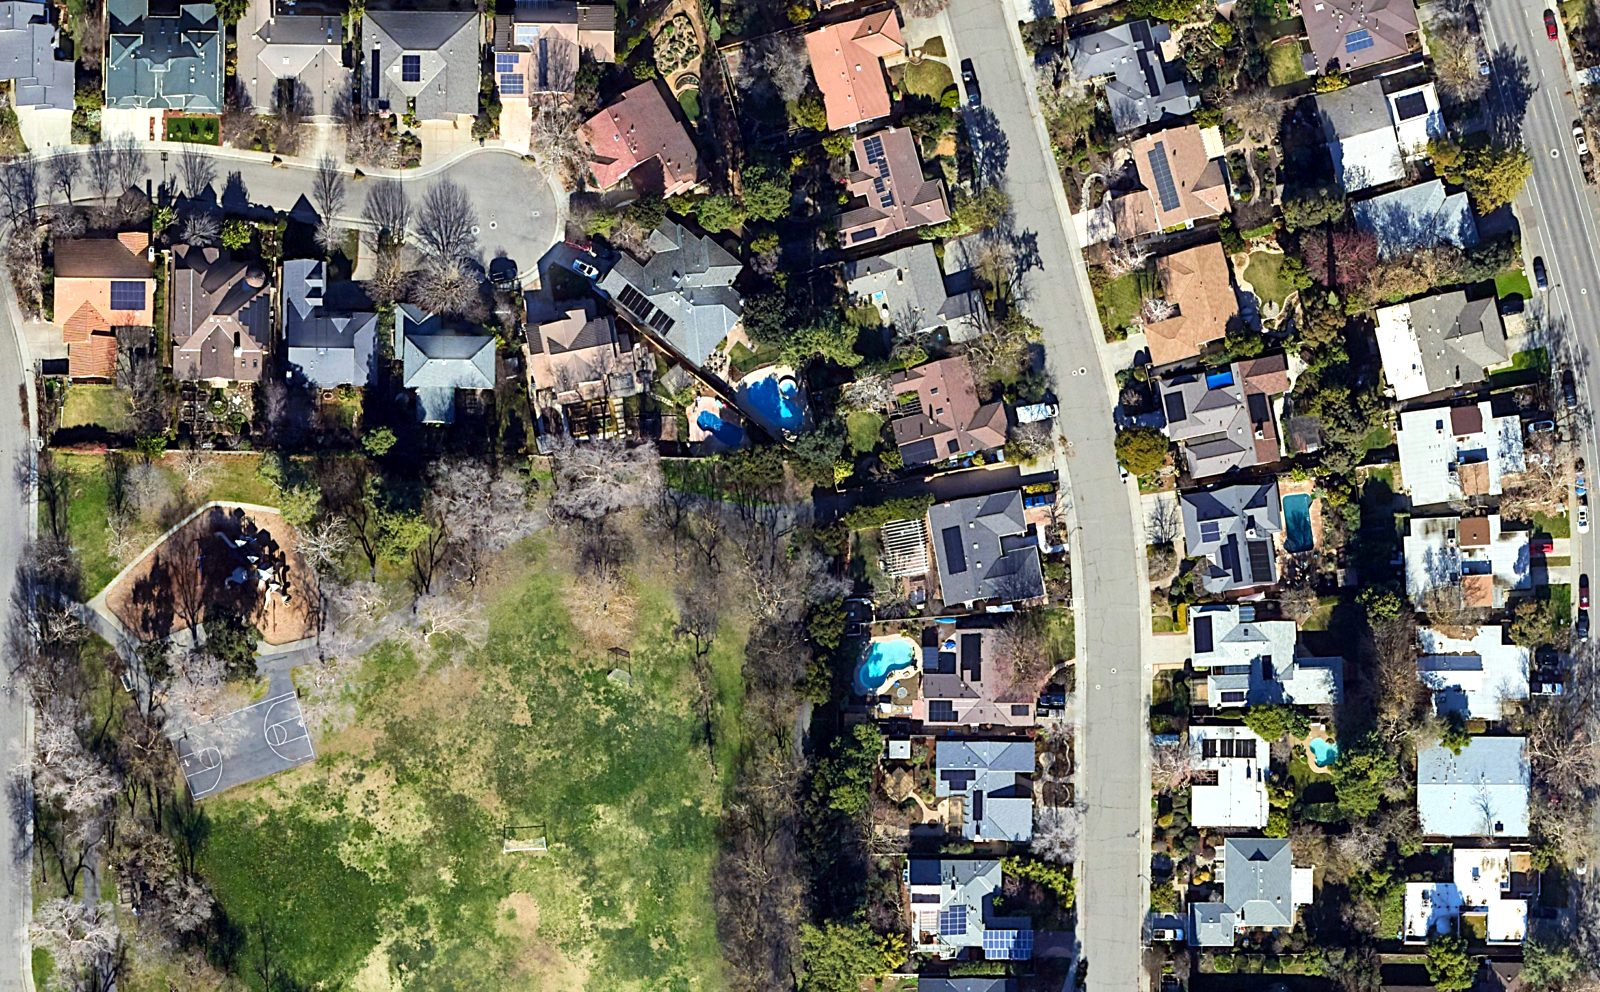
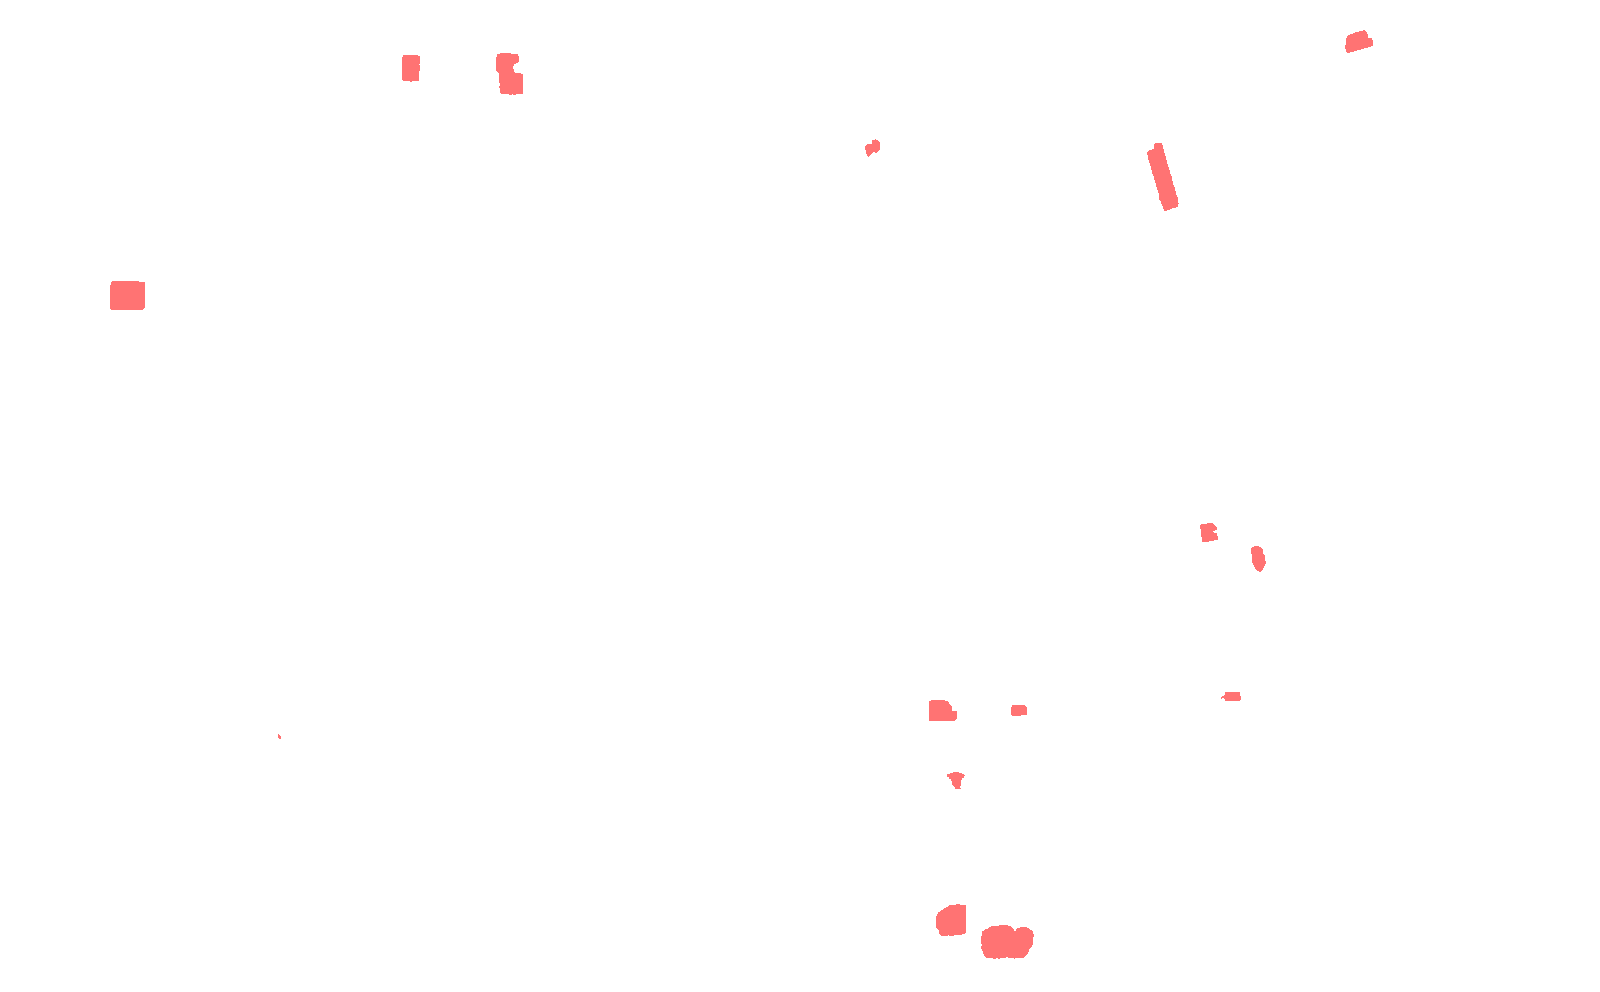
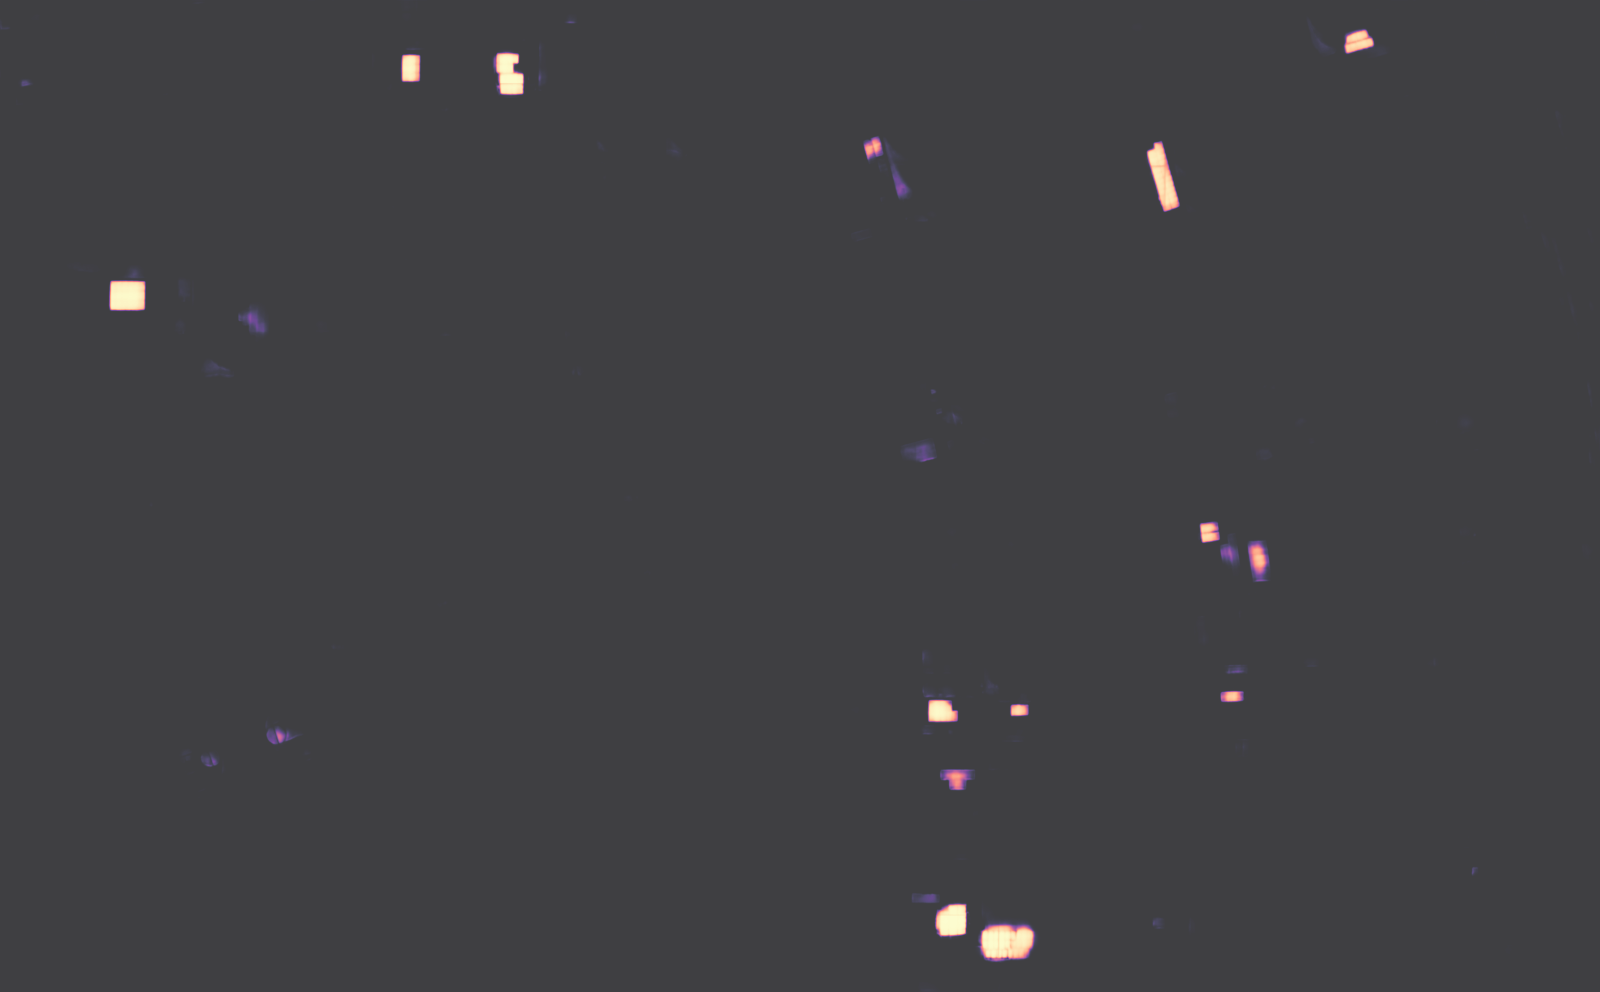

In [33]:
show_interactive(raster=test_raster_path, mask=masks_path, probability=probability_path, title="Predictions")  # 交互查看：影像、默认掩膜、概率图三个图层

In [34]:
# （自加）Q8 用：概率图里确定与不确定的像元各有多少、分布在哪里
with rasterio.open(probability_path) as s:           # 概率图：第 1 波段背景概率，第 2 波段光伏概率
    p1 = s.read(2)                                   # 光伏概率
with rasterio.open(masks_path) as s:                 # 默认二值结果
    m0 = s.read(1) > 0                               # 光伏 = True
print("default mask equals p >= 0.5 on", f"{np.mean(m0 == (p1 >= 0.5)):.4%}", "of pixels")  # 两类取最大类本质上就是 0.5 阈值
bins = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0001]          # 概率分档
share = np.histogram(p1, bins=bins)[0] / p1.size     # 各档占全图的比例
q8 = {"bins": {f"{a}-{b:.1f}": float(v) for a, b, v in zip(bins[:-1], bins[1:], share)}}  # 记下
edge = m0 ^ ndimage.binary_erosion(m0)               # 默认结果中目标的边界像元
d_edge = ndimage.distance_transform_edt(~edge) * gsd_te  # 每个像元到最近目标边界的地面距离，米
unc = (p1 >= 0.3) & (p1 < 0.7)                       # 不确定带
q8["uncertain_px"] = int(unc.sum())                  # 不确定像元数
q8["uncertain_within_0.5m_of_boundary"] = float(np.mean(d_edge[unc] <= 0.5))  # 其中贴着目标边界的比例
lab_o, n_o = ndimage.label(m0)                       # 默认结果的连通目标
idx = np.arange(1, n_o + 1)                          # 目标编号
area_o = np.bincount(lab_o.ravel())[1:] * gsd_te ** 2  # 每个目标的地面面积，m2
meanp_o = ndimage.mean(p1, lab_o, idx)               # 每个目标的平均概率
q8["objects"] = []                                   # 按面积分档统计平均概率
for lo, hi in [(0, 0.5), (0.5, 2), (2, 10), (10, 1e9)]:  # 面积档，m2
    sel = (area_o >= lo) & (area_o < hi)             # 这一档
    q8["objects"].append(dict(lo=lo, hi=hi, n=int(sel.sum()), mean_prob=float(meanp_o[sel].mean()) if sel.any() else None))  # 个数与平均概率
json.dump(q8, open(f"{OUT}/solar_q8_stats.json", "w"), indent=1)  # 写盘
print(json.dumps(q8, indent=1))                      # 打印

default mask equals p >= 0.5 on 100.0000% of pixels


{
 "bins": {
  "0-0.1": 0.9926036223195049,
  "0.1-0.3": 0.001794528576084235,
  "0.3-0.5": 0.0005877192649432985,
  "0.5-0.7": 0.0006549233377365655,
  "0.7-0.9": 0.0016083020274915943,
  "0.9-1.0": 0.0027509044742393602
 },
 "uncertain_px": 18657,
 "uncertain_within_0.5m_of_boundary": 0.9644101409658573,
 "objects": [
  {
   "lo": 0,
   "hi": 0.5,
   "n": 3,
   "mean_prob": 0.5304033268809787
  },
  {
   "lo": 0.5,
   "hi": 2,
   "n": 0,
   "mean_prob": null
  },
  {
   "lo": 2,
   "hi": 10,
   "n": 6,
   "mean_prob": 0.7219243720078454
  },
  {
   "lo": 10,
   "hi": 1000000000.0,
   "n": 8,
   "mean_prob": 0.8912989391778217
  }
 ]
}


Q8: Compare the binary mask with the probability map. Where does the model appear confident? Where does it appear uncertain? Why might a probability map be more useful than a binary mask when deciding how to improve a detection workflow?

**答案 Q8**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

The probability map shows a model that is almost always sure of itself. Across the test image 99.26 percent of pixels have a panel probability below 0.1 and 0.28 percent exceed 0.9, while only 0.12 percent, about 64 square metres, fall between 0.3 and 0.7. The model is confident inside blue arrays with a visible module grid, such as the two row array in Figure 5a to c, where probabilities reach about 0.9 and the edges are sharp. It is uncertain in two kinds of place. The first is the rim of every array: 96 percent of the uncertain pixels lie within 0.5 m of a predicted boundary, where pixels mix panel and roof and where overlapping inference windows are averaged. The second is whole objects that resemble the training panels only in part: the large dark array on the right of Figure 5c peaks at 0.87 but has a median of 0.31, so the binary mask shows a rounded blob over about a third of it, the L shaped dark arrays beside it never exceed 0.41 and vanish from the mask, and the basketball court in Figure 5f, blue grey asphalt crossed by white lines, peaks at 0.57.

The binary mask hides all of this, because for two classes GeoAI's default class decision is the same as a threshold of 0.5: here the default mask equals probability at least 0.5 at every pixel. A probability map is more useful for improving a workflow because it shows how far each detection lies from the decision boundary. It reveals arrays that the mask misses but a small threshold change would recover, it separates confident detections from borderline ones so that only the borderline cases need checking or relabelling, and it points to the systematic weakness, dark arrays without a visible grid, that new training data should target. A binary mask can only report right or wrong after the fact.

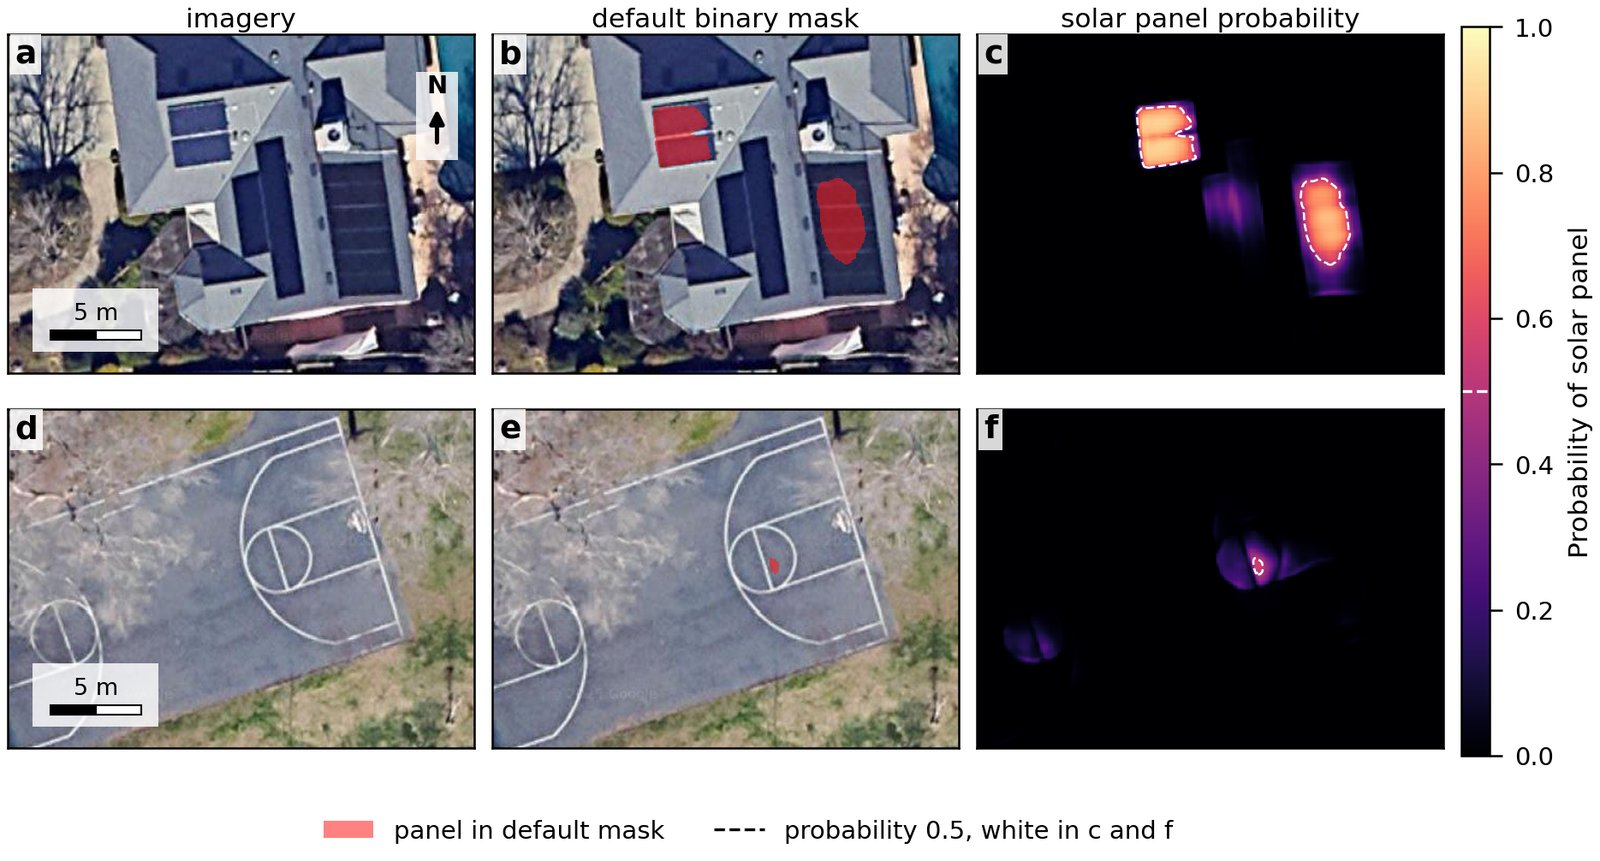

*default binary mask against probability map on the unseen test image. a to c: a house with a confidently detected blue two row array, a large dark array detected only near its centre and L shaped dark arrays that stay below 0.5. d to f: a basketball court that produces a weak false detection. The dashed white line in c and f is the 0.5 contour that defines the default mask.*


Improving the segmentation with a probability threshold:

The default binary result uses the model's class decision. We can instead specify a probability threshold for the solar-panel class. A lower threshold will normally retain more candidate pixels, while a higher threshold will normally produce fewer, more conservative detections.

Run the model again using a threshold of 0.7. Then compare this result with the original prediction.

  0%|          | 0/209 [00:00<?, ?it/s]

  4%|▍         | 8/209 [00:00<00:08, 24.89it/s]

  8%|▊         | 16/209 [00:00<00:06, 28.82it/s]

 11%|█▏        | 24/209 [00:00<00:06, 30.75it/s]

 15%|█▌        | 32/209 [00:01<00:05, 31.57it/s]

...

216it [00:06, 34.05it/s]                         

224it [00:06, 34.75it/s]

232it [00:06, 35.42it/s]

240it [00:07, 35.77it/s]

240it [00:07, 33.54it/s]


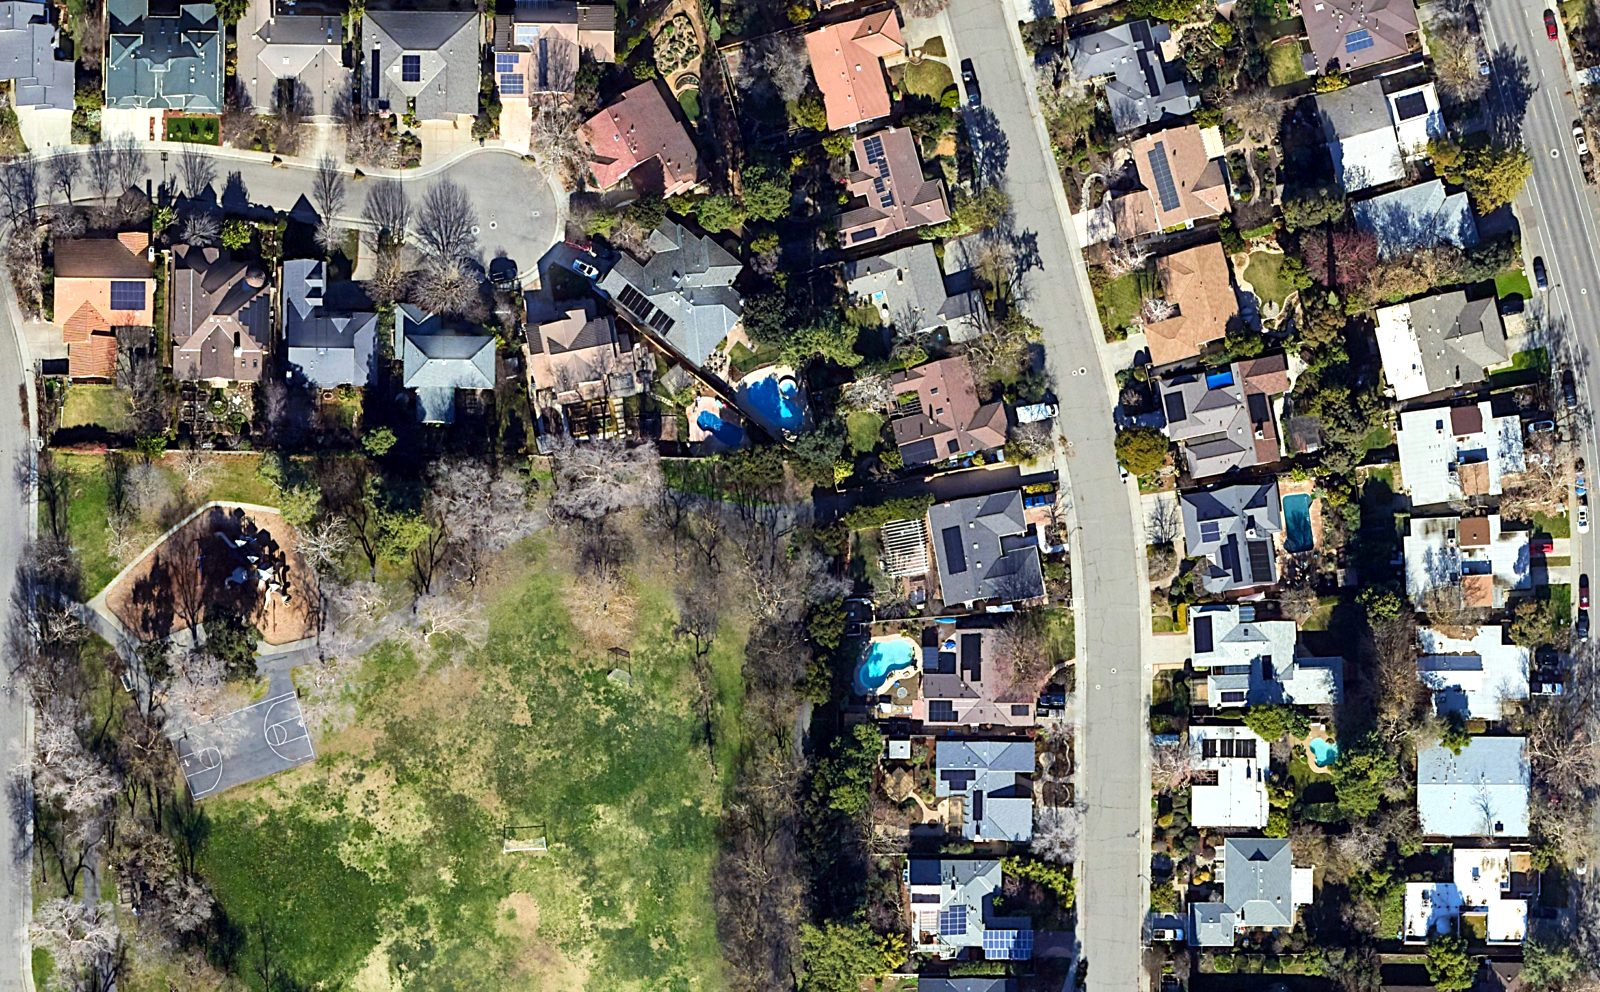
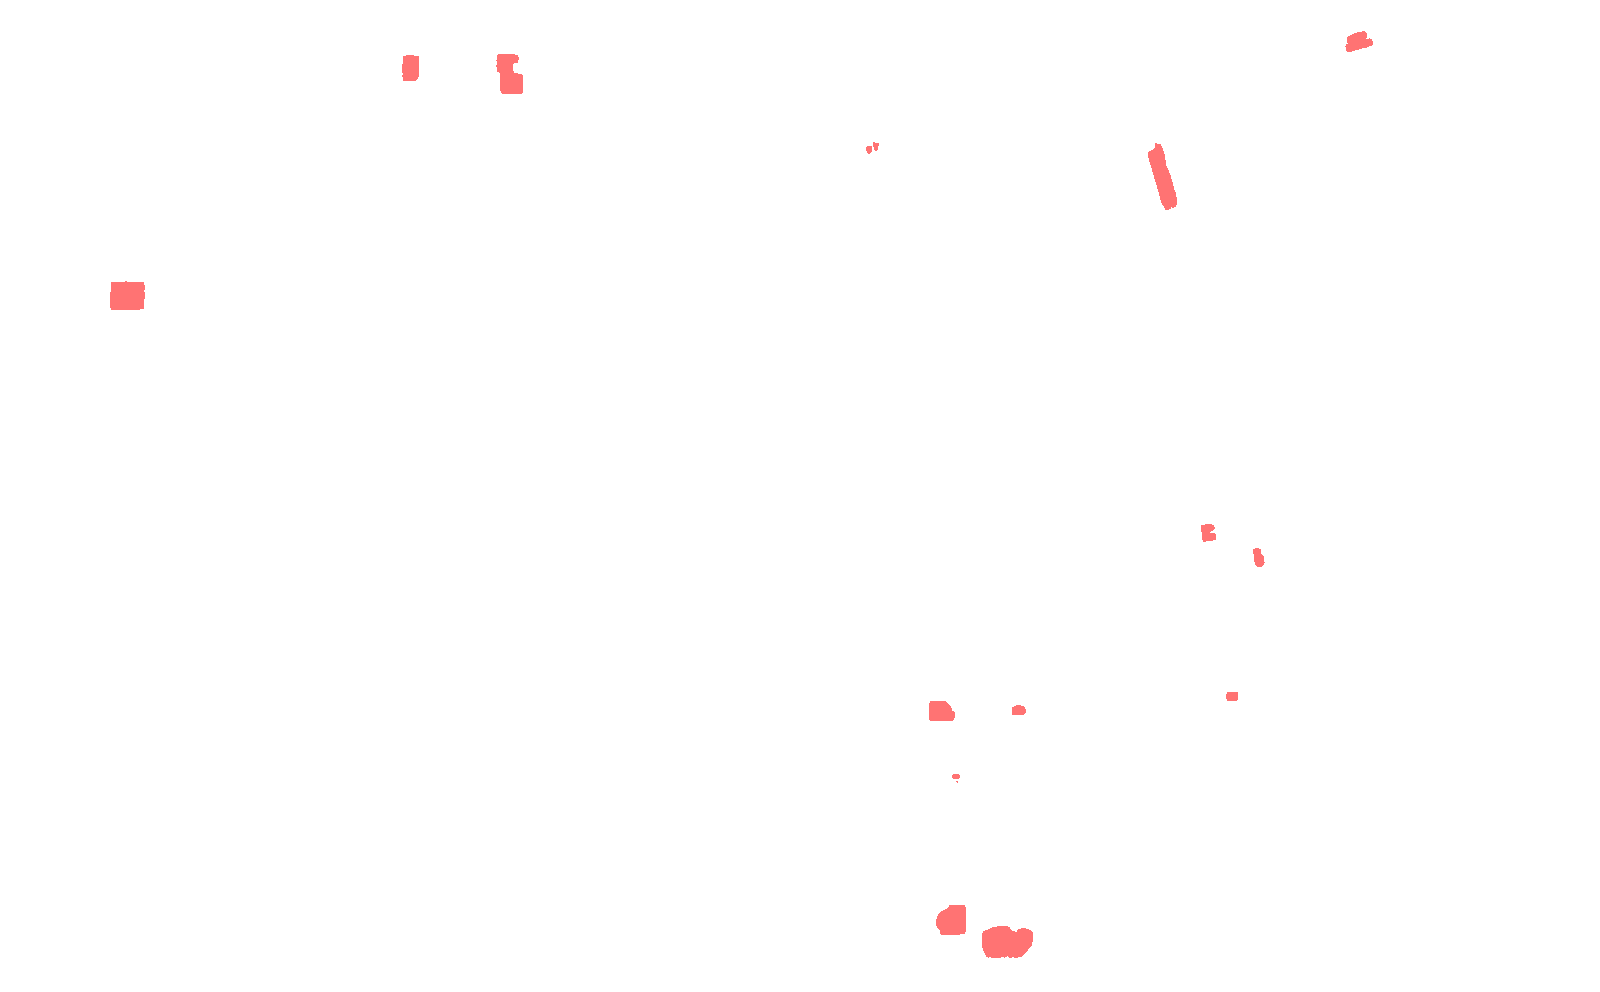
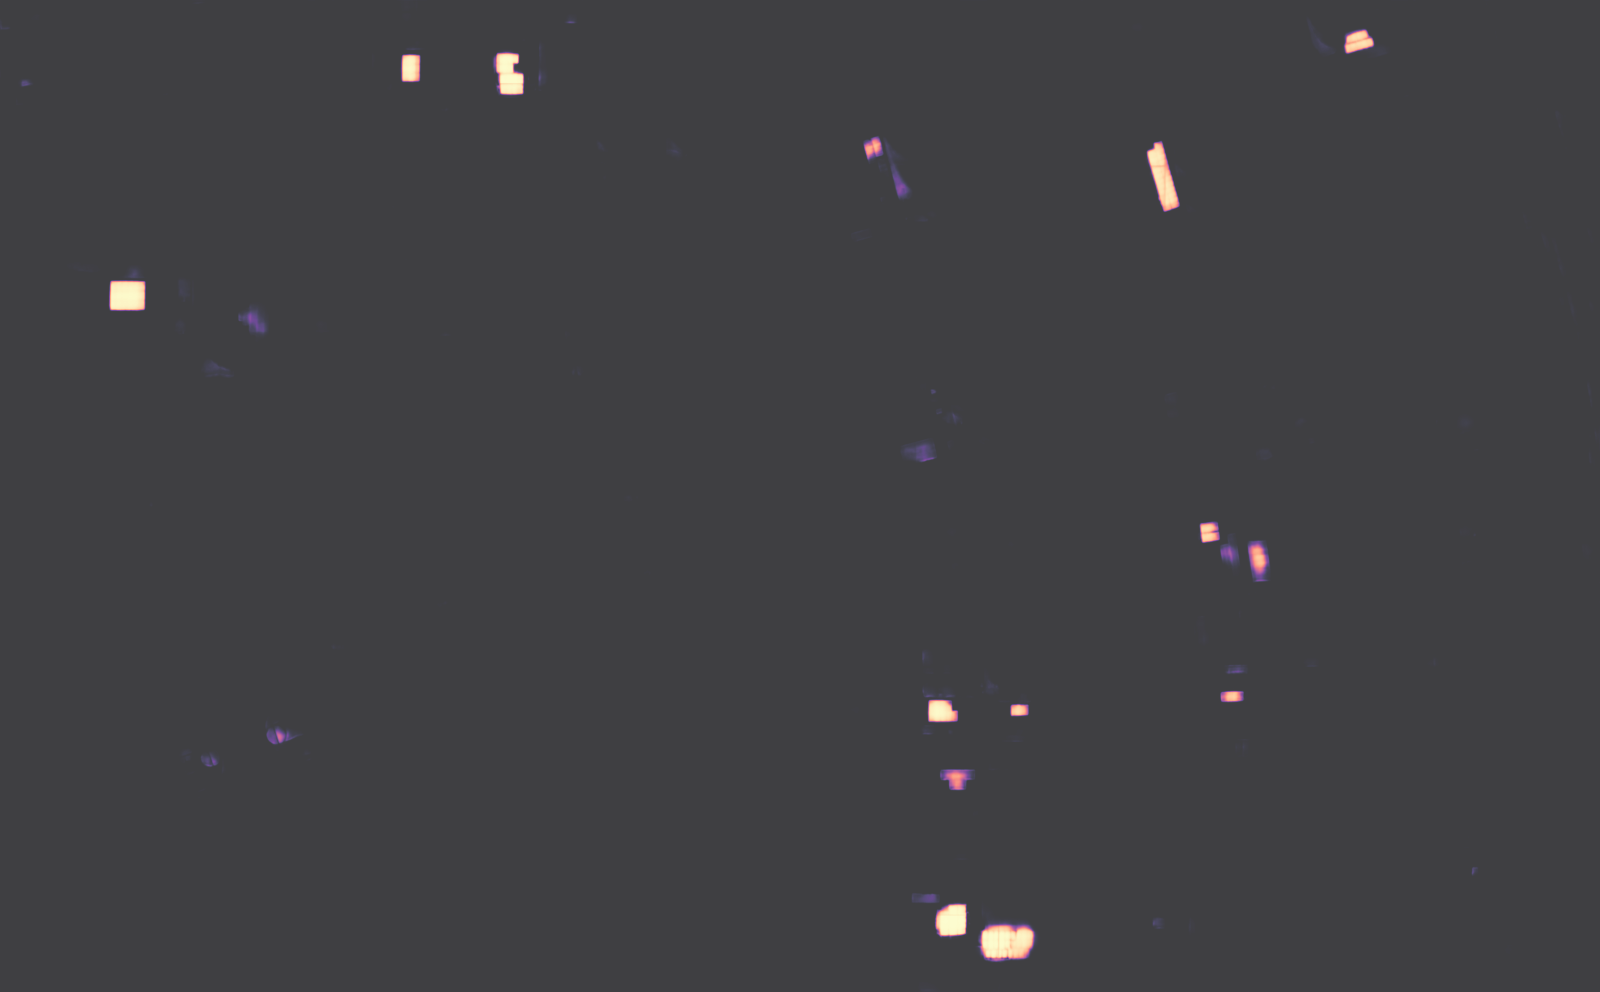

In [35]:
threshold = 0.7                                      # 光伏概率阈值：概率不低于 0.7 才判为光伏
threshold_mask_path = f"solar_panels_prediction_{threshold:.1f}.tif"  # 这个阈值的输出路径

geoai.semantic_segmentation(                         # 同一个模型再推理一遍，只是换成阈值判定
    input_path=test_raster_path,                     # 测试影像
    output_path=threshold_mask_path,                 # 输出
    model_path=model_path,                           # 同一套权重
    architecture="unet",                             # 一致
    encoder_name="resnet34",                         # 一致
    num_channels=3,                                  # 一致
    num_classes=2,                                   # 一致
    window_size=512,                                 # 一致
    overlap=256,                                     # 一致
    batch_size=8,                                    # 一致
    probability_threshold=threshold,                 # 唯一区别：用阈值代替取最大类
)                                                    # 结束

show_interactive(raster=test_raster_path, mask=threshold_mask_path, probability=probability_path, title=f"Threshold {threshold}")  # 原模板这里传的是 masks_path，看到的仍是默认结果，改成阈值结果才能对比

Q9: Experiment with at least two different probability thresholds between 0.3 and 0.9. Compare the resulting masks visually. Which threshold gives you the most useful balance between retaining solar-panel pixels and rejecting false positives? Explain your choice using evidence from the imagery.

In [36]:
# （自加）Q9：0.3 到 0.9 每隔 0.1 都跑一遍，0.7 上面已经跑过；统计每个阈值的总面积和目标数
thr_paths = {0.7: threshold_mask_path}               # 已有 0.7
for t in (0.3, 0.4, 0.5, 0.6, 0.8, 0.9):             # 其余阈值
    pth = f"solar_panels_prediction_{t:.1f}.tif"     # 输出名
    geoai.semantic_segmentation(input_path=test_raster_path, output_path=pth, model_path=model_path, architecture="unet", encoder_name="resnet34", num_channels=3, num_classes=2, window_size=512, overlap=256, batch_size=8, probability_threshold=t, quiet=True)  # 同样的推理，只换阈值
    thr_paths[t] = pth                               # 记下路径
thr_stats = {}                                       # 每个阈值一行
for t in sorted(thr_paths):                          # 从低到高
    with rasterio.open(thr_paths[t]) as s:           # 打开
        mk = s.read(1) > 0                           # 二值
    lab_t, n_t = ndimage.label(mk)                   # 连通目标
    sz = np.bincount(lab_t.ravel())[1:] * gsd_te ** 2  # 每个目标的地面面积
    thr_stats[t] = dict(area_m2=float(mk.sum() * gsd_te ** 2), objects=int(n_t), objects_ge_1m2=int((sz >= 1).sum()))  # 总面积、目标数、不小于 1 m2 的目标数
    print(t, thr_stats[t])                           # 打印
json.dump({str(k): v for k, v in thr_stats.items()}, open(f"{OUT}/solar_threshold_stats.json", "w"), indent=1)  # 写盘

0.3 {'area_m2': 286.6530002708498, 'objects': 24, 'objects_ge_1m2': 15}
0.4 {'area_m2': 271.1727975834054, 'objects': 19, 'objects_ge_1m2': 14}


0.5 {'area_m2': 256.57873595688915, 'objects': 17, 'objects_ge_1m2': 14}
0.6 {'area_m2': 241.9062849288292, 'objects': 17, 'objects_ge_1m2': 14}


0.7 {'area_m2': 223.06556267955736, 'objects': 18, 'objects_ge_1m2': 15}
0.8 {'area_m2': 195.56792391198766, 'objects': 14, 'objects_ge_1m2': 13}


0.9 {'area_m2': 140.76691576328253, 'objects': 17, 'objects_ge_1m2': 11}


In [37]:
# （自加）Q9 的补充证据：在训练时留出的验证片上扫阈值，算光伏这一类的精度、召回、F1、IoU。
# 用与 geoai 内部相同的 train_test_split 与随机种子 42 复现验证集；验证片与训练片有一半重叠，绝对值偏乐观，看的是随阈值的走向。
from sklearn.model_selection import train_test_split  # geoai 内部用的同一个划分函数
imgs = sorted(glob.glob(f"{out_folder}/images/*.tif"))  # 影像片，与 geoai 一样按文件名排序
labs = sorted(glob.glob(f"{out_folder}/labels/*.tif"))  # 标签片
_, v_imgs, _, v_labs = train_test_split(imgs, labs, test_size=0.2, random_state=42)  # 复现验证集
net = smp.create_model("unet", encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=2)  # 同结构的空模型
sd = torch.load(model_path, map_location="cpu")      # 读训练好的权重
net.load_state_dict({k.replace("module.", "", 1): v for k, v in sd.items()})  # 去掉多卡训练留下的 module. 前缀
net = net.cuda().eval()                              # 上 GPU，推理模式
P, Y = [], []                                        # 收集概率与标签
with torch.no_grad():                                # 推理不需要梯度
    for fi, fl in zip(v_imgs, v_labs):               # 逐片
        with rasterio.open(fi) as s:                 # 影像片
            x = torch.from_numpy(s.read().astype(np.float32) / 255.0)[None].cuda()  # 与训练相同的除以 255 归一化
        with rasterio.open(fl) as s:                 # 标签片
            Y.append(s.read(1) > 0)                  # 光伏 = True
        P.append(torch.softmax(net(x), 1)[0, 1].cpu().numpy())  # 光伏概率
P, Y = np.stack(P), np.stack(Y)                      # 堆成数组
sweep = []                                           # 每个阈值一行
for t in np.round(np.arange(0.1, 0.96, 0.05), 2):    # 0.10 到 0.95
    pr = P >= t                                      # 二值化
    tp, fp, fn = int((pr & Y).sum()), int((pr & ~Y).sum()), int((~pr & Y).sum())  # 三格
    sweep.append(dict(t=float(t), precision=tp / max(1, tp + fp), recall=tp / max(1, tp + fn), f1=2 * tp / max(1, 2 * tp + fp + fn), iou=tp / max(1, tp + fp + fn)))  # 指标
    print({k: round(v, 4) for k, v in sweep[-1].items()})  # 打印
json.dump(dict(n_val_tiles=len(v_imgs), panel_px=int(Y.sum()), tiles_with_panel=int(Y.reshape(len(Y), -1).any(1).sum()), sweep=sweep), open(f"{OUT}/solar_val_threshold_sweep.json", "w"), indent=1)  # 写盘
del net, P, Y                                        # 释放

{'t': 0.1, 'precision': 0.7921, 'recall': 0.6132, 'f1': 0.6913, 'iou': 0.5282}
{'t': 0.15, 'precision': 0.827, 'recall': 0.5841, 'f1': 0.6847, 'iou': 0.5205}
{'t': 0.2, 'precision': 0.8514, 'recall': 0.5628, 'f1': 0.6777, 'iou': 0.5125}
{'t': 0.25, 'precision': 0.8698, 'recall': 0.5455, 'f1': 0.6705, 'iou': 0.5043}


{'t': 0.3, 'precision': 0.8868, 'recall': 0.529, 'f1': 0.6627, 'iou': 0.4956}
{'t': 0.35, 'precision': 0.9005, 'recall': 0.5135, 'f1': 0.6541, 'iou': 0.4859}
{'t': 0.4, 'precision': 0.9123, 'recall': 0.4995, 'f1': 0.6456, 'iou': 0.4766}
{'t': 0.45, 'precision': 0.9224, 'recall': 0.486, 'f1': 0.6366, 'iou': 0.4669}


{'t': 0.5, 'precision': 0.931, 'recall': 0.4723, 'f1': 0.6267, 'iou': 0.4564}
{'t': 0.55, 'precision': 0.9384, 'recall': 0.4571, 'f1': 0.6147, 'iou': 0.4437}
{'t': 0.6, 'precision': 0.946, 'recall': 0.4397, 'f1': 0.6003, 'iou': 0.4289}
{'t': 0.65, 'precision': 0.9535, 'recall': 0.4194, 'f1': 0.5826, 'iou': 0.411}


{'t': 0.7, 'precision': 0.9621, 'recall': 0.3989, 'f1': 0.5639, 'iou': 0.3927}
{'t': 0.75, 'precision': 0.9709, 'recall': 0.3733, 'f1': 0.5393, 'iou': 0.3692}
{'t': 0.8, 'precision': 0.9803, 'recall': 0.3367, 'f1': 0.5013, 'iou': 0.3345}
{'t': 0.85, 'precision': 0.9888, 'recall': 0.2846, 'f1': 0.4419, 'iou': 0.2836}


{'t': 0.9, 'precision': 0.9982, 'recall': 0.2122, 'f1': 0.35, 'iou': 0.2121}
{'t': 0.95, 'precision': 1.0, 'recall': 0.1097, 'f1': 0.1977, 'iou': 0.1097}


In [38]:
# （自加）Q9 的选择：看完各阈值的掩膜和验证片扫描后定下的阈值，后面的矢量化都用它
chosen_threshold = 0.3                  # 选定的阈值，理由见 Q9
threshold_mask_path = thr_paths[chosen_threshold]    # 后续矢量化用这个阈值的掩膜
print("vectorising", threshold_mask_path)            # 打印

vectorising solar_panels_prediction_0.3.tif


**答案 Q9**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

I compared thresholds of 0.3, 0.5, 0.7 and 0.9, and 0.3 gives the most useful balance for this model because its errors are overwhelmingly omissions rather than false alarms. In the imagery, Figure 6, raising the threshold shrinks every outline towards its most confident core: at 0.9 the well detected arrays in b break apart along their module rows and the partly detected dark array in a vanishes, and the total panel area in the test image falls from 287 square metres at 0.3 to 257 at 0.5, 223 at 0.7 and 141 at 0.9. Lowering the threshold to 0.3 recovers the full width of partly detected dark arrays, while the only new false positive of any size, the spot on the basketball court in c, grows from 0.4 to 1.6 square metres, small enough for the area filter in Q10 to remove; the other new objects are specks below 0.1 square metres and a fragment of a real array. The held out tiles confirm the trade: going from 0.5 to 0.3, precision falls only from 0.93 to 0.89 while recall rises from 0.47 to 0.53, and F1 is highest at the lowest permitted threshold.

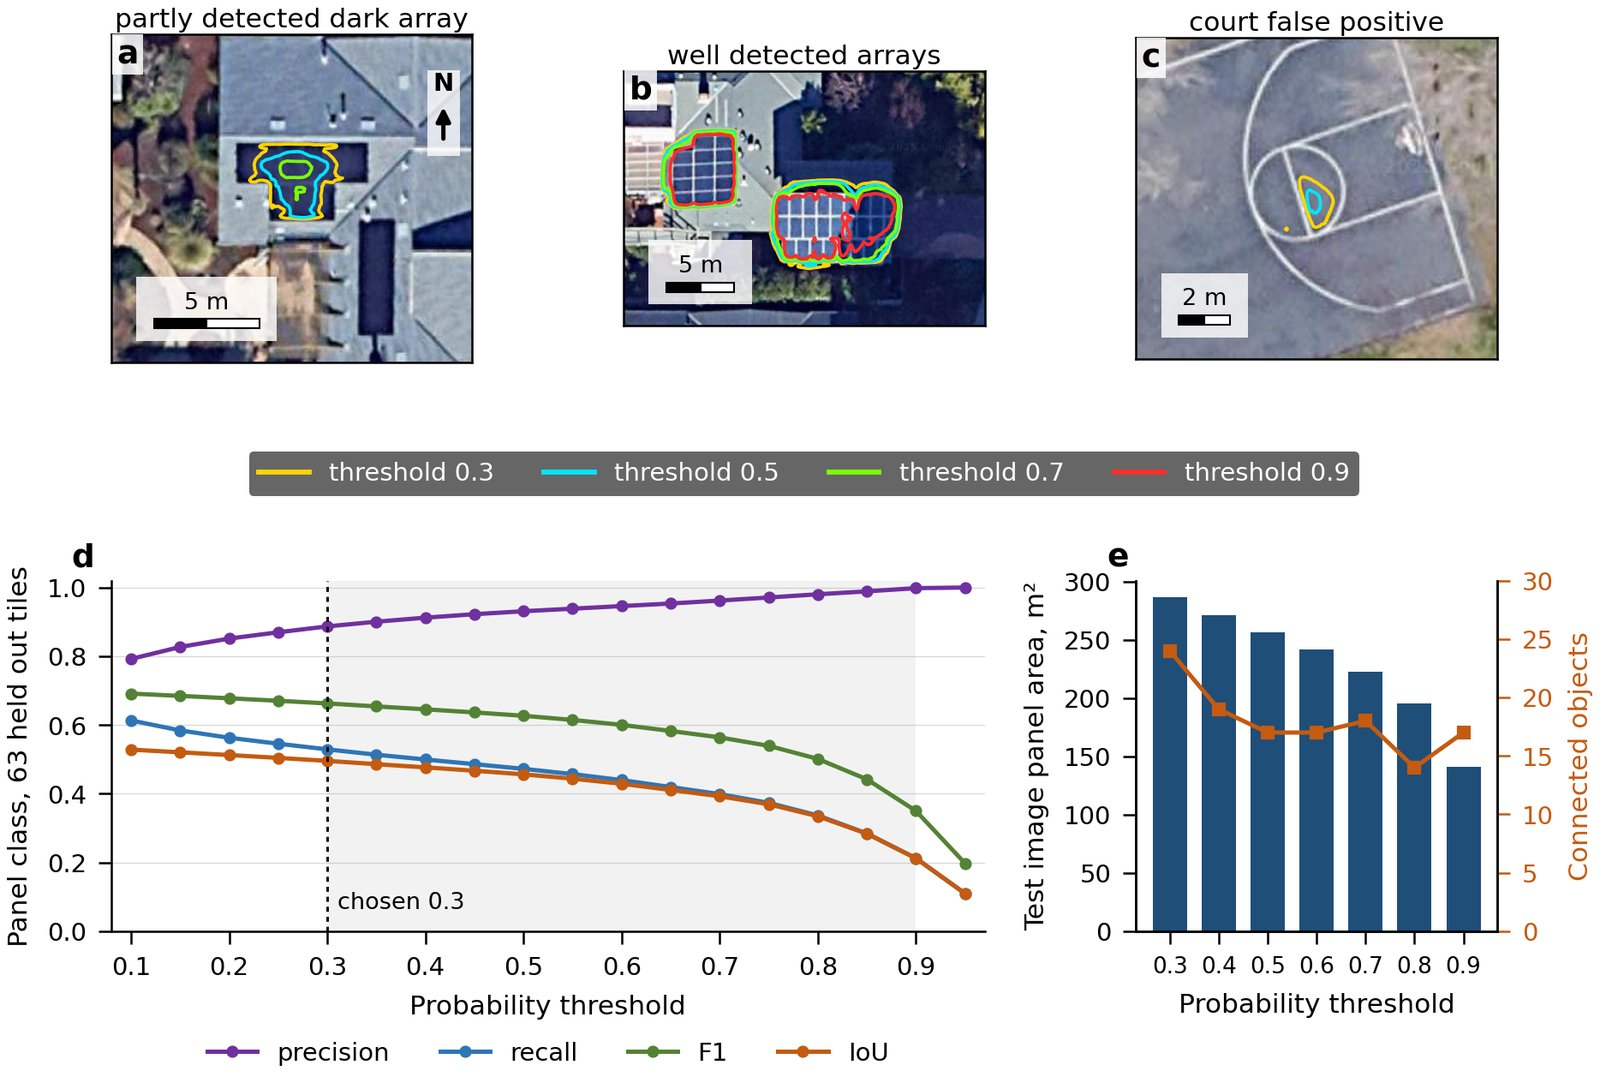

*effect of the probability threshold. a to c: contours at 0.3, 0.5, 0.7 and 0.9 over a partly detected dark array, two well detected arrays and the basketball court false positive. d: precision, recall, F1 and IoU of the panel class on the 63 held out validation tiles as the threshold changes, with the permitted range of 0.3 to 0.9 shaded. e: total panel area and number of connected objects in the test image.*


From pixels to objects:

The segmentation is still a raster. For many mapping applications we want individual features that can be counted, measured and filtered. We therefore convert the selected mask to polygons and regularise the polygon shapes.

In [39]:
output_path = "solar_panels_prediction.geojson"      # 矢量结果输出路径
gdf = geoai.orthogonalize(threshold_mask_path, output_path, epsilon=2)  # 栅格掩膜转多边形，再按 Douglas-Peucker 容差 2 简化并把边拉成直角

print(f"Number of polygons before filtering: {len(gdf)}")  # 过滤前的多边形数量

Converting features:   0%|          | 0/27 [00:00<?, ?shape/s]

Converting features:  15%|█▍        | 4/27 [00:00<00:00, 38.25shape/s]

Converting features:  96%|█████████▋| 26/27 [00:00<00:00, 130.60shape/s]

Converting features: 100%|██████████| 27/27 [00:00<00:00, 121.42shape/s]

Number of polygons before filtering: 24


We can now calculate geometric properties for every predicted object. This gives us information such as area, perimeter and shape characteristics that were not available in the raster mask.

In [40]:
gdf_props = geoai.add_geometric_properties(          # 给每个多边形算几何属性
    gdf,                                             # 上一步的多边形
    area_unit="m2",                                  # 面积单位
    length_unit="m",                                 # 长度单位
)                                                    # 结束

print(gdf_props[["area_m2", "length_m", "elongation", "solidity"]].describe())  # 面积、周长、伸长度、实心度的统计

         area_m2   length_m  elongation   solidity
count  24.000000  24.000000   24.000000  24.000000
mean   19.530349  16.690264    1.953145   0.922379
std    23.855709  14.693315    1.202391   0.088543
min     0.005572   0.298596    1.000036   0.677966
25%     0.052938   1.269023    1.159631   0.885457
50%    11.465359  17.915778    1.510136   0.951693
75%    26.205937  24.372952    2.195347   0.982175
max    86.612914  46.729952    5.096955   1.000000


In [41]:
# （自加）面积口径修正：影像是 Web Mercator，geoai 只在地理坐标系时才转 UTM，
# 所以上面的 area_m2 其实是墨卡托平方米，在北纬 38.5 度被放大约 1.6 倍。转到 UTM 10N 重算真实面积。
gdf_utm = gdf.to_crs(gdf.estimate_utm_crs())         # 转 UTM，单位是真实米
gdf_props_merc = gdf_props                           # 留着墨卡托口径作对照
gdf_props = geoai.add_geometric_properties(gdf_utm, area_unit="m2", length_unit="m")  # 重算几何属性
print("Mercator / true area, median:", round(float((gdf_props_merc["area_m2"] / gdf_props["area_m2"]).median()), 3))  # 验证放大倍数
print(gdf_props[["area_m2", "length_m", "elongation", "solidity"]].describe())  # 真实口径的统计

Mercator / true area, median: 1.638
         area_m2   length_m  elongation   solidity
count  24.000000  24.000000   24.000000  24.000000
mean   11.920520  13.038980    1.933524   0.922379
std    14.560602  11.477936    1.160261   0.088543
min     0.003401   0.233278    1.000833   0.677966
25%     0.032311   0.990587    1.162263   0.885457
50%     6.997955  13.998704    1.515768   0.951693
75%    15.994844  19.046632    2.198828   0.982175
max    52.866013  36.480230    5.117433   1.000000


Inspect the distribution of object sizes and shapes, then apply a simple geometric filter. Solar panels are relatively compact, regular objects, whereas tiny isolated detections are often artefacts of the segmentation.

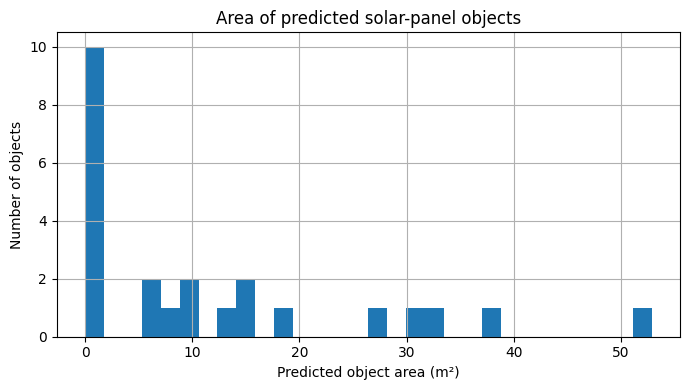

In [42]:
import matplotlib.pyplot as plt                      # 画图

fig, ax = plt.subplots(figsize=(7, 4))               # 新建图
gdf_props["area_m2"].hist(bins=30, ax=ax)            # 面积直方图，30 个等宽箱
ax.set_xlabel("Predicted object area (m²)")          # 横轴：预测目标面积
ax.set_ylabel("Number of objects")                   # 纵轴：目标个数
ax.set_title("Area of predicted solar-panel objects")  # 标题
plt.tight_layout()                                   # 收紧边距
plt.savefig(f"{OUT}/geoai_area_hist.png", dpi=150)   # 自加：存盘
plt.show()                                           # 显示

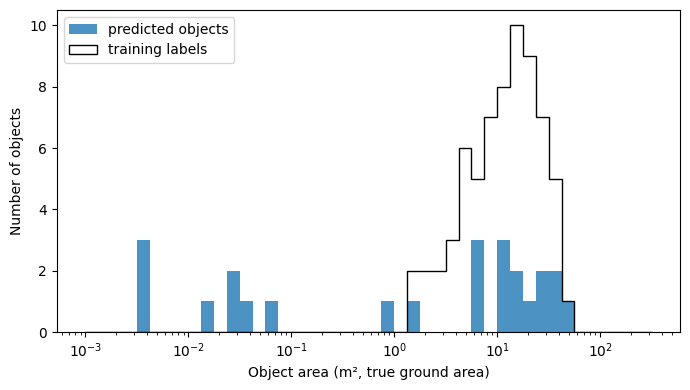

min_area  0.1 m2 keeps  16 of 24 objects
min_area  0.5 m2 keeps  16 of 24 objects
min_area  1.0 m2 keeps  15 of 24 objects
min_area  1.5 m2 keeps  15 of 24 objects
min_area  2.0 m2 keeps  14 of 24 objects
min_area  3.0 m2 keeps  14 of 24 objects


In [43]:
# （自加）对数横轴才看得清：碎斑和真光伏板的面积相差两三个数量级；黑线是训练标注的面积分布作参照
lab_area = gpd.read_file(train_vector_path).to_crs(gdf_props.crs).area  # 训练标注的真实面积
fig, ax = plt.subplots(figsize=(7, 4))               # 新图
edges = np.logspace(-3, 2.5, 45)                     # 0.001 到约 300 m2 的对数分箱
ax.hist(gdf_props["area_m2"].clip(1e-3), bins=edges, color="tab:blue", alpha=0.8, label="predicted objects")  # 预测目标
ax.hist(lab_area, bins=edges, histtype="step", color="k", lw=1.2, label="training labels")  # 训练标注
ax.set_xscale("log")                                 # 对数横轴
ax.set_xlabel("Object area (m², true ground area)")  # 横轴
ax.set_ylabel("Number of objects")                   # 纵轴
ax.legend()                                          # 图例
plt.tight_layout()                                   # 收紧
plt.show()                                           # 显示
for a in (0.1, 0.5, 1.0, 1.5, 2.0, 3.0):             # 几个候选阈值
    print(f"min_area {a:>4} m2 keeps {int((gdf_props['area_m2'] >= a).sum()):3d} of {len(gdf_props)} objects")  # 各自保留多少

Q10: Based on the area distribution and the map, choose a minimum object area that removes obvious small artefacts without removing genuine solar panels. State the threshold you chose and explain the trade-off.

**答案 Q10**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

I chose a minimum area of 2 square metres. GeoAI measured areas in Web Mercator units, which overstate true ground area 1.64 times at this latitude, so I first reprojected the polygons to UTM zone 10N. In true area the 24 objects at threshold 0.3 split into two groups with a clear gap between them, Figure 7: ten fragments of at most 1.6 square metres, eight of them specks under 0.1, and fourteen objects from 6.0 to 52.9 square metres that all coincide with real arrays. Two square metres sits just above the largest artefact, the 1.6 square metre spot on the basketball court, and above the size of a single module of about 1.7 square metres, so nothing smaller than one module survives. The filter removes 10 of the 24 objects but only 0.9 percent of the panel area. The trade off is that a higher cutoff would start deleting genuine installations: the smallest of the 67 training labels is 1.5 square metres and three are under 2, so in another scene a one module system could be lost, and here the filter already deletes a 0.8 square metre fragment of a real dark array that the model barely detected. Area filtering removes noise but cannot recover what the model missed.

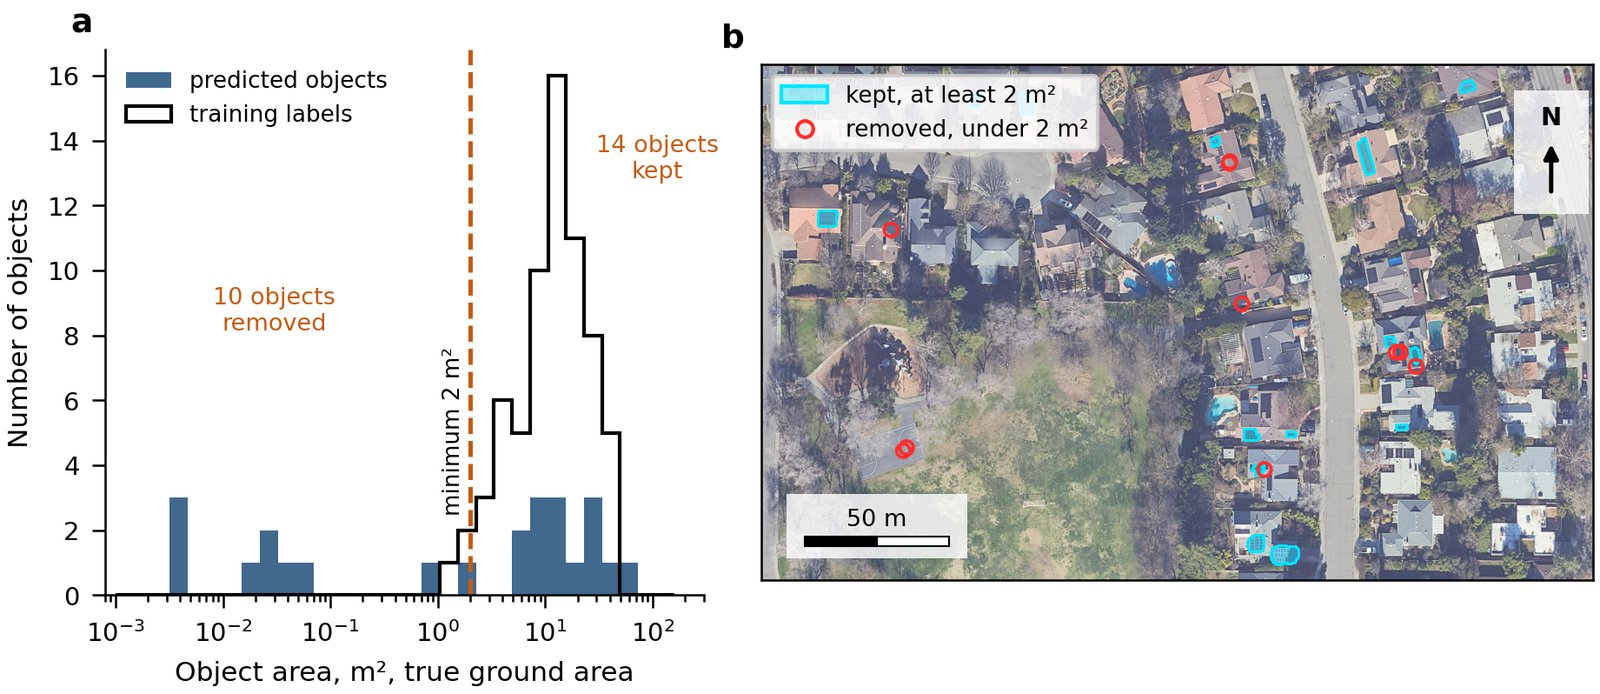

*choosing the minimum object area. a: true ground areas of the 24 objects vectorised at threshold 0.3, on a logarithmic axis, with the areas of the 67 training labels for reference and the 2 square metre cutoff dashed. b: objects kept and removed by the filter over the test image.*


Note: I have left the vector display as the default settings and they are a little hard to see... you may want to go and expand the code cell at the top of the lab that does the 'show_interactive' and see if you can make it better...

In [44]:
# Change this value after inspecting the area distribution and map. ｜ 看完面积分布和地图后再定这个值
min_area = 2.0                           # 最小目标面积，单位是真实地面平方米，理由见 Q10
gdf_filtered = gdf_props[gdf_props["area_m2"] >= min_area].copy()  # 只保留不小于阈值的目标

print(f"Objects before filtering: {len(gdf_props)}")  # 过滤前个数
print(f"Objects after filtering:  {len(gdf_filtered)}")  # 过滤后个数
print(f"Objects removed:          {len(gdf_props) - len(gdf_filtered)}")  # 删掉的个数

Objects before filtering: 24
Objects after filtering:  14
Objects removed:          10



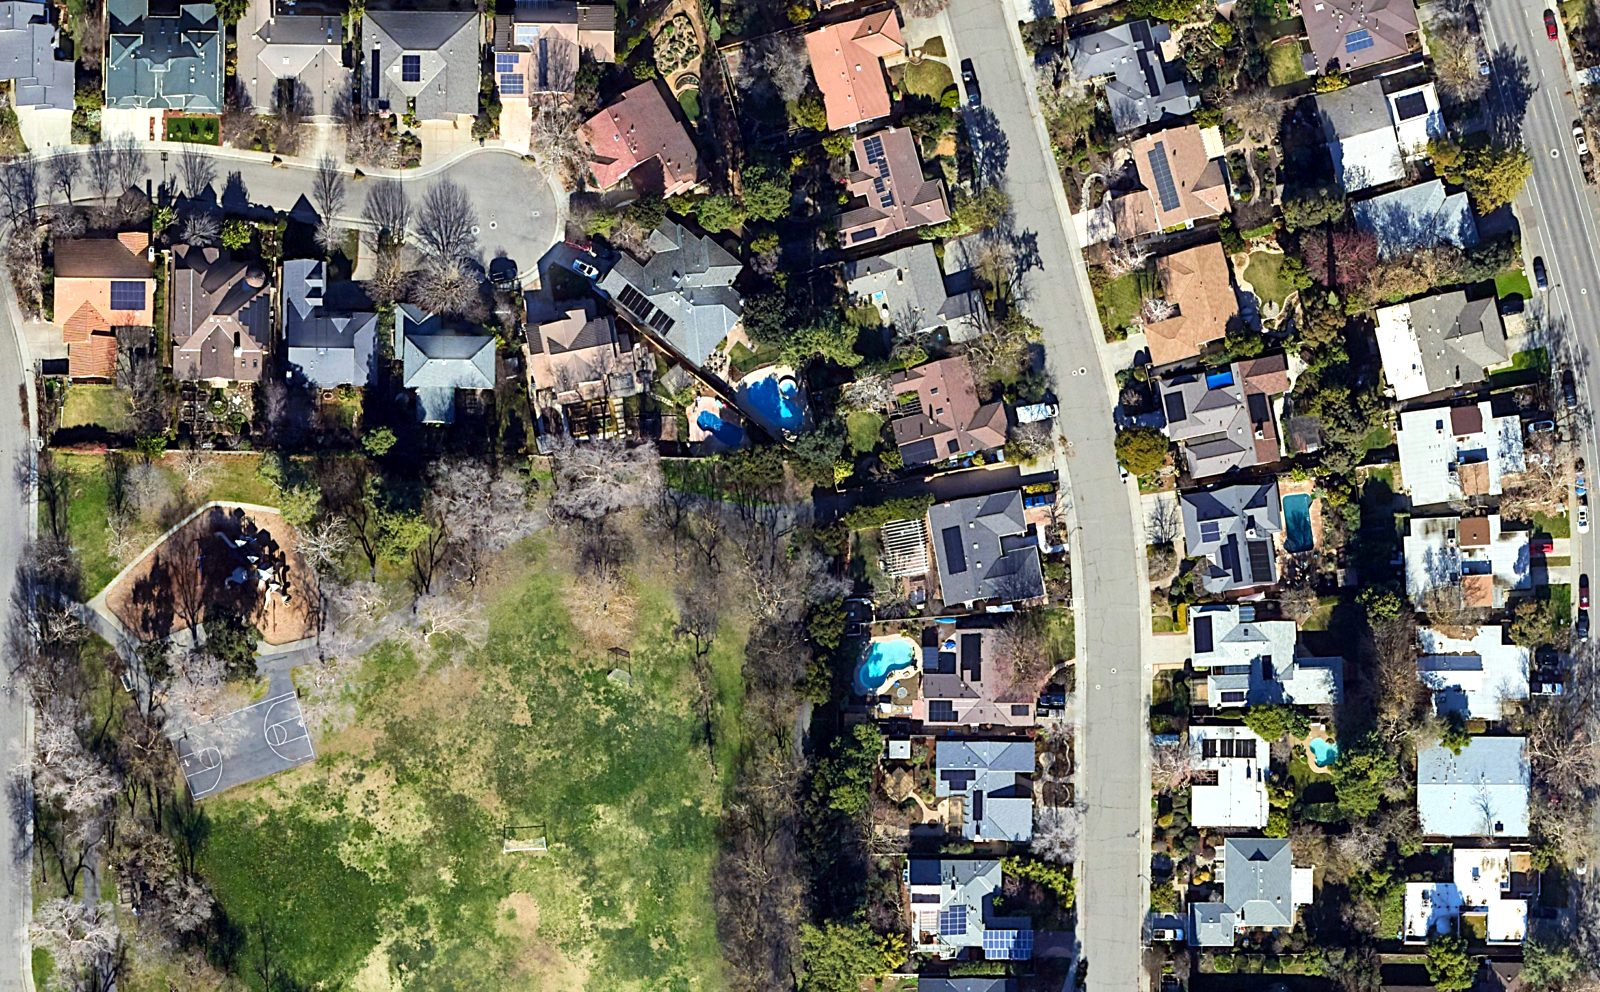

In [45]:
show_interactive(raster=test_raster_path, vector=gdf_filtered, vector_column="area_m2", title="Filtered detections")  # 交互查看过滤后的目标，按面积着色

In [46]:
# （自加）把最终结果与中间产物存进 lab5_out，带回本机出图
gdf_filtered.to_file(f"{OUT}/solar_final_objects.geojson", driver="GeoJSON")  # 过滤后的最终目标，UTM 10N
gdf_props.drop(columns="geometry").to_csv(f"{OUT}/solar_objects_all.csv", index=False)  # 过滤前全部目标的属性
gdf_props.to_file(f"{OUT}/solar_objects_all.geojson", driver="GeoJSON")  # 过滤前全部目标的几何
with rasterio.open(probability_path) as s:           # 概率图压缩后带回：存成 0~65535 的整数
    prof = s.profile.copy()                          # 拷一份元数据
    q = np.round(s.read(2) * 65535).astype("uint16")  # 光伏概率量化
prof.update(count=1, dtype="uint16", compress="deflate", predictor=2)  # 单波段、无损压缩
with rasterio.open(f"{OUT}/solar_prob_u16.tif", "w", **prof) as d:  # 写出
    d.write(q, 1)                                    # 写入
for pth in [masks_path] + [thr_paths[t] for t in sorted(thr_paths)]:  # 默认结果与各阈值掩膜
    with rasterio.open(pth) as s:                    # 打开
        prof = s.profile.copy(); arr = s.read(1)     # 元数据与数据
    prof.update(compress="deflate")                  # 压缩
    with rasterio.open(f"{OUT}/{os.path.basename(pth)}", "w", **prof) as d:  # 写到产物目录
        d.write(arr, 1)                              # 写入
for tag, d in [("e10", predictions_dir), ("e3", f"{data_dir}/dset-s2/predictions_e3")]:  # 水体预测两套
    shutil.copytree(d, f"{OUT}/water_pred_{tag}", dirs_exist_ok=True)  # 整个目录拷过来
shutil.copy(f"{out_folder}/models/best_model.pth", f"{OUT}/solar_best_model.pth")  # 光伏模型权重，本机复核用
json.dump(dict(chosen_threshold=chosen_threshold, min_area=min_area, n_before=len(gdf_props), n_after=len(gdf_filtered)), open(f"{OUT}/solar_choices.json", "w"), indent=1)  # 记录两项选择
print(sorted(os.listdir(OUT)))                       # 列出产物

['env.json', 'geoai_area_hist.png', 'geoai_solar_metrics.png', 'geoai_water_comparison.png', 'geoai_water_metrics_e10.png', 'geoai_water_metrics_e3.png', 'solar_best_model.pth', 'solar_choices.json', 'solar_final_objects.geojson', 'solar_history.json', 'solar_objects_all.csv', 'solar_objects_all.geojson', 'solar_panels_prediction.tif', 'solar_panels_prediction_0.3.tif', 'solar_panels_prediction_0.4.tif', 'solar_panels_prediction_0.5.tif', 'solar_panels_prediction_0.6.tif', 'solar_panels_prediction_0.7.tif', 'solar_panels_prediction_0.8.tif', 'solar_panels_prediction_0.9.tif', 'solar_prob_u16.tif', 'solar_q6_stats.json', 'solar_q7_recall.json', 'solar_q8_stats.json', 'solar_threshold_stats.json', 'solar_tile_stats.json', 'solar_val_threshold_sweep.json', 'water_history_e10.json', 'water_history_e3.json', 'water_lr_e10.json', 'water_pred_e10', 'water_pred_e3', 'water_val_scores.json']


Q11: Inspect the filtered predictions against the imagery. Identify two examples where the model has worked well and two examples where it has failed or produced an ambiguous result. For each case, suggest a likely reason for the error.

**答案 Q11**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

Figure 8 shows four cases from the filtered result. Two worked well. In a, a 33 square metre array of blue modules on a terracotta tile roof is outlined almost exactly, because it carries every cue the model learned: strong contrast with the roof, a visible module grid and straight edges aligned with the house. In b, a long narrow array of 37 square metres, two modules wide, on a brown shingle roof is captured as one object along its full length despite its rotated shape, again because its blue framed modules resemble most of the training labels.

Two failed. In c, a row of near black modules set at an oblique angle across a grey roof is missed completely, with probabilities close to zero. The likely reason is that the training arrays are mostly blue with visible grids and aligned with the street grid, while GeoAI's augmentation only flips tiles and rotates them by right angles, so black modules at an oblique angle were never seen. In d, three dark arrays on one grey roof give an ambiguous result: the 24 square metre array on the right is found only as a rounded blob over about half of it, the L shaped arrays beside it, 20 square metres, only as a 0.8 square metre fragment that the area filter removes, and the blue two row array above them is found cleanly but as one object with a notch. These modules are darker than nearly all training panels, with a median brightness of 45 to 51 against 70, and show no grid, so their probabilities hover around the threshold. The same weakness explains the racked dark panels on the white flat roof east of the road, which are also missed.

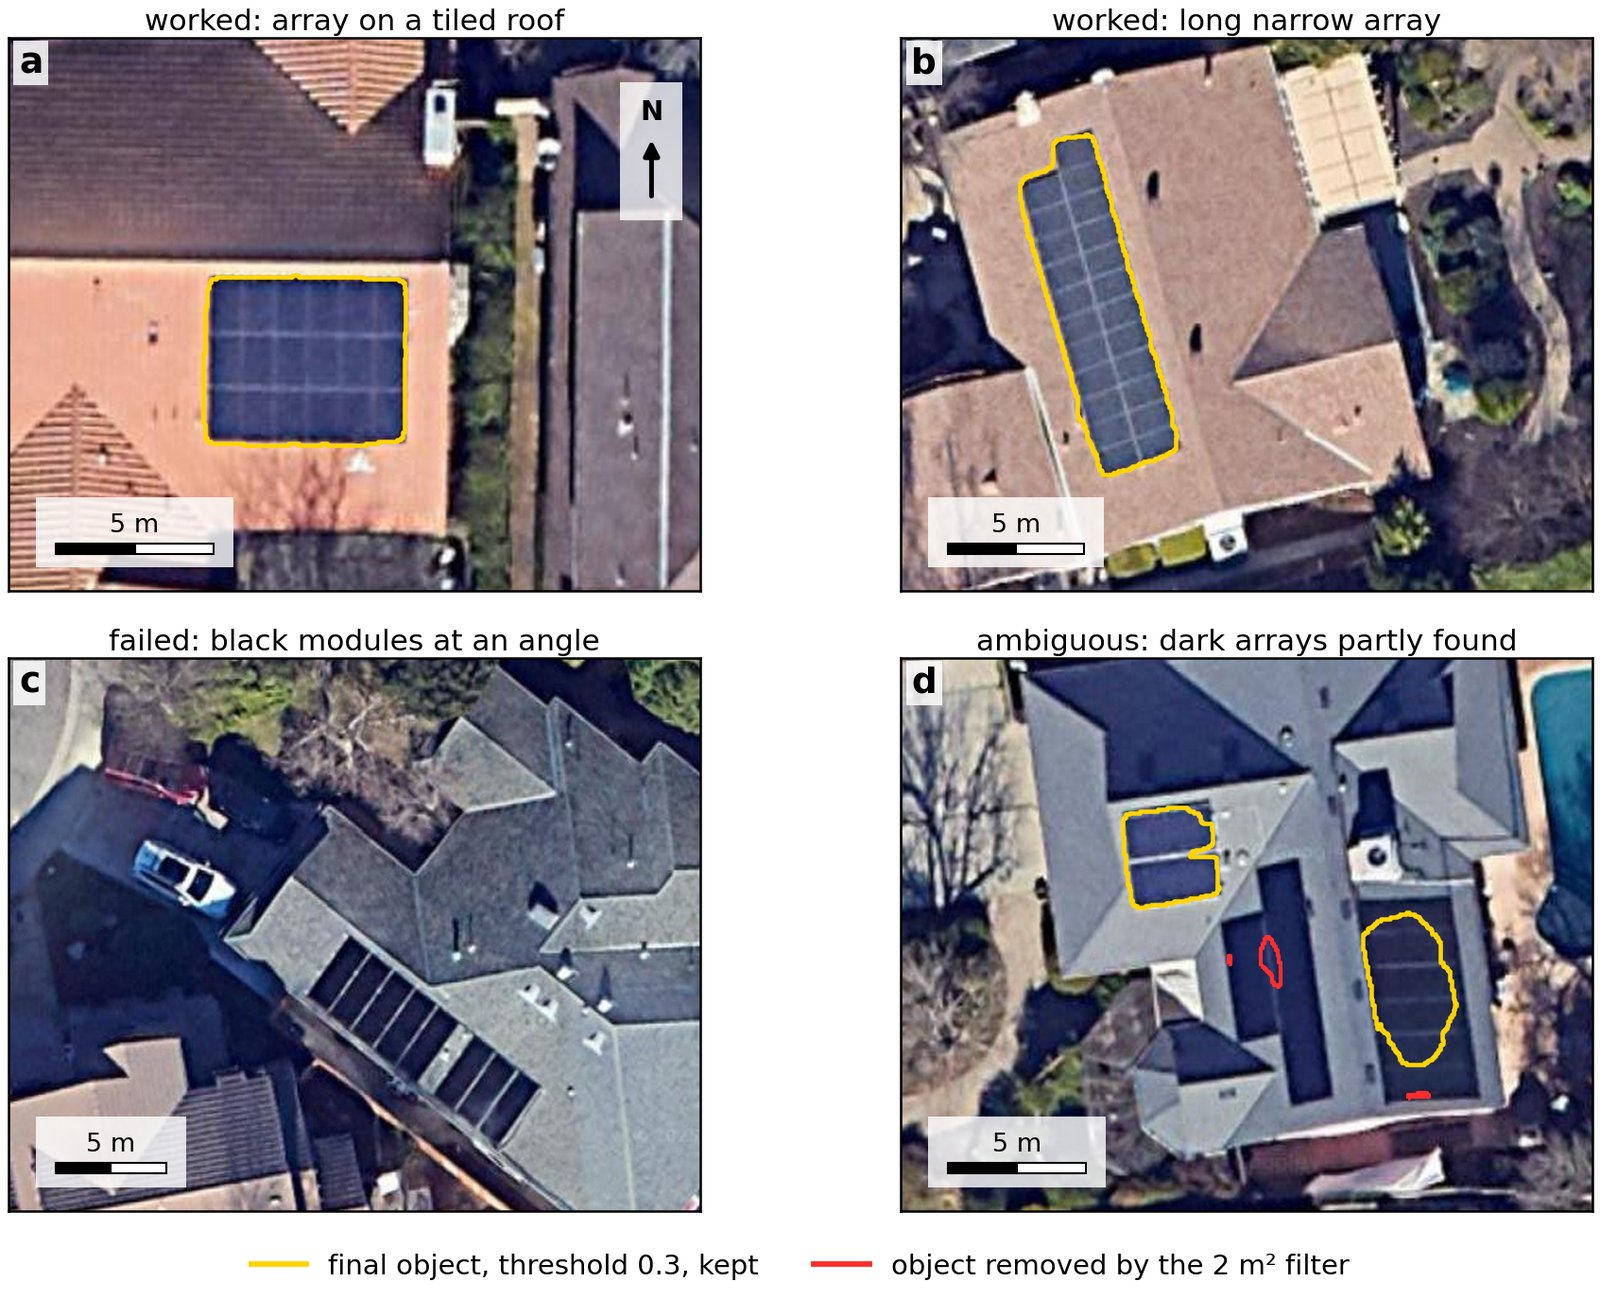

*filtered predictions against the imagery. a and b: arrays outlined correctly. c: a row of black modules at an oblique angle that the model misses. d: dark arrays found only in part, with a fragment removed by the area filter shown in red.*


Q13: Produce a publication-quality figure from your final result and write a short technical paragraph explaining the complete workflow. Your paragraph should describe:

*   how the training data were created
*   how the U-Net was trained and evaluated;
*   how the probability threshold affected the prediction;
*   how raster predictions were converted into objects
*   how geometric filtering changed the final result

Your discussion should distinguish between what the model learned during training and what you achieved through post-processing. Include references to any external materials you used.

As a final reflection: this workflow is semantic segmentation followed by object extraction, rather than a dedicated object-detection model. Explain one advantage and one limitation of this approach for mapping solar panels.

**答案 Q13**（与 proforma `761_Lab5_answer_proforma_rwan407_v2` 同稿）

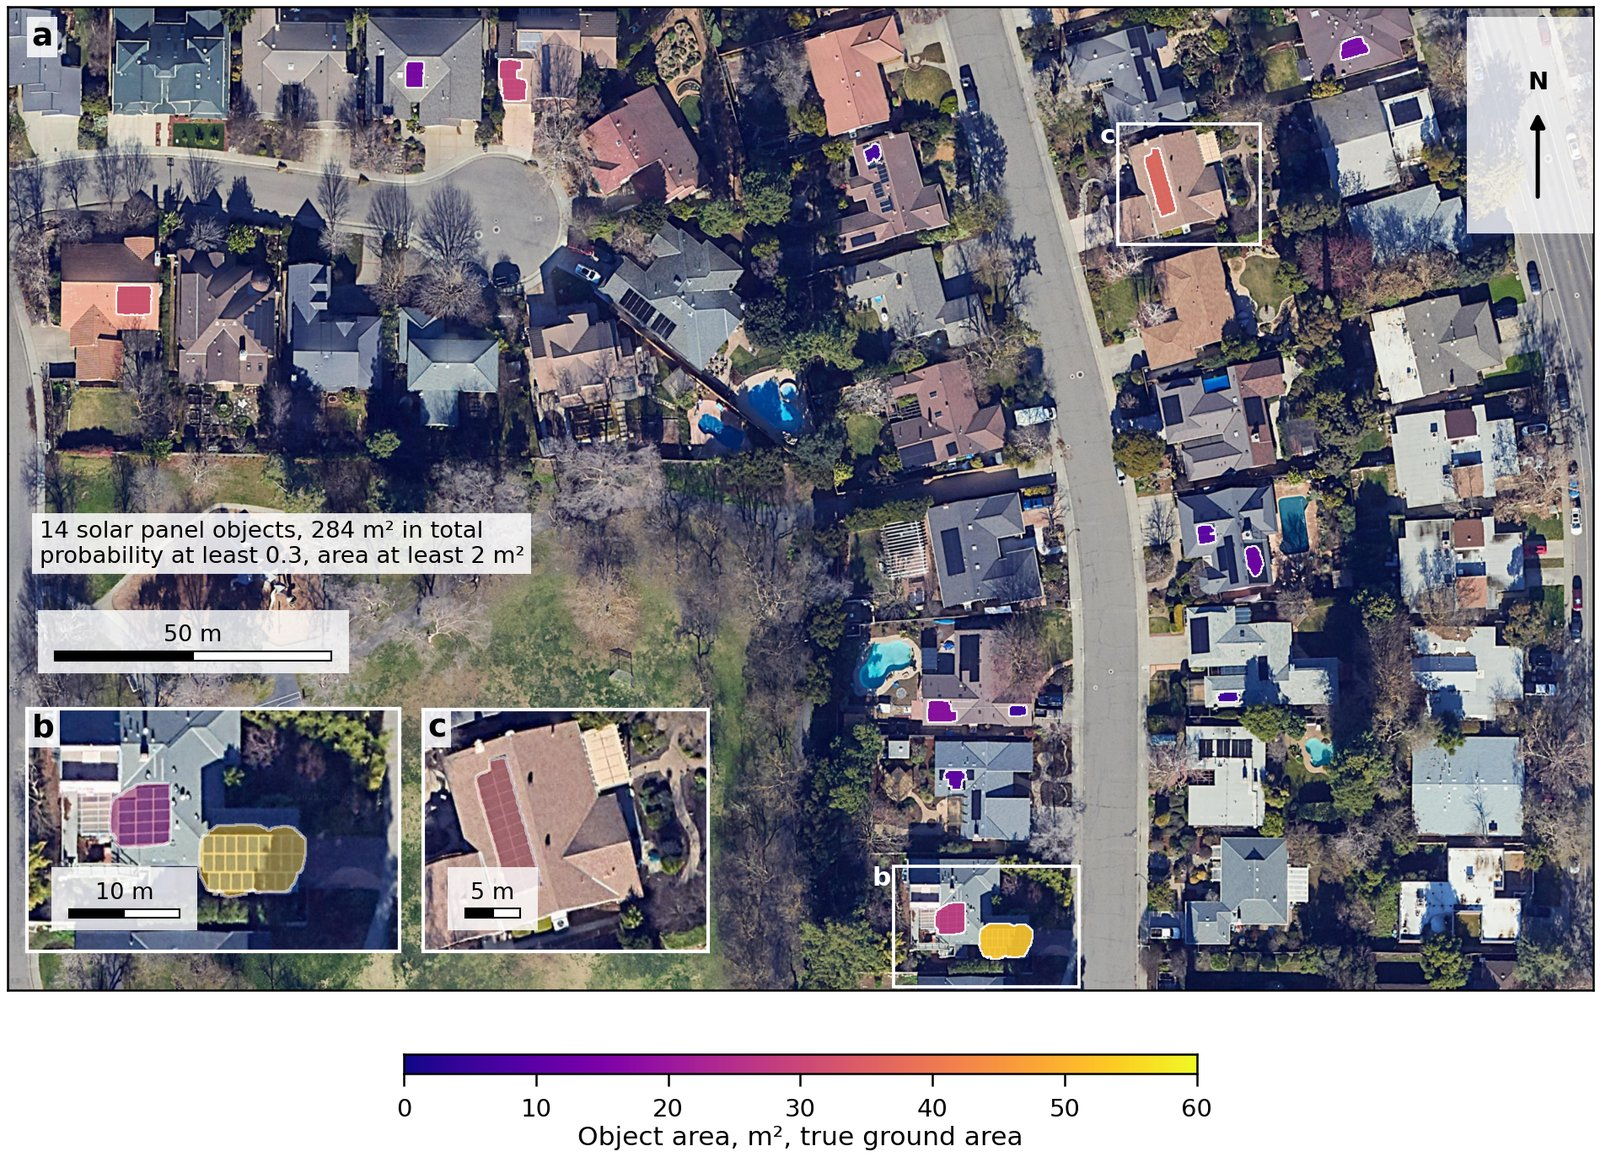

*solar panel objects detected in the unseen Davis test image by the complete workflow: a U-Net trained on the Davis training image, probability threshold 0.3, orthogonalised polygons and a 2 square metre minimum area. Colour shows the true ground area of each object. b and c: enlargements of the boxed areas.*

Figure 9 is the final product: 14 solar panel objects covering 284 square metres on the unseen test image. The training data were made by cutting one 6711 by 3242 pixel aerial RGB image, about 5.8 cm per pixel on the ground, into 312 tiles of 512 by 512 pixels with a stride of 256, and rasterising the 67 hand drawn panel polygons into matching label tiles, so panels made up only 1.4 percent of the training pixels. A U-Net with an ImageNet pretrained ResNet34 encoder was trained on 249 tiles for ten epochs with Adam at a learning rate of 0.001, batches of eight, cross entropy loss and random flips, right angle rotations and brightness changes, and the weights with the best validation IoU, from epoch 9, were kept. GeoAI reports a validation IoU of 0.86 for them, but on the panel class alone the 63 held out tiles give 0.46, with a recall of 0.47. The model was then run over the test image in 512 pixel windows overlapping by 256 pixels, and the overlapping softmax outputs were blended into a probability map with weights that fall towards each window edge. Thresholding that map at 0.3 instead of the default 0.5 raised the panel area from 257 to 287 square metres and completed partly detected arrays at the cost of one small false positive. GeoAI's orthogonalize, adapted from Esri's solar panel post processing, then traced the mask into polygons, simplified each outline with a Douglas Peucker tolerance of 2 map units and squared the corners of rectangular shapes, and I measured every polygon in UTM zone 10N because Web Mercator inflates area by 64 percent here. Finally the 2 square metre minimum area removed 10 of the 24 objects, all specks, fragments or the court artefact, while changing the total area by less than 1 percent.

The steps divide cleanly. What the model learned is contained entirely in the probability map: what panels look like in colour, texture, shape and context, learned from 67 examples in one neighbourhood. The threshold, the rectangular regularisation, the projection used for measurement and the area filter are rules I imposed afterwards. They cut the object count from 24 to 14 and regularised many staircase outlines into rectangles, but they could not recover an array the model never recognised, such as the black modules in Figure 8c, so post processing made the output cleaner, not more complete.

One advantage of semantic segmentation followed by object extraction is that it recovers each array's actual footprint, so area, and with it generating capacity, can be measured directly, and it can be trained from simple polygon labels with a per pixel loss on just 67 examples, whereas a box detector returns only rectangles. One limitation is that the model has no concept of an individual installation: arrays that touch merge into one object, as in Figure 8d, an array split by a shadow becomes several, and the object count depends on thresholds I set rather than on anything learned. Malof et al. 2016 found the same pattern with pixel based detection, strong per pixel but weaker at shape and size, and an instance segmentation model such as Mask R-CNN, He et al. 2017, would learn to separate individual arrays at the cost of instance labels and more data.

**References**

Douglas, D.H. and Peucker, T.K. 1973. Algorithms for the reduction of the number of points required to represent a digitized line or its caricature. Cartographica 10, 112 to 122. https://doi.org/10.3138/FM57-6770-U75U-7727

Esri 2021. Solar Panel Detection USA. ArcGIS Online deep learning package. https://www.arcgis.com/home/item.html?id=c2508d72f2614104bfcfd5ccf1429284

He, K., Gkioxari, G., Dollár, P. and Girshick, R. 2017. Mask R-CNN. Proceedings of the IEEE International Conference on Computer Vision, 2961 to 2969. https://doi.org/10.1109/ICCV.2017.322

Iakubovskii, P. 2019. Segmentation Models Pytorch. GitHub repository. https://github.com/qubvel/segmentation_models.pytorch

Malof, J.M., Bradbury, K., Collins, L.M. and Newell, R.G. 2016. Automatic detection of solar photovoltaic arrays in high resolution aerial imagery. Applied Energy 183, 229 to 240. https://doi.org/10.1016/j.apenergy.2016.08.191

Open Geospatial Solutions 2025. GeoAI Workshop 2025. YouTube video, on which this lab is based. https://www.youtube.com/watch?v=jdK-cleFUkc

Wu, Q. 2026. GeoAI: A Python package for integrating artificial intelligence with geospatial data analysis and visualization. Journal of Open Source Software 11, 9605. https://doi.org/10.21105/joss.09605


> **（自加）报告用图**：上面 geoai 自带的图是快速查看版。proforma 里的出版级图（带比例尺、指北针、图例）由 `lab5_v2/make_figs.py` 读取 `lab5_out/` 的产物重画，数字与本 notebook 完全一致。